In [1]:
# # Cell 1: unzip into a writable folder
# !ls /kaggle/input
# !mkdir -p /kaggle/working/proj
# # !unzip -q /kaggle/input/eeg-nipi-code/eeg_nipi_v2.zip -d /kaggle/working/proj
# !find /kaggle/working/proj -name train.py

In [2]:
# import os
# import shutil

# input_dir = '/kaggle/input'
# datasets = os.listdir(input_dir)
# print(f"Datasets found in Kaggle input: {datasets}")

# if datasets:
#     # Get the exact path of the first dataset attached
#     dataset_path = os.path.join(input_dir, datasets[0]) 
#     dest_path = '/kaggle/working/proj'
    
#     # Clean up destination if it exists from previous failed attempts
#     if os.path.exists(dest_path):
#         shutil.rmtree(dest_path)
        
#     print(f"Copying files from {dataset_path} to {dest_path}...")
#     shutil.copytree(dataset_path, dest_path)
    
#     # Search for train.py to confirm success
#     for root, dirs, files in os.walk(dest_path):
#         if 'train.py' in files:
#             print(f"Success! train.py is located in: {root}")
# else:
#     print("Error: No datasets found. Check the right sidebar to ensure the dataset is attached.")
    

In [3]:
# import os

# # Automatically locate train.py and change to its directory
# train_script = !find /kaggle/working/proj -name train.py

# if train_script:
#     target_dir = os.path.dirname(train_script[0])
#     print(f"Navigating to: {target_dir}")
#     %cd {target_dir}
# else:
#     print("Error: train.py was not found.")

# !pip -q install PyWavelets mne
# !python -c "import torch;print(torch.__version__, torch.cuda.is_available())"

In [4]:
# import os

# # 1. Automatically find and navigate to the directory containing train.py
# train_script = !find /kaggle/working/proj -name train.py
# if train_script:
#     target_dir = os.path.dirname(train_script[0])
#     print(f"Working directory set to: {target_dir}")
#     %cd {target_dir}
# else:
#     print("Error: train.py not found.")

# # 2. Run the specific NIPI model training configurations
# !python train.py --synthetic --epochs 80 --n 1500 --no-line --lam-cov 2.0 --seed 1 --tag _v2s1
# !python train.py --synthetic --epochs 80 --n 1500 --no-line --lam-cov 2.0 --seed 2 --tag _v2s2

# # 3. Zip the outputs for download
# !zip -qr /kaggle/working/results.zip outputs
# print("Training complete and results packed into /kaggle/working/results.zip")

In [5]:
# import os

# # Find where data_real.py is and navigate there
# script_path = !find /kaggle/working/proj -name data_real.py
# if script_path:
#     target_dir = os.path.dirname(script_path[0])
#     print(f"Navigating to: {target_dir}")
#     %cd {target_dir}
# else:
#     print("Error: data_real.py not found.")

# # Create the data folder so the scripts have a place to save the .npz files
# !mkdir -p data

In [6]:
# import glob, os

# # 1. Write the bulletproof version of data_real.py
# new_code = """import argparse, glob, numpy as np, mne
# from eegnipi.montage import CH

# ALIAS = {'T7': 'T3', 'T8': 'T4', 'P7': 'T5', 'P8': 'T6'}

# def norm(n):
#     # Strip 'EEG', periods, and Siena '-REF'/'-LE' suffixes, then uppercase
#     n = n.upper().replace('EEG', '').replace('.', '').replace('-REF', '').replace('-LE', '').strip()
#     return ALIAS.get(n, n)

# def load(edf, mode, fs=128, dur=4.0, stim=1.0, max_min=None):
#     raw = mne.io.read_raw_edf(edf, preload=False, verbose='error')
#     raw.rename_channels(lambda x: x.replace('.', '')) # Kaggle PhysioNet patch
    
#     # Safely match normalized dataset channels against normalized target channels
#     names = {c: norm(c) for c in raw.ch_names}
#     pick = []
#     for w in CH:
#         target = norm(w)
#         try:
#             match = next(k for k, v in names.items() if v == target)
#             pick.append(match)
#         except StopIteration:
#             raise ValueError(f"Missing channel: '{w}'. Dataset has: {list(names.values())}")
            
#     raw.pick(pick); raw.reorder_channels(pick)
#     if max_min: raw.crop(0, min(raw.times[-1], max_min * 60))
#     raw.load_data(verbose='error'); raw.filter(1, 45, verbose='error'); raw.resample(fs, verbose='error')
#     T = int(fs * dur); X, y = [], []
    
#     if mode == 'mi':
#         for o, d in zip(raw.annotations.onset, raw.annotations.description):
#             if d in ('T1', 'T2'):
#                 s = int(round((o - stim) * fs))
#                 if s >= 0 and s + T <= raw.n_times: 
#                     X.append(raw.get_data(start=s, stop=s + T) * 1e6); y.append(int(d == 'T2'))
#     else:
#         D = raw.get_data() * 1e6
#         for s in range(0, D.shape[1] - T + 1, T): X.append(D[:, s:s + T]); y.append(0)
#     return np.array(X, np.float32).reshape(-1, len(CH), T), np.array(y, int)

# def is_clean(e, fs=128):
#     from scipy.signal import welch
#     f, P = welch(e, fs, nperseg=128, axis=-1); hf = P[:, f > 25].sum(1) / P.sum(1)
#     return (np.ptp(e, axis=-1).max() < 100) and (hf.max() < 0.15)

# if __name__ == '__main__':
#     p = argparse.ArgumentParser(); p.add_argument('--edf', nargs='+'); p.add_argument('--out'); p.add_argument('--mode', default='mi')
#     p.add_argument('--max-min', type=float, default=None); a = p.parse_args()
#     files = sorted({f for pat in a.edf for f in glob.glob(pat)}); print(len(files), 'files found')
#     XS, YS = [], []
#     for f in files:
#         try: 
#             x, y = load(f, a.mode, max_min=a.max_min); XS.append(x); YS.append(y)
#             print(' ', f.split('/')[-1], len(x), 'epochs')
#         except Exception as e: print('  SKIPPED', f.split('/')[-1], '->', str(e)[:150])
    
#     if len(XS) == 0:
#         print("ERROR: All files were skipped.")
#         exit(1)
        
#     X, y = np.concatenate(XS), np.concatenate(YS); keep = np.array([is_clean(e) for e in X]); X, y = X[keep], y[keep]
#     print(f'kept {keep.sum()}/{len(keep)} artifact-free epochs; class counts: {np.bincount(y)}; shape {X.shape}; std {X.std():.1f} uV')
#     import os; os.makedirs(os.path.dirname(a.out) or '.', exist_ok=True); np.savez(a.out, X=X, y=y, fs=128)
# """

# with open('data_real.py', 'w') as f:
#     f.write(new_code)
# print("Saved corrected data_real.py\n")

# # 2. Extract PhysioNet (Motor Imagery)
# print("--- Processing PhysioNet ---")
# files = []
# for f in glob.glob('/kaggle/input/**/S*R*.edf', recursive=True):
#     b = os.path.basename(f)
#     if b[4:7] in ('R04', 'R08', 'R12') and 1 <= int(b[1:4]) <= 20: 
#         files.append(f)

# if files:
#     !python data_real.py --mode mi --out data/mi_clean.npz --edf {' '.join(sorted(files))}
# else:
#     print("0 PhysioNet files found.")

# # 3. Extract Siena Dataset
# print("\n--- Processing Siena ---")
# siena = sorted(glob.glob('/kaggle/input/**/PN0*-*.edf', recursive=True))[:6]

# if siena:
#     !python data_real.py --mode continuous --max-min 10 --out data/siena_clean.npz --edf {' '.join(siena)}
# else:
#     print("0 Siena files found.")

In [7]:
# import numpy as np, glob, sys
# sys.path.insert(0, '.')
# from data_real import load
# from scipy.signal import welch
# def stats(X, fs=128):
#     ptp = np.ptp(X, axis=-1).max(1)                              # worst channel peak-to-peak per epoch
#     f, P = welch(X, fs, nperseg=128, axis=-1); hf = (P[..., f > 25].sum(-1) / P.sum(-1)).max(1)
#     return ptp, hf
# sets = {'MI': [load(f, 'mi')[0] for f in sorted(glob.glob('/kaggle/input/**/S0[0-1][0-9]R04.edf', recursive=True))[:6]],
#         'Siena': [load(f, 'continuous', max_min=10)[0] for f in sorted(glob.glob('/kaggle/input/**/PN0*-*.edf', recursive=True))[:3]]}
# for name, L in sets.items():
#     X = np.concatenate(L); ptp, hf = stats(X); print(name, 'epochs', len(X))
#     print('  peak-to-peak uV, percentiles 10/25/50/75/90:', np.percentile(ptp, [10, 25, 50, 75, 90]).round(0))
#     print('  HF fraction, percentiles 10/25/50/75/90:', np.percentile(hf, [10, 25, 50, 75, 90]).round(3))
#     for p_, h_ in [(100, .15), (150, .15), (100, .25), (150, .25), (200, .30)]:
#         print(f'  keep if ptp<{p_} and hf<{h_}:', ((ptp < p_) & (hf < h_)).mean().round(2))

In [8]:
# import numpy as np, glob, os, sys
# sys.path.insert(0, '.')
# from data_real import load
# from scipy.signal import welch
# os.makedirs('data', exist_ok=True)
# def collect(files, mode, **kw):
#     Xs, Ys, S = [], [], []
#     for f in files:
#         try: x, y = load(f, mode, **kw); Xs.append(x); Ys.append(y); S += [os.path.basename(f)[:4]] * len(x)
#         except Exception as e: print('skip', os.path.basename(f), str(e)[:80])
#     return np.concatenate(Xs), np.concatenate(Ys), np.array(S)
# mi = sorted(f for f in glob.glob('/kaggle/input/**/S*R*.edf', recursive=True)
#             if os.path.basename(f)[4:7] in ('R04', 'R08', 'R12') and 1 <= int(os.path.basename(f)[1:4]) <= 20)
# Xm, ym, sm = collect(mi, 'mi'); np.savez('data/mi_all.npz', X=Xm, y=ym, subj=sm, fs=128)
# sie = sorted(glob.glob('/kaggle/input/**/PN0*-*.edf', recursive=True))[:6]
# Xs, ys, ss = collect(sie, 'continuous', max_min=10); np.savez('data/siena_all.npz', X=Xs, y=ys, subj=ss, fs=128)
# def stats(X, q):
#     ptp = np.quantile(np.ptp(X, axis=-1), q, axis=1)
#     f, P = welch(X, 128, nperseg=128, axis=-1); hf = np.quantile(P[..., f > 25].sum(-1) / P.sum(-1), q, axis=1)
#     return ptp, hf
# for name, X in [('MI', Xm), ('Siena', Xs)]:
#     print(name, len(X), 'epochs')
#     for q in (1.0, 0.9, 0.75):
#         ptp, hf = stats(X, q)
#         print(f'  channel quantile {q}: ptp pct10/50/90', np.percentile(ptp, [10, 50, 90]).round(0), ' hf pct10/50/90', np.percentile(hf, [10, 50, 90]).round(2))
#         for p_, h_ in [(100, .15), (150, .25), (200, .30), (300, .35)]:
#             print(f'    keep if ptp<{p_} and hf<{h_}: {((ptp < p_) & (hf < h_)).mean():.2f}')

In [9]:
# import numpy as np
# from scipy.signal import welch
# def keep_mask(X, q=0.9, ptp_max=150, hf_max=0.25, cap=500):
#     p = np.ptp(X, axis=-1)
#     f, P = welch(X, 128, nperseg=128, axis=-1); hf = P[..., f > 25].sum(-1) / P.sum(-1)
#     return (np.quantile(p, q, axis=1) < ptp_max) & (np.quantile(hf, q, axis=1) < hf_max) & (p.max(1) < cap)
# for name in ('mi', 'siena'):
#     d = np.load(f'data/{name}_all.npz'); m = keep_mask(d['X'])
#     print(name, 'kept', m.sum(), 'of', len(m), '| classes', np.bincount(d['y'][m]), '| subjects', len(set(d['subj'][m])), '| std uV', d['X'][m].std().round(1))
#     np.savez(f'data/{name}_clean.npz', X=d['X'][m], y=d['y'][m], fs=128)

In [10]:
# import os, shutil
# dest_path = '/kaggle/working/proj'

# # Clear old code and copy the newly updated dataset
# if os.path.exists(dest_path): shutil.rmtree(dest_path)
# !mkdir -p {dest_path}
# !cp -r /kaggle/input/eeg*/* {dest_path}/

# # Navigate to the correct directory
# train_script = !find /kaggle/working/proj -name train.py
# if train_script:
#     %cd {os.path.dirname(train_script[0])}
#     print("Successfully loaded updated train.py!")
# else:
#     print("Error: train.py not found.")

In [11]:
# import numpy as np, glob, os, sys, collections
# sys.path.insert(0, '.')
# from data_real import load
# from scipy.signal import welch
# def keep_mask(X, q=0.9, ptp_max=150, hf_max=0.25, cap=500):
#     p = np.ptp(X, axis=-1)
#     f, P = welch(X, 128, nperseg=128, axis=-1); hf = P[..., f > 25].sum(-1) / P.sum(-1)
#     return (np.quantile(p, q, axis=1) < ptp_max) & (np.quantile(hf, q, axis=1) < hf_max) & (p.max(1) < cap)
# by = collections.defaultdict(list)
# for f in sorted(glob.glob('/kaggle/input/**/PN*-*.edf', recursive=True)): by[os.path.basename(f)[:4]].append(f)
# print({k: len(v) for k, v in by.items()})
# sie = [f for k in sorted(by) for f in by[k][:2]]
# Xs, S = [], []
# for f in sie:
#     try: x, _ = load(f, 'continuous', max_min=10); Xs.append(x); S += [os.path.basename(f)[:4]] * len(x)
#     except Exception as e: print('skip', os.path.basename(f), str(e)[:80])
# X = np.concatenate(Xs); S = np.array(S); m = keep_mask(X)
# print('siena kept', m.sum(), 'of', len(m), '| patients', len(set(S[m])), '| per patient', dict(collections.Counter(S[m])), '| std uV', X[m].std().round(1))

# # Create the 'data' directory if it doesn't exist
# os.makedirs('data', exist_ok=True) 
# np.savez('data/siena_clean.npz', X=X[m], y=np.zeros(m.sum(), int), subj=S[m], fs=128)

In [12]:
# import os, shutil

# input_dir = None
# for root, dirs, files in os.walk('/kaggle/input'):
#     if 'train.py' in files:
#         input_dir = root
#         break

# dest_path = '/kaggle/working/proj'
# os.makedirs(dest_path, exist_ok=True)

# if input_dir:
#     shutil.copytree(input_dir, dest_path, dirs_exist_ok=True)
#     os.chdir(dest_path)
#     print(f"Code copied successfully. Working directory is now: {os.getcwd()}")
    
#     if os.path.exists('data/siena_clean.npz') and os.path.exists('data/mi_clean.npz'):
#         print("Clean data arrays found! Proceed to Step 2.")
#     else:
#         print("WARNING: Clean data missing. You may need to re-run the data extraction.")
# else:
#     print("Error: train.py not found in /kaggle/input/")

In [13]:
# nipi_path = 'eegnipi/nipi.py'

# if os.path.exists(nipi_path):
#     with open(nipi_path, 'r') as f:
#         lines = f.readlines()
    
#     with open(nipi_path, 'w') as f:
#         for line in lines:
#             f.write(line)
#             if line.strip().startswith('def task_retention('):
#                 f.write("    import numpy as np\n    if len(np.unique(labels)) < 2: return np.nan, np.nan, np.nan\n")
                
#     print("Patched eegnipi/nipi.py successfully. The single-class crash is fixed. Proceed to Step 3.")
# else:
#     print(f"Error: {nipi_path} not found.")

In [14]:
# print("Starting cross-dataset training...")
# !python train.py --data data/siena_clean.npz --test-data data/mi_clean.npz --epochs 80 --no-line --lam-cov 2.0 --tag _real

In [15]:
# import pandas as pd
# d = pd.read_csv('outputs/final_comparison_real.csv')
# for v in ('ARR', 'NIPI', 'Joint'):
#     print(v); print(d.pivot_table(index='method', columns='kind', values=v).round(3))
# nl = d[d.kind != 'line']
# print('excluding line noise'); print(nl.groupby('method')[['ARR', 'CC', 'NIPI', 'Joint']].mean().round(3).sort_values('Joint', ascending=False))
# print(d[['method', 'task', 'erp']].groupby('method').mean().round(3))

In [16]:
# import numpy as np, glob, os, sys
# sys.path.insert(0, '.')
# from data_real import load
# from scipy.signal import welch
# def keep_mask(X, q=0.9, ptp_max=150, hf_max=0.25, cap=500):
#     p = np.ptp(X, axis=-1)
#     f, P = welch(X, 128, nperseg=128, axis=-1); hf = P[..., f > 25].sum(-1) / P.sum(-1)
#     return (np.quantile(p, q, axis=1) < ptp_max) & (np.quantile(hf, q, axis=1) < hf_max) & (p.max(1) < cap)
# mi2 = sorted(f for f in glob.glob('/kaggle/input/**/S*R*.edf', recursive=True)
#              if os.path.basename(f)[4:7] in ('R04', 'R08', 'R12') and 21 <= int(os.path.basename(f)[1:4]) <= 60)
# Xs, S = [], []
# for f in mi2:
#     try: x, _ = load(f, 'mi'); Xs.append(x); S += [os.path.basename(f)[:4]] * len(x)
#     except Exception as e: print('skip', os.path.basename(f), str(e)[:80])
# Xm2 = np.concatenate(Xs); S = np.array(S); m = keep_mask(Xm2)
# print('MI training subjects: kept', m.sum(), 'of', len(m), '| subjects', len(set(S[m])))
# sie = np.load('data/siena_clean.npz')
# X = np.concatenate([sie['X'], Xm2[m]]); y = np.zeros(len(X), int)
# np.savez('data/train_mix.npz', X=X, y=y, fs=128); print('train_mix', X.shape)

In [17]:
# import numpy as np
# from scipy.signal import welch
# from sklearn.linear_model import LogisticRegression
# from sklearn.model_selection import StratifiedKFold, cross_val_score
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# from eegnipi.montage import IDX
# d = np.load('data/mi_clean.npz'); X, y = d['X'], d['y']
# f, P = welch(X, 128, nperseg=128, axis=-1)
# def bp(lo, hi): return np.log(P[..., (f >= lo) & (f < hi)].mean(-1) + 1e-12)
# mu, be = bp(8, 13), bp(13, 30); c3, c4, cz = IDX['C3'], IDX['C4'], IDX['Cz']
# feats = {'lateral mu+beta': np.c_[mu[:, c4] - mu[:, c3], be[:, c4] - be[:, c3]],
#          'C3/C4/Cz mu+beta': np.c_[mu[:, [c3, c4, cz]], be[:, [c3, c4, cz]]],
#          'all-channel mu+beta': np.c_[mu, be]}
# cv = StratifiedKFold(5, shuffle=True, random_state=0)
# for k, F in feats.items():
#     a = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)), F, y, cv=cv).mean()
#     print(f'{k}: accuracy {a:.2f}  (chance 0.50)')

In [18]:
# !python train.py --data data/train_mix.npz --test-data data/mi_clean.npz --epochs 80 --no-line --lam-cov 2.0 --tag _real2

In [19]:
# import traceback, importlib, sys
# s = open('data_real.py').read()
# print('channel-matching line:', [l.strip()[:110] for l in s.splitlines() if 'pick' in l and 'next(' in l or 'target = norm' in l])
# if 'v == w' in s:
#     s = s.replace('v == w', 'v == norm(w)'); open('data_real.py', 'w').write(s); print('PATCHED the old channel matching')
# for k in [k for k in sys.modules if k == 'data_real']: del sys.modules[k]
# import data_real
# try: x, _ = data_real.load(files[0], 'continuous'); print('OK', x.shape)
# except Exception: traceback.print_exc()

In [20]:
# import numpy as np, glob, os
# from data_real import load
# from eegnipi.nipi import _features
# from scipy.signal import welch
# from sklearn.linear_model import LogisticRegression
# from sklearn.model_selection import StratifiedKFold, cross_val_score
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# def keep_mask(X, q=0.9, ptp_max=150, hf_max=0.25, cap=500):
#     p = np.ptp(X, axis=-1)
#     f, P = welch(X, 128, nperseg=128, axis=-1); hf = P[..., f > 25].sum(-1) / P.sum(-1)
#     return (np.quantile(p, q, axis=1) < ptp_max) & (np.quantile(hf, q, axis=1) < hf_max) & (p.max(1) < cap)
# sid = lambda f: int(os.path.basename(f)[1:4])
# files = sorted(f for f in glob.glob('/kaggle/input/**/S*R0[12].edf', recursive=True) if sid(f) <= 20 or sid(f) >= 61)
# Xs, ys = [], []
# for f in files:
#     try: x, _ = load(f, 'continuous'); Xs.append(x); ys += [0 if 'R01' in os.path.basename(f) else 1] * len(x)
#     except Exception as e: print('skip', os.path.basename(f), repr(e)[:150])
# X = np.concatenate(Xs); y = np.array(ys); m = keep_mask(X); print('kept', m.sum(), 'of', len(m), '| per class', np.bincount(y[m])); X, y = X[m], y[m]
# n = min(np.bincount(y)); rng = np.random.default_rng(0)
# idx = np.sort(np.concatenate([rng.choice(np.where(y == c)[0], n, replace=False) for c in (0, 1)])); X, y = X[idx], y[idx]
# acc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)), _features(X, 128), y, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
# print('eyes-open/closed epochs', len(y), '| classes', np.bincount(y), '| clean decoding accuracy', round(acc, 2))
# np.savez('data/eoec_clean.npz', X=X, y=y, fs=128)

In [21]:
# def rep(path, a, b):
#     s = open(path).read()
#     if b in s: print('already patched:', a[:40]); return
#     assert a in s, ('NOT FOUND', a[:60]); open(path, 'w').write(s.replace(a, b, 1)); print('patched:', a[:40])
# rep('train.py', "p.add_argument('--test-data', default=None);", "p.add_argument('--test-data', default=None); p.add_argument('--drop', nargs='*', default=[]); p.add_argument('--eval-tag', default=None);")
# rep('train.py', "from eegnipi.nipi import nipi, artifact_suppression, joint_score", "from eegnipi.nipi import nipi, artifact_suppression, joint_score, COMPONENTS")
# rep('train.py', "print('train', len(tr), 'val', len(va), 'test', len(Xte))", "print('train', len(tr), 'val', len(va), 'test', len(Xte)); PARTS = [c for c in COMPONENTS if c not in a.drop]")
# rep('train.py', "evaluate_methods(Xte, yte, methods, fs, kind, snr, verbose=False)", "evaluate_methods(Xte, yte, methods, fs, kind, snr, verbose=False, parts=PARTS)")
# rep('train.py', "res.to_csv(f'outputs/final_comparison{a.tag}.csv', index=False)", "res.to_csv(f'outputs/final_comparison{a.eval_tag if a.eval_tag is not None else a.tag}.csv', index=False)")
# rep('eegnipi/evaluate.py', "seed=1, verbose=True):", "seed=1, verbose=True, parts=None):")
# rep('eegnipi/evaluate.py', "n = nipi(clean, den, labels, fs)", "n = nipi(clean, den, labels, fs, parts=parts) if parts else nipi(clean, den, labels, fs)")
# rep('eegnipi/evaluate.py', "{k: n[k] for k in", "{k: n.get(k, float('nan')) for k in")

In [22]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 0 --no-line --tag _real2 --eval-tag _real2_eoec --drop erp

In [23]:
# import pandas as pd
# d = pd.read_csv('outputs/final_comparison_real2_eoec.csv')
# for v in ('NIPI', 'Joint'):
#     print(v); print(d.pivot_table(index='method', columns='kind', values=v).round(3))
# nl = d[d.kind != 'line']
# print('excluding line noise'); print(nl.groupby('method')[['ARR', 'CC', 'NIPI', 'Joint']].mean().round(3).sort_values('Joint', ascending=False))
# print('components, excluding line'); print(nl.groupby('method')[['spectral', 'phase', 'connect', 'geometry', 'entropy', 'task']].mean().round(3))

In [24]:
# import numpy as np, torch, matplotlib.pyplot as plt, sys
# sys.path.insert(0, '.')
# from eegnipi.model import NIPDNet
# import eegnipi.artifacts as AM
# from eegnipi.baselines import ica, nlms
# from eegnipi.montage import IDX
# from scipy.signal import welch
# AM.MIXED = ['eog', 'emg']; fs = 128
# X = np.load('data/mi_clean.npz')['X'][:60]
# noisy, art, refs = AM.contaminate(X, 'mixed', 0, fs, seed=5)
# net = NIPDNet(); net.load_state_dict(torch.load('outputs/best_nipdnet_real2.pt', map_location='cpu')); net.eval()
# with torch.no_grad(): prop = net(torch.tensor(noisy))[0].numpy()
# outs = {'Clean (reference)': X, 'Noisy': noisy, 'ICA': ica(noisy, refs, fs), 'NLMS': nlms(noisy, refs, fs), 'Proposed': prop}
# i = 3; t = np.arange(X.shape[-1]) / fs
# fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
# for a_, ch in zip(ax, ['Fp1', 'C3', 'Pz']):
#     for k, v in outs.items(): a_.plot(t, v[i, IDX[ch]], label=k, lw=1.6 if k == 'Proposed' else 0.9)
#     a_.set_ylabel(ch + ' (uV)')
# ax[0].legend(ncol=5, fontsize=8); ax[-1].set_xlabel('time (s)'); plt.tight_layout(); plt.savefig('outputs/real_epoch_example.png', dpi=150)
# fig, a_ = plt.subplots(figsize=(6, 4))
# for k, v in outs.items():
#     f, P = welch(v, fs, nperseg=128, axis=-1); a_.semilogy(f, P.mean((0, 1)), label=k)
# a_.set_xlim(0, 45); a_.set_xlabel('Hz'); a_.set_ylabel('PSD'); a_.legend(fontsize=8); plt.tight_layout(); plt.savefig('outputs/real_psd.png', dpi=150)
# print('saved outputs/real_epoch_example.png and outputs/real_psd.png')

In [25]:
# sty = {'Clean (reference)': dict(color='k', lw=2.6, alpha=0.30), 'Noisy': dict(color='tab:orange', lw=0.9),
#        'ICA': dict(color='tab:green', lw=0.9, ls='--'), 'NLMS': dict(color='tab:red', lw=0.9, ls=':'), 'Proposed': dict(color='tab:purple', lw=1.7)}
# fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# for a_, ch in zip(ax, ['Fp1', 'C3', 'Pz']):
#     for k, v in outs.items(): a_.plot(t, v[i, IDX[ch]], label=k, **sty[k])
#     a_.set_ylabel(ch + ' (uV)')
# ax[0].legend(ncol=5, fontsize=8); ax[-1].set_xlabel('time (s)'); plt.tight_layout(); plt.savefig('outputs/real_epoch_example2.png', dpi=150)
# fig, a_ = plt.subplots(figsize=(6, 4))
# for k, v in outs.items():
#     f, P = welch(v, fs, nperseg=128, axis=-1); a_.semilogy(f, P.mean((0, 1)), label=k, **sty[k])
# a_.set_xlim(1, 45); a_.set_ylim(0.5, 200); a_.set_xlabel('Hz'); a_.set_ylabel('PSD'); a_.legend(fontsize=8); plt.tight_layout(); plt.savefig('outputs/real_psd2.png', dpi=150)

In [26]:
# def rep(path, a, b):
#     s = open(path).read()
#     if b in s: print('already patched'); return
#     assert a in s, ('NOT FOUND', a[:60]); open(path, 'w').write(s.replace(a, b, 1)); print('patched')
# rep('train.py', "p.add_argument('--drop', nargs='*', default=[]);", "p.add_argument('--drop', nargs='*', default=[]); p.add_argument('--zero', nargs='*', default=[]);")
# rep('train.py', "lam = dict(rec=1.0,", "lam = dict(rec=1.0,")
# s = open('train.py').read()
# if "for k_ in a.zero" not in s:
#     s = s.replace("MAP = dict(", "for k_ in a.zero: lam[k_] = 0.0\nMAP = dict(", 1)
#     s = s.replace("if comp in r and not np.isnan(r[comp]): lam[k]", "if comp in r and not np.isnan(r[comp]) and k not in a.zero: lam[k]", 1)
#     open('train.py', 'w').write(s)
# print('zero option present:', "for k_ in a.zero" in open('train.py').read(), "k not in a.zero" in open('train.py').read())

In [27]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --drop erp --zero info --tag _abl_info

In [28]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --drop erp --zero phase conn --tag _abl_phaseconn

In [29]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --drop erp --zero cov --tag _abl_cov

In [30]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --drop erp --zero spec --tag _abl_spec

In [31]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --drop erp --zero graph --tag _abl_graph

In [32]:
# def rep(path, a, b):
#     s = open(path).read()
#     if b in s: print('already patched'); return
#     assert a in s, ('NOT FOUND', a[:60]); open(path, 'w').write(s.replace(a, b, 1)); print('patched')
# rep('train.py', "p.add_argument('--zero', nargs='*', default=[]);", "p.add_argument('--zero', nargs='*', default=[]); p.add_argument('--lam-scale', type=float, default=1.0);")
# rep('train.py', "for k_ in a.zero: lam[k_] = 0.0", "for k_ in lam:\n    if k_ not in ('rec', 'type'): lam[k_] *= a.lam_scale\nfor k_ in a.zero: lam[k_] = 0.0")
# rep('train.py', "0.05, 5.0)", "0.05, 5.0 * max(1.0, a.lam_scale))")

In [33]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --drop erp --zero spec phase conn cov graph info --tag _abl_none

In [34]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --lam-scale 4 --drop erp --tag _lamx4

In [35]:
# !python train.py --data data/train_mix.npz --test-data data/mi_clean.npz --epochs 0 --no-line --tag _lamx4 --eval-tag _lamx4_mi

In [36]:
# !python train.py --data data/train_mix.npz --test-data data/mi_clean.npz --epochs 0 --no-line --tag _abl_none --eval-tag _abl_none_mi

In [37]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --lam-scale 4 --drop erp --seed 1 --tag _lamx4_s1

In [38]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --lam-scale 4 --drop erp --seed 2 --tag _lamx4_s2

In [39]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --drop erp --zero spec phase conn cov graph info --seed 1 --tag _abl_none_s1

In [40]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --drop erp --zero spec phase conn cov graph info --seed 2 --tag _abl_none_s2

In [41]:
# %%writefile physio_validation.py
# """Stage-3 PHYSIOLOGICAL VALIDATION on NATURALLY contaminated real epochs (no clean reference needed).
# Epochs that failed the clean-epoch rule are 'contaminated'. For every method we ask: are known neural biomarkers preserved
# while real artifacts are suppressed?
#   EO/EC (PhysioNet R01/R02):  (a) alpha reactivity (EC - EO, occipital) vs the value measured on clean epochs,
#                               (b) EO-vs-EC decoding accuracy, subject-wise GroupKFold, on ALL epochs and on CONTAMINATED epochs only,
#                               (c) on contaminated epochs, ratio to raw: frontal 1-4 Hz (blink), temporal 30-45 Hz (muscle),
#                                   occipital alpha (should stay ~1), central mu (should stay ~1)
#   Motor imagery:               left-vs-right mu lateralisation effect size (Cohen d) on all / contaminated epochs
# usage:
#   python physio_validation.py --eoec data/eoec_all.npz --mi data/mi_all.npz --ckpt outputs/best_nipdnet_lamx4.pt --out outputs/physio
#   (omit --ckpt to run the classical methods only; omit --eoec or --mi to skip that part)"""
# import argparse, os, numpy as np, pandas as pd
# from scipy.signal import welch
# from sklearn.linear_model import LogisticRegression
# from sklearn.model_selection import GroupKFold, cross_val_score
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# from eegnipi.montage import IDX
# from eegnipi.nipi import _features
# import eegnipi.baselines as B
# FS = 128

# def keep_mask(X, q=0.9, ptp_max=150, hf_max=0.25, cap=500):        # the SAME clean-epoch rule used everywhere else
#     p = np.ptp(X, axis=-1)
#     f, P = welch(X, FS, nperseg=128, axis=-1); hf = P[..., f > 25].sum(-1) / P.sum(-1)
#     return (np.quantile(p, q, axis=1) < ptp_max) & (np.quantile(hf, q, axis=1) < hf_max) & (p.max(1) < cap)

# def bandpow(X, lo, hi):
#     f, P = welch(X, FS, nperseg=128, axis=-1); return P[..., (f >= lo) & (f < hi)].mean(-1)       # (N, C)
# def chs(names): return [IDX[n] for n in names]

# def get_methods(ckpt):
#     M = {'Raw': lambda x: x, 'ICA': lambda x: B.ica(x, None, FS)}
#     try: import pywt; M['Wavelet'] = lambda x: B.wavelet(x, None, FS)
#     except ImportError: print('PyWavelets missing -> Wavelet skipped')
#     if ckpt:
#         import torch
#         from eegnipi.model import NIPDNet
#         dev = 'cuda' if torch.cuda.is_available() else 'cpu'
#         net = NIPDNet(); net.load_state_dict(torch.load(ckpt, map_location='cpu')); net.to(dev).eval()
#         def prop(x):
#             out = []
#             with torch.no_grad():
#                 for i in range(0, len(x), 64): out.append(net(torch.tensor(x[i:i + 64], dtype=torch.float32, device=dev))[0].cpu().numpy())
#             return np.concatenate(out)
#         M['Proposed'] = prop
#     return M

# def decode(F, y, groups):
#     clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
#     return float(cross_val_score(clf, F, y, cv=GroupKFold(min(5, len(np.unique(groups)))), groups=groups).mean())

# def eoec_report(X, y, subj, clean, methods):
#     occ, fr, tmp, ctr = chs(['O1', 'O2', 'Pz']), chs(['Fp1', 'Fp2']), chs(['T3', 'T4', 'F7', 'F8']), chs(['C3', 'Cz', 'C4'])
#     alpha = lambda Xm: np.log10(bandpow(Xm, 8, 13)[:, occ].mean(1))
#     react = lambda a, idx: a[idx & (y == 1)].mean() - a[idx & (y == 0)].mean()
#     raw = X; ref = react(alpha(raw), clean)
#     print(f'EO/EC: {len(y)} epochs, {(~clean).sum()} contaminated, {len(np.unique(subj))} subjects; reference alpha reactivity (clean epochs, raw) = {ref:.3f} log10 units')
#     rows = []
#     for name, fn in methods.items():
#         Xm = raw if name == 'Raw' else fn(raw); a = alpha(Xm); c = ~clean
#         r = dict(method=name, alpha_react=react(a, np.ones(len(y), bool)), alpha_react_err=abs(react(a, np.ones(len(y), bool)) - ref),
#                  acc_all=decode(_features(Xm, FS), y, subj), acc_contam=decode(_features(Xm[c], FS), y[c], subj[c]))
#         def ratio(chn, lo, hi): return float(np.median(bandpow(Xm[c], lo, hi)[:, chn].mean(1) / bandpow(raw[c], lo, hi)[:, chn].mean(1)))
#         r.update(frontal_slow_ratio=ratio(fr, 1, 4), temporal_hf_ratio=ratio(tmp, 30, 45), occ_alpha_ratio=ratio(occ, 8, 13), central_mu_ratio=ratio(ctr, 8, 13))
#         rows.append(r)
#     return pd.DataFrame(rows), ref

# def mi_report(X, y, subj, clean, methods):
#     c3, c4 = IDX['C3'], IDX['C4']
#     def li(Xm):
#         mu = np.log10(bandpow(Xm, 8, 13)); l = mu[:, c4] - mu[:, c3]
#         for s in np.unique(subj): l[subj == s] -= l[subj == s].mean()            # remove each subject's own baseline asymmetry
#         return l
#     def d(l, yy): a, b = l[yy == 0], l[yy == 1]; return float((a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2))
#     rows = []
#     for name, fn in methods.items():
#         Xm = X if name == 'Raw' else fn(X); l = li(Xm)
#         rows.append(dict(method=name, d_all=d(l, y), d_contam=d(l[~clean], y[~clean]), d_clean=d(l[clean], y[clean])))
#     return pd.DataFrame(rows)

# if __name__ == '__main__':
#     p = argparse.ArgumentParser(); p.add_argument('--eoec'); p.add_argument('--mi'); p.add_argument('--ckpt'); p.add_argument('--out', default='outputs/physio'); a = p.parse_args()
#     methods = get_methods(a.ckpt); pd.set_option('display.width', 200)
#     if a.eoec:
#         d = np.load(a.eoec); X, y, subj = d['X'].astype(np.float32), d['y'], d['subj'];  clean = d['clean'].astype(bool) if 'clean' in d else keep_mask(X)
#         df, ref = eoec_report(X, y, subj, clean, methods); df.to_csv(a.out + '_eoec.csv', index=False)
#         print('\nEO vs EC. alpha_react_err = distance from the clean-epoch reactivity (lower=better); acc_* = subject-wise decoding;'
#               '\nratios on contaminated epochs: frontal_slow and temporal_hf should fall, occ_alpha and central_mu should stay near 1.')
#         print(df.round(3).to_string(index=False))
#     if a.mi:
#         d = np.load(a.mi); X, y, subj = d['X'].astype(np.float32), d['y'], d['subj']; clean = keep_mask(X)
#         df = mi_report(X, y, subj, clean, methods); df.to_csv(a.out + '_mi.csv', index=False)
#         print(f'\nMotor imagery: {len(y)} epochs, {(~clean).sum()} contaminated. Mu lateralisation effect size (Cohen d, left vs right):')
#         print(df.round(3).to_string(index=False))


In [42]:
# import os, shutil
# src = None
# for root, dirs, files in os.walk('/kaggle/input'):
#     if 'train.py' in files: src = root; break
# print('code source:', src)
# shutil.rmtree('/kaggle/working/proj', ignore_errors=True); shutil.copytree(src, '/kaggle/working/proj')
# os.chdir('/kaggle/working/proj'); print(os.getcwd())
# for f, t in [('train.py', 'lam_scale'), ('data_real.py', 'norm(w)'), ('eegnipi/nipi.py', 'bincount(labels).min() < 5'),
#              ('physio_validation.py', 'def eoec_report'), ('build_data.py', 'def collect')]:
#     print(f, 'OK' if os.path.exists(f) and t in open(f).read() else 'OUTDATED/MISSING -> redo Step 0')

In [43]:
# !pip -q install PyWavelets mne
# !python -c "import torch; print(torch.__version__, torch.cuda.is_available())"

In [44]:
# !python build_data.py

In [45]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --lam-scale 4 --drop erp --tag _lamx4

In [46]:
# !python physio_validation.py --eoec data/eoec_all.npz --mi data/mi_all.npz --ckpt outputs/best_nipdnet_lamx4.pt --out outputs/physio

In [47]:
# import numpy as np, sys
# sys.path.insert(0, '.')
# from physio_validation import *
# d = np.load('data/eoec_all.npz'); X = d['X'].astype(np.float32); clean = d['clean'].astype(bool)
# Y = get_methods('outputs/best_nipdnet_lamx4.pt')['Proposed'](X)
# fr = chs(['Fp1', 'Fp2'])
# sl, sy = bandpow(X, 1, 4)[:, fr].mean(1), bandpow(Y, 1, 4)[:, fr].mean(1)
# for lo, hi, nm in [(0, .5, 'lowest 50% frontal slow power'), (.5, .9, 'middle 40%'), (.9, 1, 'top 10% (blink-heavy)')]:
#     m = (sl >= np.quantile(sl, lo)) & (sl <= np.quantile(sl, hi))
#     print(f'{nm}: median frontal 1-4 Hz ratio = {np.median(sy[m] / sl[m]):.3f}')
# N = len(X); rel = np.linalg.norm((Y - X).reshape(N, -1), axis=1) / np.linalg.norm(X.reshape(N, -1), axis=1)
# print('relative change |Y-X|/|X|: clean epochs', round(float(np.median(rel[clean])), 3), '| contaminated', round(float(np.median(rel[~clean])), 3))
# print('median frontal peak-to-peak (uV): raw', round(float(np.median(np.ptp(X[:, fr], -1))), 1), '-> proposed', round(float(np.median(np.ptp(Y[:, fr], -1))), 1))

In [48]:
# import numpy as np, sys
# sys.path.insert(0, '.')
# from physio_validation import *
# from eegnipi.artifacts import contaminate
# d = np.load('data/eoec_all.npz'); X = d['X'].astype(np.float32); cl = d['clean'].astype(bool)
# fr = chs(['Fp1', 'Fp2'])
# f = lambda A: np.median(bandpow(A, 1, 4)[:, fr].mean(1))
# print('REAL: frontal 1-4 Hz power, contaminated / clean epochs =', round(f(X[~cl]) / f(X[cl]), 1))
# C = X[cl]; net = get_methods('outputs/best_nipdnet_lamx4.pt')['Proposed']
# for snr in [5, 0, -5, -10, -15]:
#     noisy, art, _ = contaminate(C, 'eog', snr, FS, 1); out = net(noisy)
#     print(f'SIM EOG at {snr:>3} dB: noisy/clean = {f(noisy) / f(C):7.1f}   model output/clean = {f(out) / f(C):7.1f}')

In [49]:
# import numpy as np, sys
# from scipy.stats import spearmanr
# sys.path.insert(0, '.')
# from physio_validation import *
# from eegnipi.artifacts import contaminate
# d = np.load('data/eoec_all.npz'); X = d['X'].astype(np.float32); cl = d['clean'].astype(bool)
# C = X[cl]; noisy, _, _ = contaminate(C, 'eog', 0, FS, 1)
# real = np.median(bandpow(X[~cl], 1, 4), 0) / np.median(bandpow(C, 1, 4), 0)
# sim = np.median(bandpow(noisy, 1, 4), 0) / np.median(bandpow(C, 1, 4), 0)
# print('channel   real   sim')
# for n, i in IDX.items(): print(f'{n:7s} {real[i]:6.1f} {sim[i]:6.1f}')
# print('Spearman(real, sim) across channels =', round(float(spearmanr(real, sim)[0]), 2))

In [50]:
# import numpy as np, sys
# sys.path.insert(0, '.')
# from physio_validation import *
# d = np.load('data/eoec_all.npz'); X = d['X'].astype(np.float32)
# fr, oc = chs(['Fp1', 'Fp2']), chs(['O1', 'O2'])
# sl = bandpow(X, 1, 4); fo = sl[:, fr].mean(1) / sl[:, oc].mean(1)
# m = fo >= np.quantile(fo, 0.9); Xb = X[m]
# print(f'blink-dominant epochs: {m.sum()}, median frontal ptp (uV) = {np.median(np.ptp(Xb[:, fr], -1)):.0f}, median Fp/O slow ratio = {np.median(fo[m]):.1f}')
# for name, fn in get_methods('outputs/best_nipdnet_lamx4.pt').items():
#     Y = Xb if name == 'Raw' else fn(Xb)
#     r = lambda ch, lo, hi: np.median(bandpow(Y, lo, hi)[:, ch].mean(1) / bandpow(Xb, lo, hi)[:, ch].mean(1))
#     print(f'{name:9s} frontal 1-4 Hz ratio = {r(fr, 1, 4):.3f}   occipital alpha ratio = {r(oc, 8, 13):.3f}')

In [51]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 80 --no-line --lam-cov 2.0 --lam-scale 4 --drop erp --snr-min -20 --tag _wide

In [52]:
# import numpy as np, sys
# sys.path.insert(0, '.')
# from physio_validation import *
# d = np.load('data/eoec_all.npz'); X = d['X'].astype(np.float32)
# fr, oc = chs(['Fp1', 'Fp2']), chs(['O1', 'O2'])
# sl = bandpow(X, 1, 4); fo = sl[:, fr].mean(1) / sl[:, oc].mean(1)
# m = fo >= np.quantile(fo, 0.9); Xb = X[m]
# print(f'blink-dominant epochs: {m.sum()}')
# for name, fn in get_methods('outputs/best_nipdnet_wide.pt').items():
#     Y = Xb if name == 'Raw' else fn(Xb)
#     r = lambda ch, lo, hi: np.median(bandpow(Y, lo, hi)[:, ch].mean(1) / bandpow(Xb, lo, hi)[:, ch].mean(1))
#     print(f'{name:9s} frontal 1-4 Hz ratio = {r(fr, 1, 4):.3f}   occipital alpha ratio = {r(oc, 8, 13):.3f}')

In [53]:
# !python bootstrap_ci.py --data data/eoec_clean.npz --ckpt outputs/best_nipdnet_lamx4.pt --snr 0 --B 100 --no-line

In [54]:
# import os, subprocess
# os.chdir('/kaggle/working/proj')
# need = ['nipi_validation.py', 'outputs/best_nipdnet_lamx4.pt', 'data/eoec_clean.npz']
# ok = {f: os.path.exists(f) for f in need}; print(ok)
# if all(ok.values()):
#     subprocess.run('mkdir -p /kaggle/working/keep && cp outputs/*.pt outputs/*.csv /kaggle/working/keep/', shell=True)
#     r = subprocess.run('python nipi_validation.py --data data/eoec_clean.npz --ckpt outputs/best_nipdnet_lamx4.pt --no-line', shell=True, capture_output=True, text=True)
#     print(r.stdout[-5000:]); print(r.stderr[-1500:])

In [55]:
# import pandas as pd, numpy as np
# from scipy.stats import spearmanr
# df = pd.read_csv('outputs/nipi_validation.csv')
# print(df.pivot_table(index=['kind', 'snr'], columns='method', values='Joint5').round(3).to_string())
# print(df.loc[df.groupby(['kind', 'snr']).Joint5.idxmax(), ['kind', 'snr', 'method', 'Joint5']].to_string(index=False))
# d2 = df[df.method != 'Lowpass_8Hz']
# print('Spearman NIPI5 vs acc_den without Lowpass_8Hz:', round(float(spearmanr(d2.NIPI5, d2.acc_den)[0]), 2))
# print(df.groupby('method').Joint5.mean().round(3).sort_values(ascending=False))

In [56]:
# import glob, os, numpy as np
# from scipy.io import loadmat
# files = sorted(glob.glob('/kaggle/input/**/Biosource/*', recursive=True)); print(files)
# for f in files:
#     if f.endswith('.mat'):
#         try:
#             m = loadmat(f); print('\n', os.path.basename(f))
#             for k, v in m.items():
#                 if not k.startswith('__'): print('  ', k, getattr(v, 'shape', None), getattr(v, 'dtype', None), (round(float(np.min(v)), 2), round(float(np.max(v)), 2)) if isinstance(v, np.ndarray) and v.dtype.kind in 'fi' and v.size else '')
#         except Exception as e: print('\n', os.path.basename(f), 'ERROR', str(e)[:150])
# for f in files:
#     if f.endswith('.m') and any(s in f for s in ('elpos19chch', 'meas19chch')):
#         print('\n=====', os.path.basename(f)); print(open(f, errors='ignore').read()[:1200])

In [57]:
# import glob, re, numpy as np
# from scipy.io import loadmat
# d = '/kaggle/input/datasets/adityabhoy/biosourceeegdataset/Biosource/'
# for f in sorted(glob.glob(d + '*.m')):
#     t = open(f, errors='ignore').read()
#     print(f.split('/')[-1], '->', [l.strip() for l in t.splitlines() if re.search(r'(?i)\bfs\b|freq|sampl|\bhz\b|rate', l)][:8])
# print('\n===== meas21avr.m'); print(open(d + 'meas21avr.m', errors='ignore').read()[:900])
# S = loadmat(d + 'sig_ictal.mat')['sig_ictal']; print('\nictal per-channel std:', np.round(S.std(1), 1))
# for n in ('spike1', 'spike2'):
#     A = loadmat(d + n + '.mat')['sig_av']; i = np.unravel_index(np.abs(A).argmax(), A.shape); print(n, 'max |amp| at channel idx', i[0], 'sample', i[1])

In [58]:
# !python build_biosource.py --dir /kaggle/input/datasets/adityabhoy/biosourceeegdataset/Biosource --out data/biosource.npz

In [59]:
# import numpy as np
# from scipy.signal import welch
# import matplotlib.pyplot as plt
# from eegnipi.montage import CH, IDX
# d = np.load('data/biosource.npz'); X = d['X_spike']; pk = d['spike_peak']
# for i in range(2):
#     x = X[i]; f, P = welch(x, 128, nperseg=256, axis=-1); tot = P.sum(-1)
#     hf = P[:, f > 25].sum(-1) / tot; sl = P[:, (f >= 1) & (f < 4)].sum(-1)
#     top = [CH[j] for j in np.argsort(-np.abs(x).max(1))[:3]]
#     print(f'spike{i+1}: peak {np.abs(x).max():.0f} uV | median ptp {np.median(np.ptp(x, -1)):.0f} | HF(>25 Hz) share {np.median(hf / 1):.3f} | Fp/O slow-power ratio {sl[[IDX["Fp1"], IDX["Fp2"]]].mean() / sl[[IDX["O1"], IDX["O2"]]].mean():.1f} | top-3 channels {top}')
# fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True); t = np.arange(512) / 128
# for i in range(2):
#     for c in range(19): ax[i].plot(t, X[i, c], lw=.7)
#     ax[i].axvline(pk[i] / 128, color='k', ls=':'); ax[i].set_title(f'spike{i+1}, all 19 channels')
# fig.tight_layout(); fig.savefig('outputs/biosource_spikes_overview.png', dpi=130)

In [60]:
# import numpy as np
# from scipy.signal import welch
# import matplotlib.pyplot as plt
# from eegnipi.montage import CH, IDX
# d = np.load('data/biosource.npz'); X = d['X_ictal']; t = np.arange(512) / 128
# for i, x in enumerate(X):
#     f, P = welch(x, 128, nperseg=256, axis=-1); tot = P.sum(-1); sl = P[:, (f >= 1) & (f < 4)].sum(-1)
#     hf = np.median(P[:, f > 25].sum(-1) / tot); pf = f[P.mean(0)[(f >= 1)].argmax() + 1] if False else f[1:][P.mean(0)[1:].argmax()]
#     print(f'epoch{i}: median ptp {np.median(np.ptp(x, -1)):.0f} uV | HF(>25 Hz) share {hf:.3f} | Fp/O slow-power ratio {sl[[IDX["Fp1"], IDX["Fp2"]]].mean() / sl[[IDX["O1"], IDX["O2"]]].mean():.1f} | dominant freq {pf:.1f} Hz | strongest channels {[CH[j] for j in np.argsort(-np.ptp(x, -1))[:3]]}')
# fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# for i in range(3):
#     for c in range(19): ax[i].plot(t, X[i, c] + 0 * c, lw=.7)
#     ax[i].set_title(f'ictal epoch {i} (all 19 channels, overlaid)')
# fig.tight_layout(); fig.savefig('outputs/biosource_ictal_overview.png', dpi=130)

In [61]:
# # 1. Find the file in the input directory and copy it to the working project folder
# !find /kaggle/input -name biosource_case.py -exec cp {} /kaggle/working/proj/ \;

# # 2. Verify it copied successfully
# !ls /kaggle/working/proj/biosource_case.py

In [62]:
# import glob, os, shutil
# os.chdir('/kaggle/working/proj'); os.makedirs('outputs', exist_ok=True)
# src = glob.glob('/kaggle/input/**/best_nipdnet_lamx4.pt', recursive=True); print('found:', src)
# if src: shutil.copy(src[0], 'outputs/best_nipdnet_lamx4.pt'); print('copied ->', os.path.getsize('outputs/best_nipdnet_lamx4.pt'), 'bytes')
# print('biosource.npz exists:', os.path.exists('data/biosource.npz'))

In [63]:
# !python biosource_case.py --data data/biosource.npz --ckpt outputs/best_nipdnet_lamx4.pt --out outputs/biosource

In [64]:
# import numpy as np, torch
# from scipy.signal import welch
# from eegnipi.model import NIPDNet
# from eegnipi.montage import IDX
# d = np.load('data/biosource.npz'); XB = np.concatenate([d['X_ictal'], d['X_spike'][1:2]]).astype(np.float32)
# net = NIPDNet(); net.load_state_dict(torch.load('outputs/best_nipdnet_lamx4.pt', map_location='cpu')); net.eval()
# fp = [IDX['Fp1'], IDX['Fp2']]; m = lambda f: (f >= 1) & (f < 4)
# def ratio(Y, X):
#     f, P = welch(Y, 128, nperseg=256, axis=-1); f, Q = welch(X, 128, nperseg=256, axis=-1)
#     return float(np.median(P[:, fp][..., m(f)].sum((-1, -2)) / Q[:, fp][..., m(f)].sum((-1, -2))))
# for sign in (1, -1):
#     X = (sign * XB).astype(np.float32)
#     with torch.no_grad(): Y = net(torch.tensor(X))[0].numpy()
#     print(f'polarity {sign:+d}: frontal 1-4 Hz ratio ictal = {ratio(Y[:3], X[:3]):.3f} | spike2 = {ratio(Y[3:], X[3:]):.3f} | max Fp amplitude after (ictal) = {np.abs(Y[:3][:, fp]).max():.0f} uV')

In [65]:
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 0 --no-line --tag _lamx4 --drop erp

In [66]:
# !pip -q install PyWavelets mne
# !python build_data.py
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 0 --no-line --tag _lamx4 --drop erp

In [67]:
# import os, shutil, glob
# src = None
# for root, dirs, files in os.walk('/kaggle/input'):
#     if 'train.py' in files: src = root; break
# print('code:', src)
# shutil.rmtree('/kaggle/working/proj', ignore_errors=True); shutil.copytree(src, '/kaggle/working/proj')
# os.chdir('/kaggle/working/proj'); os.makedirs('outputs', exist_ok=True)
# ck = glob.glob('/kaggle/input/**/best_nipdnet_lamx4.pt', recursive=True); print('checkpoint:', ck)
# shutil.copy(ck[0], 'outputs/best_nipdnet_lamx4.pt')
# print([f for f in ['bootstrap_ci.py', 'nipi_validation.py', 'build_biosource.py', 'biosource_case.py'] if os.path.exists(f)])

In [68]:
# !pip -q install PyWavelets mne
# !python build_data.py
# !python build_biosource.py --dir /kaggle/input/datasets/adityabhoy/biosourceeegdataset/Biosource --out data/biosource.npz
# !python train.py --data data/train_mix.npz --test-data data/eoec_clean.npz --epochs 0 --no-line --tag _lamx4 --drop erp

In [69]:
# !python run_final.py

In [70]:
# !pip -q install EMD-signal

In [71]:
# %%writefile train_ae.py
# import numpy as np, torch, torch.nn as nn, os
# from torch.utils.data import DataLoader, TensorDataset
# from eegnipi.artifacts import contaminate

# class EEGAutoencoder(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.net = nn.Sequential(
#             nn.Conv1d(19, 32, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
#             nn.Conv1d(32, 16, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
#             nn.Upsample(scale_factor=2), nn.Conv1d(16, 32, 7, padding=3), nn.ReLU(),
#             nn.Upsample(scale_factor=2), nn.Conv1d(32, 19, 7, padding=3)
#         )
#     def forward(self, x): return self.net(x)

# print("Loading training data for Denoising Autoencoder...")
# d = np.load('data/train_mix.npz'); X_clean = d['X'].astype(np.float32)
# noisy, _, _ = contaminate(X_clean, 'mixed', 0, 128, seed=42)
# dataset = TensorDataset(torch.tensor(noisy), torch.tensor(X_clean))
# loader = DataLoader(dataset, batch_size=64, shuffle=True)

# dev = 'cuda' if torch.cuda.is_available() else 'cpu'
# ae = EEGAutoencoder().to(dev)
# opt = torch.optim.Adam(ae.parameters(), lr=1e-3)

# print("Training Autoencoder (20 Epochs)...")
# for ep in range(20):
#     ae.train(); loss_sum = 0
#     for x, y in loader:
#         opt.zero_grad()
#         loss = nn.MSELoss()(ae(x.to(dev)), y.to(dev))
#         loss.backward(); opt.step()
#         loss_sum += loss.item()
#     if ep % 5 == 0: print(f"Ep {ep} Loss: {loss_sum/len(loader):.3f}")

# os.makedirs('outputs', exist_ok=True)
# torch.save(ae.state_dict(), 'outputs/ae_baseline.pt')
# print("Saved outputs/ae_baseline.pt")

In [72]:
# !python train_ae.py

In [73]:
# %%writefile run_extra_baselines.py
# import numpy as np, pandas as pd, torch, torch.nn as nn, os, shutil
# from PyEMD import EMD
# from multiprocessing import Pool
# from eegnipi.artifacts import contaminate
# from eegnipi.nipi import nipi, artifact_suppression, joint_score, COMPONENTS

# # 1. Setup Autoencoder
# class EEGAutoencoder(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.net = nn.Sequential(
#             nn.Conv1d(19, 32, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
#             nn.Conv1d(32, 16, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
#             nn.Upsample(scale_factor=2), nn.Conv1d(16, 32, 7, padding=3), nn.ReLU(),
#             nn.Upsample(scale_factor=2), nn.Conv1d(32, 19, 7, padding=3)
#         )
#     def forward(self, x): return self.net(x)

# dev = 'cuda' if torch.cuda.is_available() else 'cpu'
# ae = EEGAutoencoder().to(dev)
# if os.path.exists('outputs/ae_baseline.pt'):
#     ae.load_state_dict(torch.load('outputs/ae_baseline.pt', map_location=dev))
# ae.eval()

# def run_ae(noisy, refs=None, fs=128):
#     with torch.no_grad():
#         return ae(torch.tensor(noisy, dtype=torch.float32).to(dev)).cpu().numpy()

# # 2. Setup EMD (Multi-processed)
# def _emd_channel(sig):
#     imfs = EMD().emd(sig, max_imf=3)
#     return np.sum(imfs[1:-1], axis=0) if imfs.shape[0] > 2 else sig

# def run_emd(noisy, refs=None, fs=128):
#     flat_sigs = noisy.reshape(-1, noisy.shape[-1])
#     with Pool() as p:
#         out_flat = p.map(_emd_channel, flat_sigs)
#     return np.array(out_flat).reshape(noisy.shape)

# extra_methods = {'Denoising_Autoencoder': run_ae, 'EMD': run_emd}

# # 3. Evaluate Semi-Synthetic (Mixed 0dB for Table 1 and 3)
# print("Evaluating Extra Baselines on Semi-Synthetic (Takes ~5 mins due to EMD)...")
# d = np.load('data/eoec_clean.npz')
# X_test = d['X'].astype(np.float32); y_test = d['y']
# old_csv = pd.read_csv('outputs/final_comparison_final.csv')
# new_rows = []

# for name, fn in extra_methods.items():
#     print(f"Running {name} on mixed 0dB...")
#     noisy, art, refs = contaminate(X_test, 'mixed', 0, 128, seed=1)
#     Y = fn(noisy, refs, 128)
#     n = nipi(X_test, Y, y_test, 128, parts=COMPONENTS)
    
#     # FIXED: Extract values from the dictionary correctly
#     art_metrics = artifact_suppression(X_test, noisy, Y)
#     arr = float(art_metrics.get('ARR', 0.0))
#     cc = float(art_metrics.get('CC', 0.0))
#     rmse = float(art_metrics.get('RMSE', 0.0))
#     snr_gain = float(art_metrics.get('SNR_gain', 0.0))
    
#     j = joint_score(arr, n['NIPI'])
#     row = {'method': name, 'kind': 'mixed', 'snr': 0, 'ARR': arr, 'CC': cc, 'RMSE': rmse, 'SNR_gain': snr_gain, 'NIPI': n['NIPI'], 'Joint': j}
#     for c in COMPONENTS: row[c] = n.get(c, float('nan'))
#     new_rows.append(row)

# df_new = pd.DataFrame(new_rows)
# # Align columns 
# for col in old_csv.columns:
#     if col not in df_new.columns: df_new[col] = np.nan

# df_combined = pd.concat([old_csv, df_new], ignore_index=True)
# df_combined.to_csv('outputs/final_comparison_complete.csv', index=False)
# print("\n--- New Table 1/3 Additions ---")
# print(df_new[['method', 'ARR', 'NIPI', 'Joint', 'spectral', 'phase']].round(3).to_string(index=False))

# # 4. Evaluate BioSource Spike (Mixed 0dB for Table 5)
# print("\nEvaluating Extra Baselines on BioSource...")
# d_bio = np.load('data/biosource.npz'); X_spike = d_bio['X_spike'][0:1].astype(np.float32)
# bio_rows = []
# noisy, art, refs = contaminate(X_spike, 'mixed', 0, 128, seed=1)
# for name, fn in extra_methods.items():
#     Y = fn(noisy, refs, 128)
#     amp_ratio = np.abs(Y).max() / np.abs(X_spike).max()
    
#     art_metrics = artifact_suppression(X_spike, noisy, Y)
#     arr = float(art_metrics.get('ARR', 0.0))
#     bio_rows.append({'method': name, 'snr': 0, 'amp_ratio': amp_ratio, 'ARR': arr})

# print("\n--- New Table 5 Additions ---")
# print(pd.DataFrame(bio_rows).round(3).to_string(index=False))

# shutil.make_archive('final_outputs_complete', 'zip', 'outputs')
# print("\nDONE. Download final_outputs_complete.zip")

In [74]:
# !python run_extra_baselines.py

In [75]:
import os
import glob
import shutil
from pathlib import Path

WORK = Path('/kaggle/working/proj')

# Locate the original project source
sources = glob.glob(
    '/kaggle/input/**/eeg-nipi-code1/**/train.py',
    recursive=True
)

sources = [
    Path(p).parent for p in sources
    if (Path(p).parent / 'eegnipi' / 'model.py').exists()
]

assert sources, "Project source code not found"

src = sources[0]

print("Source:", src)

# Copy to writable working directory
shutil.copytree(src, WORK, dirs_exist_ok=True)

os.chdir(WORK)

os.makedirs('data', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

print("Working directory:", os.getcwd())
print("Project files:", os.listdir('.'))

Source: /kaggle/input/datasets/adityabhoy/eeg-nipi-code1/eeg_nipi
Working directory: /kaggle/working/proj
Project files: ['outputs', 'physio_validation.py', 'build_data.py', 'HANDOFF.md', 'run_nn.py', 'nipd', 'eegnipi', 'train.py', 'data', 'README.md', 'run_final.py', 'requirements.txt', 'biosource_case.py', 'results', 'GUIDE.md', 'run_demo.py', 'blink_check.py', 'build_biosource.py', 'nipi_validation.py', 'run_real.py', 'tests', 'demo_nipi.py', 'bootstrap_ci.py', 'data_real.py']


In [76]:
!pip -q install PyWavelets mne EMD-signal

In [77]:
import torch
import numpy as np

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [78]:
import glob
import shutil
import os

checkpoints = glob.glob(
    '/kaggle/input/**/best_nipdnet_final.pt',
    recursive=True
)

assert checkpoints, "Final checkpoint not found"

print("Checkpoint found:", checkpoints[0])

# Restore the saved final outputs
source_outputs = os.path.dirname(checkpoints[0])

shutil.copytree(
    source_outputs,
    'outputs',
    dirs_exist_ok=True
)

print("\nRestored output files:")

for f in sorted(os.listdir('outputs')):
    print(f)

Checkpoint found: /kaggle/input/datasets/adityabhoy/eeg-nipi-output-new-version/final_outputs/best_nipdnet_final.pt

Restored output files:
best_nipdnet_final.pt
best_nipdnet_lamx4.pt
biosource_final_ictal.csv
biosource_final_ictal.png
biosource_final_spike.csv
biosource_final_spike.png
biosource_final_spike2.csv
biosource_final_spike2.png
bootstrap_final_ci.csv
final_comparison_final.csv
final_comparison_lamx4.csv
log_biosource.txt
log_blink.txt
log_bootstrap.txt
log_nipi_validation.txt
log_physio.txt
log_train.txt
nipi_validation_final.csv
phase1_nipi_vs_arr.png
phase1_results.csv
physio_final_eoec.csv
physio_final_mi.csv


In [79]:
required_data = [
    'train_mix.npz',
    'eoec_clean.npz',
    'eoec_all.npz',
    'mi_clean.npz',
    'mi_all.npz',
    'siena_clean.npz',
    'siena_all.npz',
    'biosource.npz'
]

for filename in required_data:

    destination = os.path.join('data', filename)

    if os.path.exists(destination):
        print(filename, ":", "Already available")
        continue

    matches = glob.glob(
        '/kaggle/input/**/' + filename,
        recursive=True
    )

    if matches:
        shutil.copy2(matches[0], destination)
        print(filename, ":", "Restored")
    else:
        print(filename, ":", "NOT FOUND")

train_mix.npz : Restored
eoec_clean.npz : Restored
eoec_all.npz : Restored
mi_clean.npz : Restored
mi_all.npz : Restored
siena_clean.npz : Restored
siena_all.npz : Restored
biosource.npz : Restored


In [80]:
if not os.path.exists('data/biosource.npz'):

    paths = glob.glob(
        '/kaggle/input/**/Biosource',
        recursive=True
    )

    assert paths, "BioSource folder not found"

    subprocess.run([
        sys.executable,
        'build_biosource.py',
        '--dir', paths[0],
        '--out', 'data/biosource.npz'
    ], check=True)

else:
    print("BioSource data already available")

BioSource data already available


In [81]:
import numpy as np

required = [
    'train.py',
    'build_data.py',
    'eegnipi/model.py',
    'eegnipi/nipi.py',
    'eegnipi/artifacts.py',
    'eegnipi/losses.py',
    'eegnipi/baselines.py',
    'data/train_mix.npz',
    'data/eoec_clean.npz',
    'outputs/best_nipdnet_final.pt'
]

for f in required:
    print(f, ':', 'OK' if os.path.exists(f) else 'MISSING')

print("\nDataset dimensions:")

for f in ['train_mix', 'eoec_clean', 'mi_clean']:
    path = f'data/{f}.npz'

    if os.path.exists(path):
        with np.load(path) as d:
            print(f, ':', d['X'].shape)

print("\nGPU available:", torch.cuda.is_available())

assert all(os.path.exists(f) for f in required), \
    "Some required files are missing"

print("\nENVIRONMENT READY")

train.py : OK
build_data.py : OK
eegnipi/model.py : OK
eegnipi/nipi.py : OK
eegnipi/artifacts.py : OK
eegnipi/losses.py : OK
eegnipi/baselines.py : OK
data/train_mix.npz : OK
data/eoec_clean.npz : OK
outputs/best_nipdnet_final.pt : OK

Dataset dimensions:
train_mix : (1212, 19, 512)
eoec_clean : (148, 19, 512)
mi_clean : (169, 19, 512)

GPU available: True

ENVIRONMENT READY


In [82]:
scripts = glob.glob(
    '/kaggle/input/**/complete_baselines.py',
    recursive=True
)

assert scripts, "Upload complete_baselines.py first"

shutil.copy2(scripts[0], WORK / 'complete_baselines.py')

os.chdir(WORK)

print("Baseline script ready")

Baseline script ready


In [83]:
!python -u complete_baselines.py --headline-only

device: cuda
DAE train: 1030 validation: 182
DAE epoch 01: train MSE=89.4023, val MSE=100.1829
DAE epoch 05: train MSE=55.2356, val MSE=53.0011
DAE epoch 10: train MSE=43.3095, val MSE=43.4304
DAE epoch 15: train MSE=37.6801, val MSE=37.8677
DAE epoch 20: train MSE=39.8201, val MSE=34.8517
DAE epoch 25: train MSE=35.9951, val MSE=32.4958
DAE epoch 30: train MSE=35.3851, val MSE=33.5923
DAE epoch 35: train MSE=36.2417, val MSE=32.6166
DAE epoch 40: train MSE=32.0407, val MSE=31.4823
DAE epoch 45: train MSE=31.9116, val MSE=32.1040
DAE epoch 50: train MSE=33.1168, val MSE=30.3131
DAE epoch 55: train MSE=34.2080, val MSE=31.1706
DAE epoch 60: train MSE=31.9731, val MSE=31.0365
DAE epoch 65: train MSE=29.8365, val MSE=32.1338
DAE epoch 70: train MSE=30.1676, val MSE=31.9001
DAE epoch 75: train MSE=29.2298, val MSE=31.7183
DAE epoch 80: train MSE=29.7896, val MSE=29.2148
Test: (148, 19, 512) fs: 128

mixed +0 dB
  Noisy_input    ARR=0.00 CC=0.71 NIPI=0.528 Joint=0.000
  Lowpass_8Hz    ARR=0

In [84]:
import hashlib
from pathlib import Path

checkpoint = Path(
    'outputs/best_nipdnet_final.pt'
)

actual_hash = hashlib.sha256(
    checkpoint.read_bytes()
).hexdigest()

expected_hash = (
    "0892fde4bf6b6c2c42009d46ce302956e4"
    "b74b6a3605b3963df1b74734a13a80"
)

print("Current checkpoint hash:", actual_hash)
print("Expected checkpoint hash:", expected_hash)

if actual_hash == expected_hash:
    print("CHECKPOINT MATCHED")
else:
    print("CHECKPOINT MISMATCH")

Current checkpoint hash: 32ea42b036c6126cb071100a4619a529f7513ccf54dc701850e4979afb9786bc
Expected checkpoint hash: 0892fde4bf6b6c2c42009d46ce302956e4b74b6a3605b3963df1b74734a13a80
CHECKPOINT MISMATCH


In [85]:
from pathlib import Path
import hashlib

EXPECTED_HASH = (
    "0892fde4bf6b6c2c42009d46ce302956e4"
    "b74b6a3605b3963df1b74734a13a80"
)

matches = []

for p in Path('/kaggle/input').rglob('*.pt'):

    if 'nipdnet' not in p.name.lower():
        continue

    h = hashlib.sha256(p.read_bytes()).hexdigest()

    print("Path:", p)
    print("Hash:", h)

    if h == EXPECTED_HASH:
        matches.append(p)
        print("CORRECT CHECKPOINT FOUND")
    else:
        print("Different checkpoint")

    print("-" * 60)

print("Matching checkpoints:", len(matches))

Path: /kaggle/input/datasets/adityabhoy/best-nipdnet-final-verified/best_nipdnet_final_verified.pt
Hash: 0892fde4bf6b6c2c42009d46ce302956e4b74b6a3605b3963df1b74734a13a80
CORRECT CHECKPOINT FOUND
------------------------------------------------------------
Path: /kaggle/input/datasets/adityabhoy/eeg-nipi-output-new-version/final_outputs/best_nipdnet_final.pt
Hash: 32ea42b036c6126cb071100a4619a529f7513ccf54dc701850e4979afb9786bc
Different checkpoint
------------------------------------------------------------
Path: /kaggle/input/datasets/adityabhoy/eeg-nipi-output-new-version/final_outputs/best_nipdnet_lamx4.pt
Hash: 6d778d4d684caed5aa75d3f35a5cb5ae08cc87f4f0a3b077c3ef068efebde20c
Different checkpoint
------------------------------------------------------------
Path: /kaggle/input/datasets/adityabhoy/eeg-nipi-output-new-version/proj/final_outputs_complete/best_nipdnet_final.pt
Hash: 32ea42b036c6126cb071100a4619a529f7513ccf54dc701850e4979afb9786bc
Different checkpoint
--------------------

In [86]:
from pathlib import Path
import shutil
import hashlib

files = list(
    Path('/kaggle/input').rglob(
        'best_nipdnet_final_verified.pt'
    )
)

assert files, "Upload the verified checkpoint first"

destination = Path('outputs/best_nipdnet_final.pt')

shutil.copy2(
    destination,
    'outputs/best_nipdnet_alternate.pt'
)

shutil.copy2(files[0], destination)

actual_hash = hashlib.sha256(
    destination.read_bytes()
).hexdigest()

assert actual_hash == EXPECTED_HASH

print("Hash:", actual_hash)
print("CORRECT CHECKPOINT RESTORED")

Hash: 0892fde4bf6b6c2c42009d46ce302956e4b74b6a3605b3963df1b74734a13a80
CORRECT CHECKPOINT RESTORED


In [87]:
shutil.copy2(
    'outputs/extended_baseline_nipi5.csv',
    'outputs/extended_baseline_alternate.csv'
)

assert Path('outputs/ae_matched.pt').exists()

print("Autoencoder checkpoint available")

Autoencoder checkpoint available


In [88]:
!python -u complete_baselines.py \
    --reuse-ae \
    --headline-only

device: cuda
Test: (148, 19, 512) fs: 128

mixed +0 dB
  Noisy_input    ARR=0.00 CC=0.71 NIPI=0.528 Joint=0.000
  Lowpass_8Hz    ARR=0.18 CC=0.62 NIPI=0.080 Joint=0.111
  Notch_50       ARR=0.05 CC=0.72 NIPI=0.536 Joint=0.090
  NLMS           ARR=0.40 CC=0.78 NIPI=0.544 Joint=0.461
  ICA            ARR=0.52 CC=0.72 NIPI=0.234 Joint=0.324
  Wavelet        ARR=0.38 CC=0.75 NIPI=0.600 Joint=0.468
  Proposed_NIPDNet ARR=0.67 CC=0.86 NIPI=0.620 Joint=0.646
  Denoising_Autoencoder ARR=0.70 CC=0.84 NIPI=0.301 Joint=0.421
  EMD            ARR=0.26 CC=0.54 NIPI=0.404 Joint=0.317
               method   ARR   RMSE    CC  SNR_gain_dB  NIPI5  Joint5
     Proposed_NIPDNet 0.675  9.751 0.863        4.876  0.620   0.646
              Wavelet 0.384 13.419 0.752        2.103  0.600   0.468
                 NLMS 0.400 13.240 0.778        2.219  0.544   0.461
Denoising_Autoencoder 0.700  9.360 0.839        5.232  0.301   0.421
                  ICA 0.525 11.786 0.719        3.230  0.234   0.324
         

In [89]:
import shutil

shutil.copy2(
    'outputs/extended_baseline_nipi5.csv',
    'outputs/extended_baseline_headline.csv'
)

print("Verified headline results saved")

Verified headline results saved


In [90]:
!python -u complete_baselines.py \
    --reuse-ae \
    --out outputs/extended_baseline_full_nipi5.csv

device: cuda
Test: (148, 19, 512) fs: 128

eog -5 dB
  Noisy_input    ARR=0.00 CC=0.50 NIPI=0.615 Joint=0.000
  Lowpass_8Hz    ARR=0.00 CC=0.34 NIPI=0.071 Joint=0.000
  Notch_50       ARR=0.00 CC=0.50 NIPI=0.611 Joint=0.000
  NLMS           ARR=0.97 CC=0.95 NIPI=0.924 Joint=0.946
  ICA            ARR=0.91 CC=0.86 NIPI=0.516 Joint=0.658
  Wavelet        ARR=0.23 CC=0.52 NIPI=0.553 Joint=0.329
  Proposed_NIPDNet ARR=0.78 CC=0.78 NIPI=0.776 Joint=0.779
  Denoising_Autoencoder ARR=0.89 CC=0.81 NIPI=0.303 Joint=0.452
  EMD            ARR=0.58 CC=0.41 NIPI=0.307 Joint=0.402
               method   ARR   RMSE    CC  SNR_gain_dB  NIPI5  Joint5
                 NLMS 0.968  5.415 0.954       14.985  0.924   0.946
     Proposed_NIPDNet 0.781 14.223 0.783        6.597  0.776   0.779
                  ICA 0.907  9.274 0.862       10.312  0.516   0.658
Denoising_Autoencoder 0.890 10.099 0.810        9.571  0.303   0.452
                  EMD 0.582 19.660 0.408        3.785  0.307   0.402
           

In [91]:
import pandas as pd

df = pd.read_csv(
    'outputs/extended_baseline_full_nipi5.csv'
)

print("Total results:", len(df))
print("Available columns:", df.columns.tolist())

assert len(df) == 135

assert not df.duplicated(
    ['method', 'kind', 'snr_db']
).any()

metrics = [
    'ARR', 'RMSE', 'CC',
    'SNR_gain_dB', 'NIPI5', 'Joint5'
]

summary = (
    df.groupby('method')[metrics]
      .mean()
      .sort_values('Joint5', ascending=False)
)

display(summary.round(4))

summary.to_csv(
    'outputs/extended_baseline_summary.csv'
)

Total results: 135
Available columns: ['method', 'kind', 'snr_db', 'ARR', 'RMSE', 'CC', 'SNR_gain_dB', 'NIPI5', 'Joint5', 'spectral', 'phase', 'connect', 'geometry', 'entropy', 'sec']


,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
method,,,,,,
Proposed_NIPDNet,0.5844,11.9516,0.8199,4.0338,0.6844,0.6139
NLMS,0.4425,11.8054,0.8209,7.5207,0.7171,0.4563
Denoising_Autoencoder,0.5580,9.6697,0.8281,4.9944,0.3018,0.3387
Wavelet,0.3078,14.5940,0.7388,2.1570,0.6386,0.3155
EMD,0.3134,15.2251,0.5364,1.0769,0.3776,0.2609
Notch_50,0.2270,15.3478,0.7603,3.9986,0.6736,0.2459
ICA,0.3533,13.5726,0.6845,2.5531,0.3710,0.2276
Lowpass_8Hz,0.2485,15.8983,0.6602,1.4493,0.0803,0.0577
Noisy_input,0.0000,19.0350,0.6955,0.0000,0.6382,0.0000


In [92]:
best = df.loc[
    df.groupby(['kind', 'snr_db'])['Joint5'].idxmax()
]

display(
    best[
        ['kind', 'snr_db', 'method',
         'ARR', 'NIPI5', 'Joint5']
    ].round(4)
)

print("\nNumber of conditions won:")
display(best['method'].value_counts())

print("\nWorst-case Joint5:")
display(
    df.groupby('method')['Joint5']
      .min()
      .sort_values(ascending=False)
      .round(4)
)

,kind,snr_db,method,ARR,NIPI5,Joint5
32,emg,-5,Wavelet,0.9084,0.6082,0.7286
41,emg,0,Wavelet,0.7685,0.6390,0.6978
51,emg,5,Proposed_NIPDNet,0.6321,0.7017,0.6651
3,eog,-5,NLMS,0.9683,0.9241,0.9457
12,eog,0,NLMS,0.9056,0.9255,0.9154
21,eog,5,NLMS,0.7075,0.9261,0.8022
84,line,-5,NLMS,0.9979,0.9799,0.9888
93,line,0,NLMS,0.9974,0.9841,0.9907
102,line,5,NLMS,0.9958,0.9858,0.9908
114,mixed,-5,Proposed_NIPDNet,0.6555,0.4587,0.5397



Number of conditions won:


method
Proposed_NIPDNet    6
NLMS                6
Wavelet             3
Name: count, dtype: int64


Worst-case Joint5:


method
Proposed_NIPDNet         0.3288
Denoising_Autoencoder    0.0000
EMD                      0.0000
Lowpass_8Hz              0.0000
ICA                      0.0000
NLMS                     0.0000
Noisy_input              0.0000
Notch_50                 0.0000
Wavelet                  0.0000
Name: Joint5, dtype: float64

In [93]:
components = [
    'spectral',
    'phase',
    'connect',
    'geometry',
    'entropy'
]

mixed = df[
    (df['kind'] == 'mixed') &
    (df['snr_db'] == 0)
].set_index('method')

display(
    mixed[components + ['NIPI5']]
    .sort_values('NIPI5', ascending=False)
    .round(4)
)

,spectral,phase,connect,geometry,entropy,NIPI5
method,,,,,,
Proposed_NIPDNet,0.7289,0.9195,0.8280,0.2902,0.5667,0.6195
Wavelet,0.7369,0.8410,0.6521,0.3163,0.6093,0.6002
NLMS,0.6401,0.9223,0.8226,0.1973,0.4964,0.5438
Notch_50,0.5914,0.9135,0.8018,0.1988,0.5125,0.5358
Noisy_input,0.5893,0.9135,0.8018,0.1875,0.5050,0.5276
EMD,0.3205,0.7517,0.6034,0.2827,0.2621,0.4041
Denoising_Autoencoder,0.2561,0.7560,0.6202,0.0749,0.2763,0.3013
ICA,0.4213,0.6597,0.5059,0.0087,0.5773,0.2341
Lowpass_8Hz,0.0009,0.7104,0.6547,0.3194,0.0251,0.0801


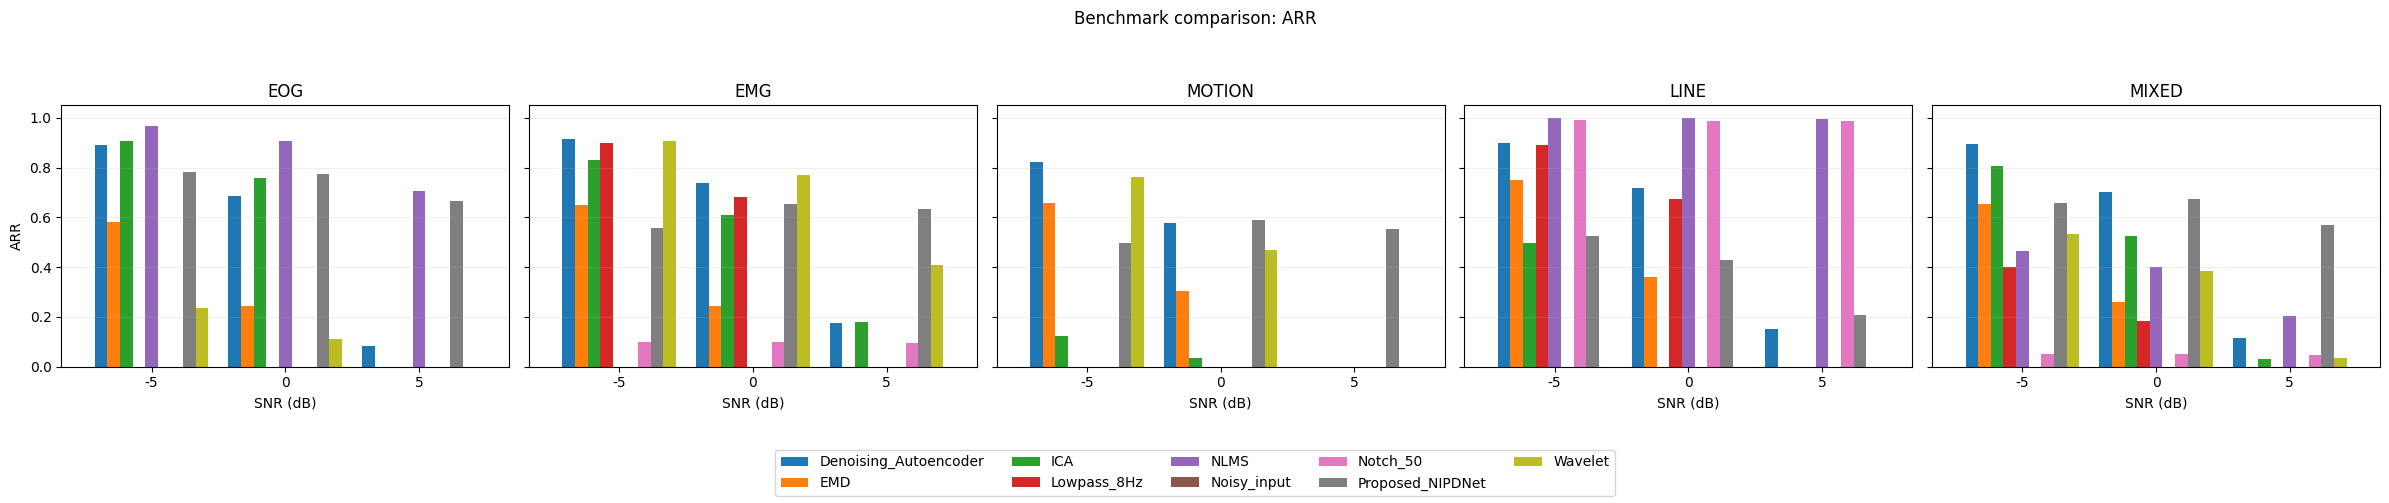

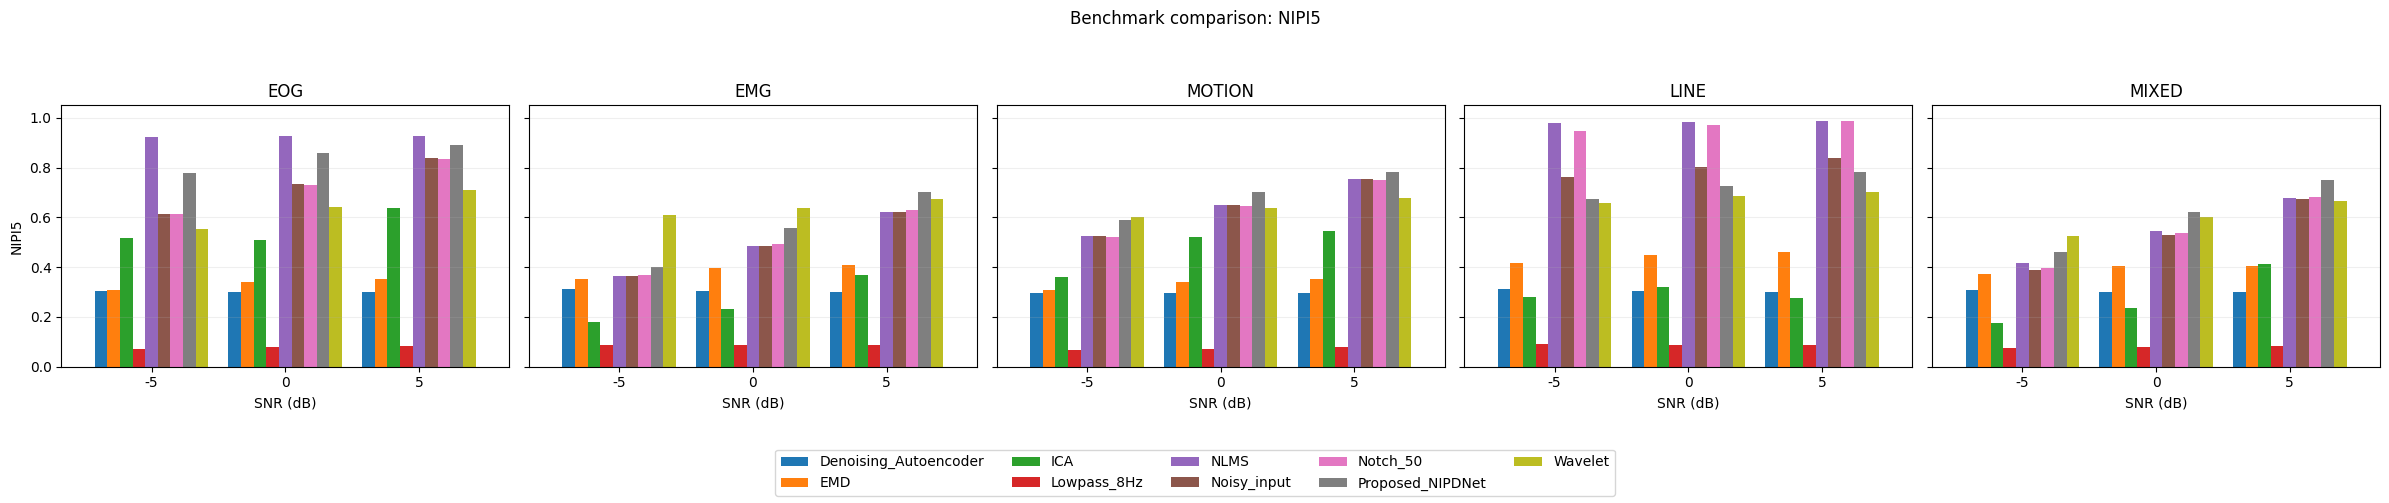

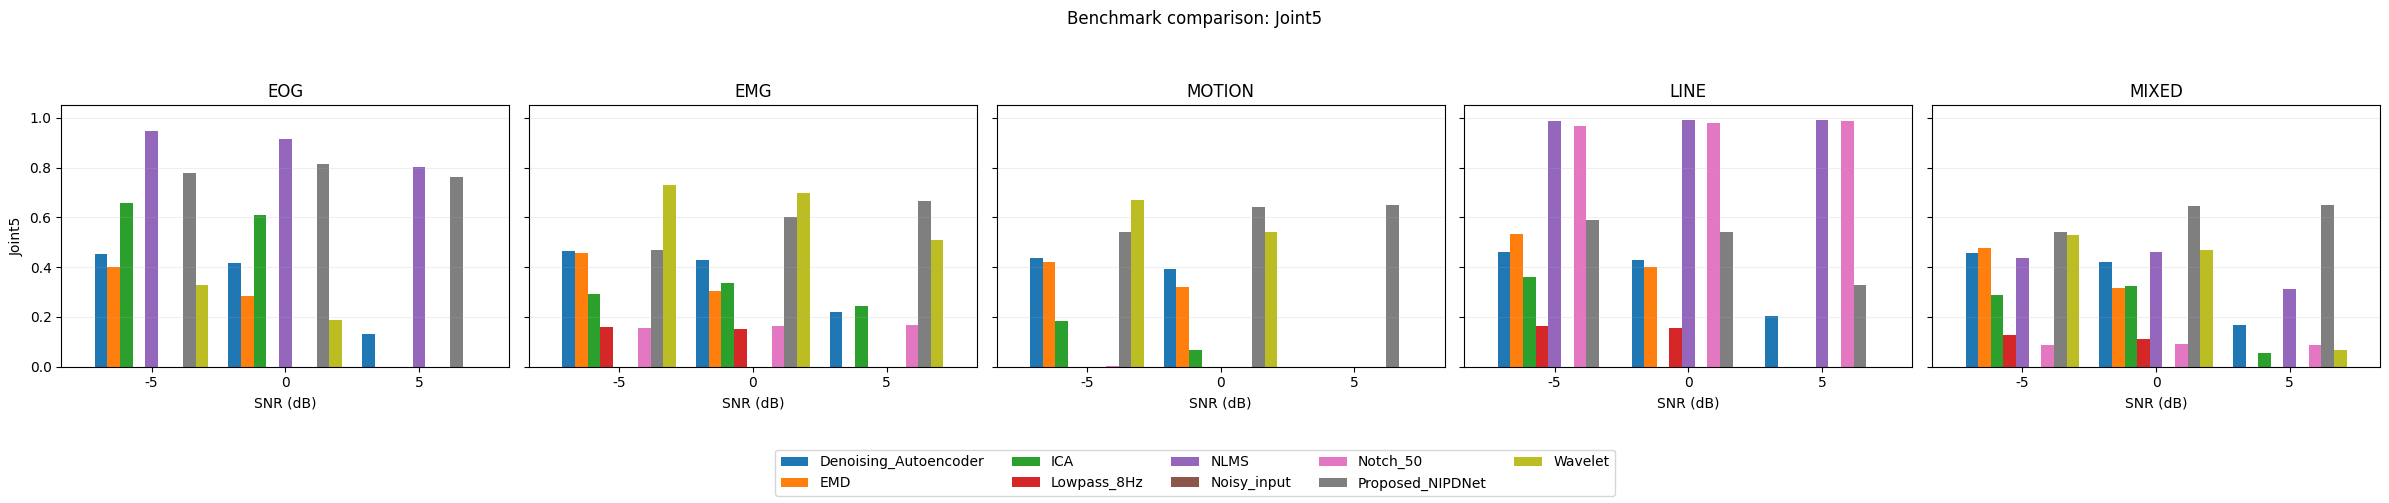

In [94]:
import matplotlib.pyplot as plt

for metric in ['ARR', 'NIPI5', 'Joint5']:

    fig, axes = plt.subplots(
        1, 5, figsize=(24, 5),
        sharey=True
    )

    for ax, kind in zip(
        axes,
        ['eog', 'emg', 'motion', 'line', 'mixed']
    ):

        pivot = df[df['kind'] == kind].pivot(
            index='snr_db',
            columns='method',
            values=metric
        )

        pivot.plot(
            kind='bar',
            ax=ax,
            legend=False,
            width=0.85
        )

        ax.set_title(kind.upper())
        ax.set_xlabel('SNR (dB)')
        ax.set_ylim(0, 1.05)
        ax.tick_params(axis='x', rotation=0)
        ax.grid(axis='y', alpha=0.2)

    axes[0].set_ylabel(metric)

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc='lower center',
        ncol=5
    )

    fig.suptitle(f'Benchmark comparison: {metric}')
    plt.tight_layout(rect=[0, 0.15, 1, 0.93])

    plt.savefig(
        f'outputs/extended_{metric}_comparison.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

In [95]:
from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path

files = [
    Path('outputs/ae_matched.pt'),
    Path('outputs/ae_matched.csv'),
    Path('outputs/best_nipdnet_final.pt'),
    Path('complete_baselines.py'),
    *Path('outputs').glob('extended_*')
]

save_path = '/kaggle/working/step1_results.zip'

with ZipFile(save_path, 'w', ZIP_DEFLATED) as z:
    for f in files:
        if f.is_file():
            z.write(f, arcname=str(f))

print("Saved:", save_path)

Saved: /kaggle/working/step1_results.zip


In [96]:
import os
import shutil
from pathlib import Path

WORK = Path('/kaggle/working/proj')
os.chdir(WORK)

matches = list(
    Path('/kaggle/input').rglob(
        'run_nipi_ablation.py'
    )
)

assert matches, "Upload run_nipi_ablation.py first"

shutil.copy2(
    matches[0],
    WORK / 'run_nipi_ablation.py'
)

print("Ablation script ready")

Ablation script ready


In [97]:
!python -u run_nipi_ablation.py \
    --epochs 80 \
    --seeds 0 \
    --modes A B C

Device: cuda training pool: (1212, 19, 512) test: (148, 19, 512)

A_Rec_aux seed=0 train=1030 val=182
  epoch 01 L1=5.124 ARR=0.065 NIPI5=0.471 Joint5=0.114 *
  epoch 02 L1=5.017 ARR=0.126 NIPI5=0.462 Joint5=0.198 *
  epoch 03 L1=4.539 ARR=0.179 NIPI5=0.455 Joint5=0.256 *
  epoch 04 L1=4.429 ARR=0.212 NIPI5=0.462 Joint5=0.291 *
  epoch 05 L1=4.668 ARR=0.241 NIPI5=0.458 Joint5=0.316 *
  epoch 06 L1=4.485 ARR=0.263 NIPI5=0.449 Joint5=0.332 *
  epoch 07 L1=4.832 ARR=0.266 NIPI5=0.453 Joint5=0.335 *
  epoch 08 L1=4.013 ARR=0.309 NIPI5=0.462 Joint5=0.370 *
  epoch 09 L1=4.377 ARR=0.342 NIPI5=0.448 Joint5=0.388 *
  epoch 10 L1=4.042 ARR=0.358 NIPI5=0.463 Joint5=0.404 *
  epoch 11 L1=4.146 ARR=0.394 NIPI5=0.457 Joint5=0.423 *
  epoch 12 L1=4.223 ARR=0.392 NIPI5=0.461 Joint5=0.423 *
  epoch 13 L1=3.734 ARR=0.400 NIPI5=0.460 Joint5=0.428 *
  epoch 14 L1=4.268 ARR=0.428 NIPI5=0.463 Joint5=0.444 *
  epoch 15 L1=3.625 ARR=0.448 NIPI5=0.459 Joint5=0.453 *
  epoch 16 L1=3.576 ARR=0.479 NIPI5=0.475 J

In [98]:
import pandas as pd

abl = pd.read_csv(
    'outputs/ablation/ablation_full.csv'
)

print("Total results:", len(abl))

assert len(abl) == 45

metrics = [
    'ARR',
    'RMSE',
    'CC',
    'SNR_gain_dB',
    'NIPI5',
    'Joint5'
]

summary = (
    abl.groupby('method')[metrics]
       .mean()
       .sort_values('Joint5', ascending=False)
)

display(summary.round(4))

Total results: 45


,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
method,,,,,,
B_Fixed_NIPI,0.6120,11.6453,0.8243,4.3468,0.6863,0.6344
C_Adaptive_NIPI,0.5948,11.8674,0.8242,4.0645,0.6837,0.6256
A_Rec_aux,0.5245,12.6876,0.7975,3.5621,0.6615,0.5593


In [99]:
headline = abl[
    (abl['kind'] == 'mixed') &
    (abl['snr_db'] == 0)
]

display(
    headline[
        ['method'] + metrics
    ].round(4)
)

,method,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
39,A_Rec_aux,0.6366,10.3043,0.8484,4.3966,0.5806,0.6073
40,B_Fixed_NIPI,0.6869,9.5646,0.8678,5.0437,0.6356,0.6603
41,C_Adaptive_NIPI,0.6567,10.0163,0.8626,4.6428,0.6310,0.6436


In [100]:
components = [
    'spectral',
    'phase',
    'connect',
    'geometry',
    'entropy',
    'NIPI5'
]

display(
    headline.set_index('method')[components]
            .round(4)
)

,spectral,phase,connect,geometry,entropy,NIPI5
method,,,,,,
A_Rec_aux,0.6856,0.9140,0.8154,0.2486,0.5195,0.5806
B_Fixed_NIPI,0.7453,0.9223,0.8348,0.3076,0.5876,0.6356
C_Adaptive_NIPI,0.7436,0.9248,0.8364,0.2952,0.5891,0.6310


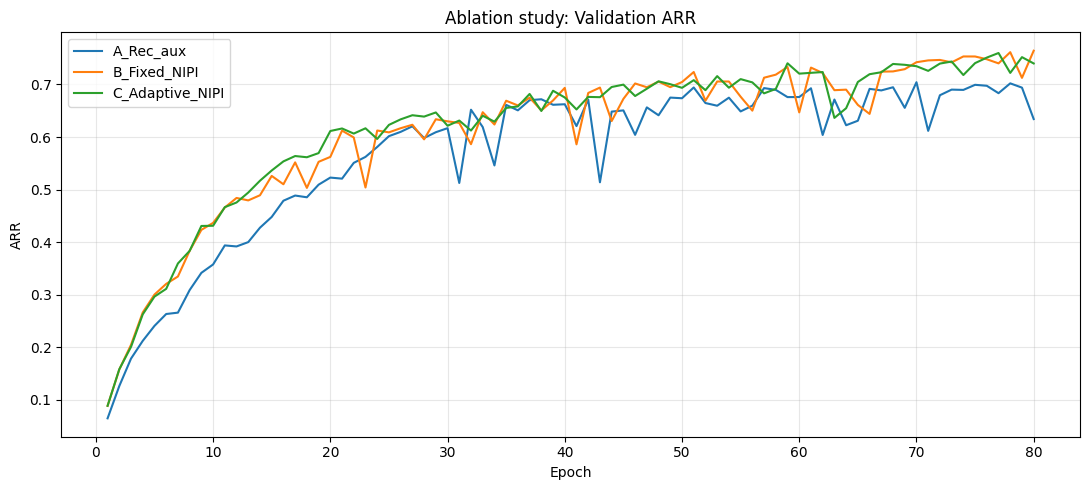

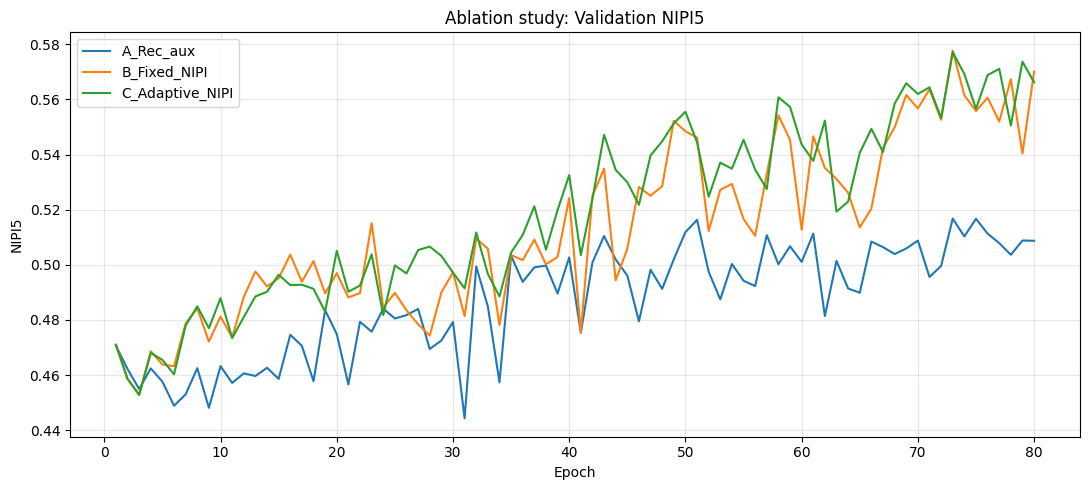

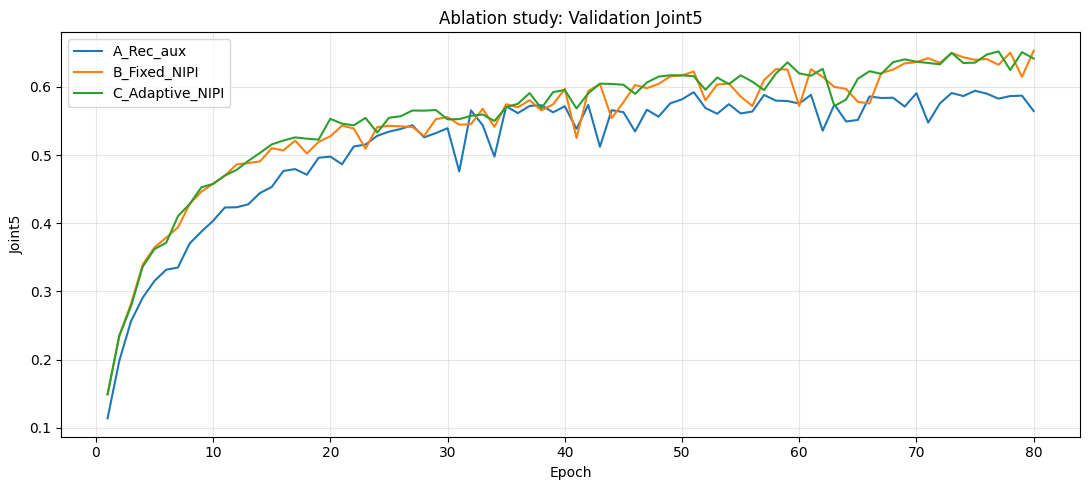

In [101]:
import matplotlib.pyplot as plt

models = [
    'A_Rec_aux',
    'B_Fixed_NIPI',
    'C_Adaptive_NIPI'
]

for metric in ['ARR', 'NIPI5', 'Joint5']:

    plt.figure(figsize=(11, 5))

    for model in models:

        history = pd.read_csv(
            f'outputs/ablation/seed_0/'
            f'{model}/history.csv'
        )

        plt.plot(
            history['epoch'],
            history[metric],
            label=model
        )

    plt.xlabel('Epoch')
    plt.ylabel(metric)
    plt.title(f'Ablation study: Validation {metric}')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f'outputs/ablation/validation_{metric}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

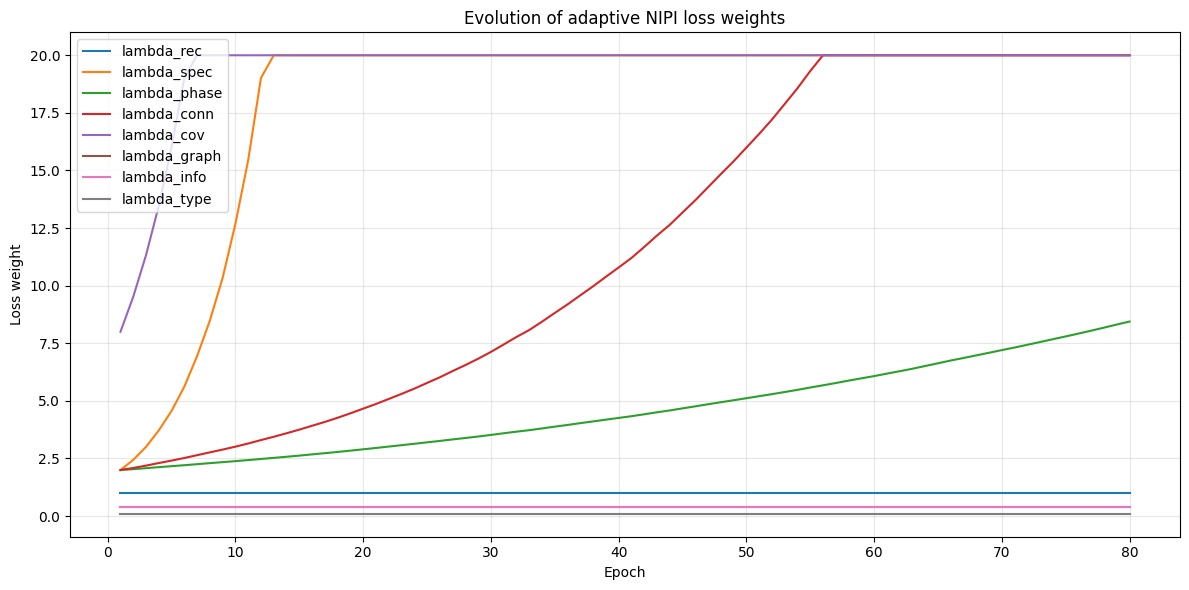

,lambda_rec,lambda_spec,lambda_phase,lambda_conn,lambda_cov,lambda_graph,lambda_info,lambda_type
75,1.0,20.0,7.921003,20.0,20.0,0.4,0.4,0.1
76,1.0,20.0,8.048516,20.0,20.0,0.4,0.4,0.1
77,1.0,20.0,8.178781,20.0,20.0,0.4,0.4,0.1
78,1.0,20.0,8.313950,20.0,20.0,0.4,0.4,0.1
79,1.0,20.0,8.443129,20.0,20.0,0.4,0.4,0.1


In [102]:
history = pd.read_csv(
    'outputs/ablation/seed_0/'
    'C_Adaptive_NIPI/history.csv'
)

weights = [
    'lambda_rec',
    'lambda_spec',
    'lambda_phase',
    'lambda_conn',
    'lambda_cov',
    'lambda_graph',
    'lambda_info',
    'lambda_type'
]

plt.figure(figsize=(12, 6))

for w in weights:

    plt.plot(
        history['epoch'],
        history[w],
        label=w
    )

plt.xlabel('Epoch')
plt.ylabel('Loss weight')
plt.title('Evolution of adaptive NIPI loss weights')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'outputs/ablation/adaptive_weights.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

display(history[weights].tail())

In [103]:
from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path

save_path = '/kaggle/working/step2_ablation.zip'

with ZipFile(save_path, 'w', ZIP_DEFLATED) as z:

    for f in Path('outputs/ablation').rglob('*'):

        if f.is_file():
            z.write(f, arcname=str(f))

    z.write(
        'run_nipi_ablation.py',
        arcname='run_nipi_ablation.py'
    )

print("Saved:", save_path)

Saved: /kaggle/working/step2_ablation.zip


In [104]:
import os
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from eegnipi.model import NIPDNet
from run_nipi_ablation import predict
from physio_validation import bandpow, chs, get_methods

os.chdir('/kaggle/working/proj')

device = 'cuda' if torch.cuda.is_available() else 'cpu'

checkpoints = {
    'Original_NIPDNet':
        'outputs/best_nipdnet_final.pt',

    'A_Rec_aux':
        'outputs/ablation/seed_0/A_Rec_aux/best.pt',

    'B_Fixed_NIPI':
        'outputs/ablation/seed_0/B_Fixed_NIPI/best.pt',

    'C_Adaptive_NIPI':
        'outputs/ablation/seed_0/C_Adaptive_NIPI/best.pt'
}

nets = {}

for name, path in checkpoints.items():

    assert Path(path).exists(), f'Missing: {path}'

    net = NIPDNet().to(device)

    net.load_state_dict(
        torch.load(
            path,
            map_location=device,
            weights_only=True
        )
    )

    net.eval()
    nets[name] = net

    print(name, ': loaded successfully')

Original_NIPDNet : loaded successfully
A_Rec_aux : loaded successfully
B_Fixed_NIPI : loaded successfully
C_Adaptive_NIPI : loaded successfully


In [105]:
d = np.load('data/eoec_all.npz')

X = d['X'].astype(np.float32)

fr = chs(['Fp1', 'Fp2'])
oc = chs(['O1', 'O2'])
ctr = chs(['C3', 'Cz', 'C4'])
tmp = chs(['T3', 'T4', 'F7', 'F8'])

slow = bandpow(X, 1, 4)

fo = (
    slow[:, fr].mean(1) /
    np.maximum(slow[:, oc].mean(1), 1e-12)
)

mask = fo >= np.quantile(fo, 0.9)

Xb = X[mask]

print("All epochs:", X.shape)
print("Blink-dominant epochs:", Xb.shape)

print(
    "Median frontal peak-to-peak (uV):",
    np.median(np.ptp(Xb[:, fr], axis=-1))
)

print(
    "Median frontal/occipital slow-power ratio:",
    np.median(fo[mask])
)

All epochs: (2070, 19, 512)
Blink-dominant epochs: (207, 19, 512)
Median frontal peak-to-peak (uV): 903.5343
Median frontal/occipital slow-power ratio: 44.947826


In [106]:
methods = get_methods(None)

for name, net in nets.items():

    methods[name] = lambda x, net=net: predict(
        net, x, device
    )

rows = []
blink_outputs = {}

def power_ratio(Y, X, channels, lo, hi):

    before = bandpow(X, lo, hi)[:, channels].mean(1)
    after = bandpow(Y, lo, hi)[:, channels].mean(1)

    return float(
        np.median(after / np.maximum(before, 1e-12))
    )

for name, fn in methods.items():

    Y = fn(Xb)

    blink_outputs[name] = Y

    rows.append({
        'method': name,

        'frontal_slow_ratio':
            power_ratio(Y, Xb, fr, 1, 4),

        'occipital_alpha_ratio':
            power_ratio(Y, Xb, oc, 8, 13),

        'central_mu_ratio':
            power_ratio(Y, Xb, ctr, 8, 13),

        'temporal_hf_ratio':
            power_ratio(Y, Xb, tmp, 30, 45),

        'relative_signal_change':
            np.linalg.norm(Y-Xb) /
            np.linalg.norm(Xb)
    })

blink_df = pd.DataFrame(rows)

display(
    blink_df.sort_values(
        'frontal_slow_ratio'
    ).round(4)
)

blink_df.to_csv(
    'outputs/ablation/blink_comparison.csv',
    index=False
)

,method,frontal_slow_ratio,occipital_alpha_ratio,central_mu_ratio,temporal_hf_ratio,relative_signal_change
1,ICA,0.0040,0.9667,0.7218,0.1975,0.9401
2,Wavelet,0.0909,0.8615,0.9239,0.9505,0.7456
4,A_Rec_aux,0.9439,0.9995,1.0021,0.9147,0.1124
5,B_Fixed_NIPI,0.9532,0.9976,1.0067,0.8063,0.1365
6,C_Adaptive_NIPI,0.9871,1.0028,1.0057,0.8450,0.1143
3,Original_NIPDNet,0.9986,0.9974,1.0009,0.8932,0.0708
0,Raw,1.0000,1.0000,1.0000,1.0000,0.0000


In [107]:
import eegnipi.artifacts as AM

AM.MIXED = ['eog', 'emg']

with np.load('data/train_mix.npz') as data:
    Xtrain = data['X'].astype(np.float32)
    ytrain = data['y']
    fs = int(data['fs'])

split = int(0.85 * len(Xtrain))

Xval = Xtrain[split:]
yval = ytrain[split:]

def epoch_rms(x):
    return np.sqrt(
        np.mean(x**2, axis=(1, 2))
    )

# Strongest EOG SNR encountered during
# the existing training protocol
Xval_noisy, _, _ = AM.contaminate(
    Xval,
    'eog',
    -5,
    fs,
    seed=123
)

RMS_TARGET = float(
    np.quantile(epoch_rms(Xval_noisy), 0.95)
)

assert RMS_TARGET > 0

print("Validation RMS target:", RMS_TARGET)

print(
    "Median blink epoch RMS:",
    np.median(epoch_rms(Xb))
)

def predict_normalized(net, x):

    scale = np.maximum(
        epoch_rms(x) / RMS_TARGET,
        1.0
    ).astype(np.float32)

    scale = scale[:, None, None]

    normalized = x / scale

    denoised = predict(
        net, normalized, device
    )

    return denoised * scale

Validation RMS target: 34.74161148071289
Median blink epoch RMS: 55.65877


In [108]:
Y_normalized = predict_normalized(
    nets['B_Fixed_NIPI'],
    Xb
)

new_row = pd.DataFrame([{
    'method': 'B_Amplitude_Normalized',

    'frontal_slow_ratio':
        power_ratio(Y_normalized, Xb, fr, 1, 4),

    'occipital_alpha_ratio':
        power_ratio(Y_normalized, Xb, oc, 8, 13),

    'central_mu_ratio':
        power_ratio(Y_normalized, Xb, ctr, 8, 13),

    'temporal_hf_ratio':
        power_ratio(Y_normalized, Xb, tmp, 30, 45),

    'relative_signal_change':
        np.linalg.norm(Y_normalized-Xb) /
        np.linalg.norm(Xb)
}])

blink_df = pd.concat(
    [
        blink_df[
            blink_df['method'] !=
            'B_Amplitude_Normalized'
        ],
        new_row
    ],
    ignore_index=True
)

blink_outputs['B_Amplitude_Normalized'] = Y_normalized

display(
    blink_df.sort_values(
        'frontal_slow_ratio'
    ).round(4)
)

blink_df.to_csv(
    'outputs/ablation/blink_comparison.csv',
    index=False
)

,method,frontal_slow_ratio,occipital_alpha_ratio,central_mu_ratio,temporal_hf_ratio,relative_signal_change
1,ICA,0.0040,0.9667,0.7218,0.1975,0.9401
2,Wavelet,0.0909,0.8615,0.9239,0.9505,0.7456
7,B_Amplitude_Normalized,0.9438,0.9982,1.0141,0.7745,0.2652
4,A_Rec_aux,0.9439,0.9995,1.0021,0.9147,0.1124
5,B_Fixed_NIPI,0.9532,0.9976,1.0067,0.8063,0.1365
6,C_Adaptive_NIPI,0.9871,1.0028,1.0057,0.8450,0.1143
3,Original_NIPDNet,0.9986,0.9974,1.0009,0.8932,0.0708
0,Raw,1.0000,1.0000,1.0000,1.0000,0.0000


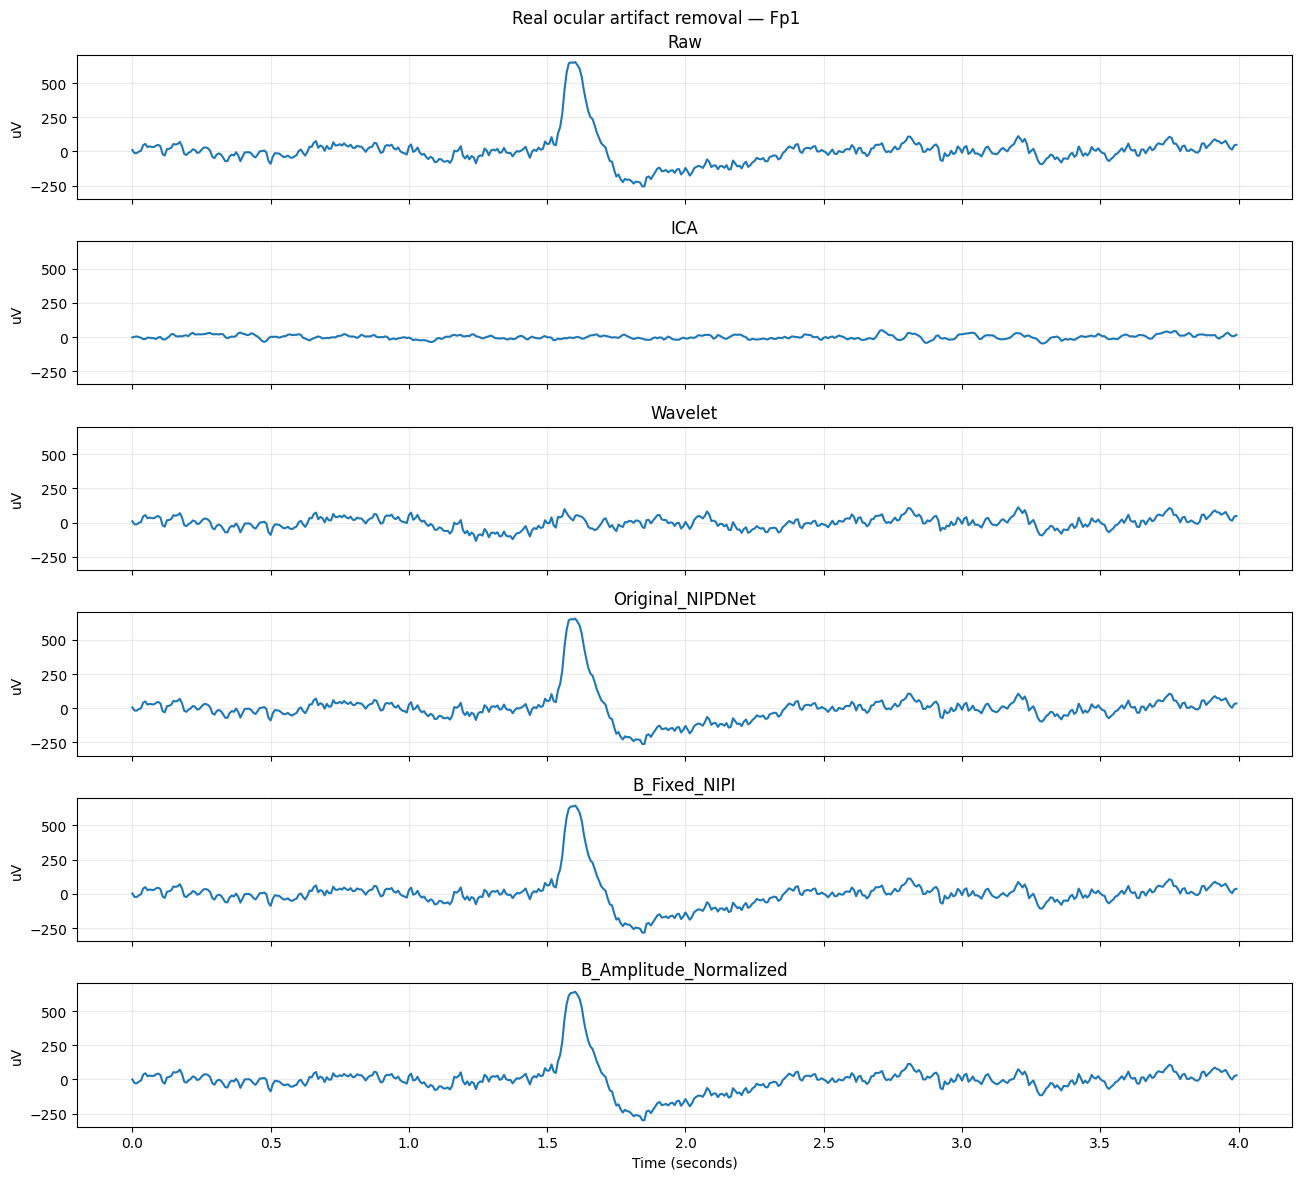

In [109]:
import matplotlib.pyplot as plt

# Select a representative high-amplitude epoch
amplitudes = np.ptp(
    Xb[:, fr],
    axis=-1
).mean(1)

idx = np.argsort(amplitudes)[len(Xb)//2]

ch = fr[0]
t = np.arange(Xb.shape[-1]) / fs

names = [
    'Raw',
    'ICA',
    'Wavelet',
    'Original_NIPDNet',
    'B_Fixed_NIPI',
    'B_Amplitude_Normalized'
]

fig, axes = plt.subplots(
    len(names), 1,
    figsize=(13, 12),
    sharex=True,
    sharey=True
)

for ax, name in zip(axes, names):

    ax.plot(
        t,
        blink_outputs[name][idx, ch]
    )

    ax.set_title(name)
    ax.set_ylabel('uV')
    ax.grid(alpha=0.25)

axes[-1].set_xlabel('Time (seconds)')

fig.suptitle(
    'Real ocular artifact removal — Fp1'
)

plt.tight_layout()

plt.savefig(
    'outputs/ablation/real_blink_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [110]:
from eegnipi.nipi import (
    nipi,
    artifact_suppression,
    joint_score
)

PARTS = [
    'spectral',
    'phase',
    'connect',
    'geometry',
    'entropy'
]

stress_rows = []

for snr in [-5, -10, -15, -20]:

    noisy, _, _ = AM.contaminate(
        Xval,
        'eog',
        snr,
        fs,
        seed=456
    )

    candidates = {
        'B_Fixed_NIPI':
            predict(
                nets['B_Fixed_NIPI'],
                noisy,
                device
            ),

        'B_Amplitude_Normalized':
            predict_normalized(
                nets['B_Fixed_NIPI'],
                noisy
            )
    }

    for name, Y in candidates.items():

        m = artifact_suppression(
            Xval, noisy, Y
        )

        n = nipi(
            Xval, Y, yval, fs,
            parts=PARTS
        )

        stress_rows.append({
            'method': name,
            'snr_db': snr,
            **m,
            'NIPI5': n['NIPI'],
            'Joint5': joint_score(
                m['ARR'], n['NIPI']
            )
        })

stress_df = pd.DataFrame(stress_rows)

display(stress_df.round(4))

stress_df.to_csv(
    'outputs/ablation/eog_stress_test.csv',
    index=False
)

,method,snr_db,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
0,B_Fixed_NIPI,-5,0.9099,6.5491,0.8833,10.4515,0.8035,0.8534
1,B_Amplitude_Normalized,-5,0.9144,6.3817,0.8847,10.6765,0.8046,0.8560
2,B_Fixed_NIPI,-10,0.7190,20.5655,0.5387,5.5124,0.6616,0.6891
3,B_Amplitude_Normalized,-10,0.8434,15.3539,0.5942,8.0508,0.6989,0.7644
4,B_Fixed_NIPI,-15,0.4736,50.0522,0.2465,2.7867,0.4588,0.4661
5,B_Amplitude_Normalized,-15,0.8263,28.7513,0.3458,7.6020,0.5615,0.6687
6,B_Fixed_NIPI,-20,0.2881,103.5088,0.1105,1.4756,0.3082,0.2978
7,B_Amplitude_Normalized,-20,0.8222,51.7351,0.1870,7.4995,0.4280,0.5630


In [111]:
import os
import shutil
from pathlib import Path

WORK = Path('/kaggle/working/proj')
os.chdir(WORK)

files = list(
    Path('/kaggle/input').rglob(
        'realistic_eog_finetune.py'
    )
)

assert files, "Upload the new script first"

shutil.copy2(
    files[0],
    WORK / 'realistic_eog_finetune.py'
)

print("Realistic EOG script ready")

Realistic EOG script ready


In [112]:
required = [
    'realistic_eog_finetune.py',
    'run_nipi_ablation.py',
    'data_real.py',
    'data/train_mix.npz',
    'data/eoec_clean.npz',
    'data/eoec_all.npz',
    'outputs/ablation/seed_0/B_Fixed_NIPI/best.pt'
]

for f in required:
    print(
        f, ':',
        'OK' if Path(f).exists() else 'MISSING'
    )

assert all(Path(f).exists() for f in required)

realistic_eog_finetune.py : OK
run_nipi_ablation.py : OK
data_real.py : OK
data/train_mix.npz : OK
data/eoec_clean.npz : OK
data/eoec_all.npz : OK
outputs/ablation/seed_0/B_Fixed_NIPI/best.pt : OK


In [113]:
!python -u realistic_eog_finetune.py --epochs 25

Proxy bank: 21 40 (117, 19, 512) subjects 20
Proxy bank: 41 50 (53, 19, 512) subjects 10
epoch 00: old Joint5=0.6399 proxy Joint5=0.1172 clean NIPI5=0.8154 selection=0.4222 *
epoch 01: old Joint5=0.6254 proxy Joint5=0.5314 clean NIPI5=0.7991 selection=0.6005 *
epoch 02: old Joint5=0.5990 proxy Joint5=0.5739 clean NIPI5=0.7974 selection=0.6076 *
epoch 03: old Joint5=0.6054 proxy Joint5=0.5975 clean NIPI5=0.8072 selection=0.6220 *
epoch 04: old Joint5=0.5989 proxy Joint5=0.6077 clean NIPI5=0.8120 selection=0.6242 *
epoch 05: old Joint5=0.6030 proxy Joint5=0.6150 clean NIPI5=0.8226 selection=0.6304 *
epoch 06: old Joint5=0.5899 proxy Joint5=0.6147 clean NIPI5=0.7976 selection=0.6218
epoch 07: old Joint5=0.6067 proxy Joint5=0.6258 clean NIPI5=0.8308 selection=0.6377 *
epoch 08: old Joint5=0.5719 proxy Joint5=0.6264 clean NIPI5=0.8000 selection=0.6192
epoch 09: old Joint5=0.6175 proxy Joint5=0.6319 clean NIPI5=0.8520 selection=0.6474 *
epoch 10: old Joint5=0.6097 proxy Joint5=0.6376 clean N

,epoch,train_loss,old_joint5,proxy_joint5,clean_nipi5,selection,old_mixed_0,old_emg_0,old_motion_0,proxy_eog_-10,proxy_eog_-20
0,0,NaN,0.6399,0.1172,0.8154,0.4222,0.6530,0.6040,0.6626,0.1377,0.0968
1,1,56.5007,0.6254,0.5314,0.7991,0.6005,0.6288,0.5991,0.6484,0.6159,0.4469
2,2,25.9288,0.5990,0.5739,0.7974,0.6076,0.5936,0.5858,0.6177,0.6543,0.4935
3,3,32.3483,0.6054,0.5975,0.8072,0.6220,0.5883,0.5914,0.6365,0.6740,0.5211
4,4,30.8238,0.5989,0.6077,0.8120,0.6242,0.5736,0.5938,0.6293,0.6819,0.5335
5,5,18.4077,0.6030,0.6150,0.8226,0.6304,0.5849,0.5944,0.6296,0.6890,0.5411
6,6,11.8978,0.5899,0.6147,0.7976,0.6218,0.5554,0.5913,0.6230,0.6870,0.5424
7,7,17.0705,0.6067,0.6258,0.8308,0.6377,0.5953,0.5845,0.6402,0.7033,0.5484
8,8,17.8442,0.5719,0.6264,0.8000,0.6192,0.5515,0.5632,0.6008,0.7013,0.5515
9,9,20.6585,0.6175,0.6319,0.8520,0.6474,0.6097,0.5917,0.6512,0.7068,0.5570


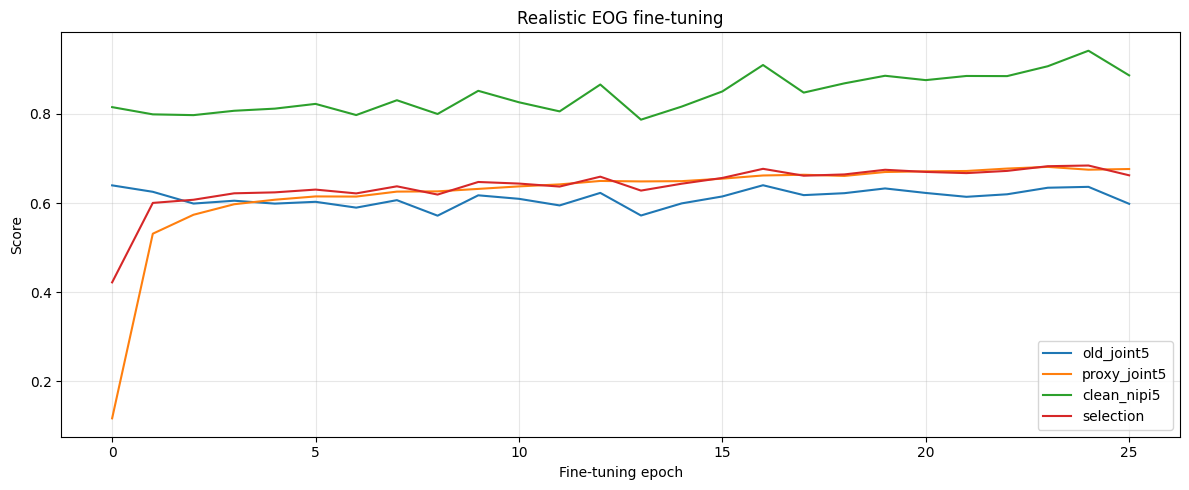

Best checkpoint:
{
  "epoch": 24,
  "objective": 0.6843737331838309
}


In [114]:
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('outputs/realistic_eog')

history = pd.read_csv(ROOT / 'history.csv')

display(history.round(4))

plt.figure(figsize=(12, 5))

for col in [
    'old_joint5',
    'proxy_joint5',
    'clean_nipi5',
    'selection'
]:
    plt.plot(
        history['epoch'],
        history[col],
        label=col
    )

plt.xlabel('Fine-tuning epoch')
plt.ylabel('Score')
plt.title('Realistic EOG fine-tuning')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / 'training_curves.png', dpi=300)
plt.show()

print("Best checkpoint:")
print((ROOT / 'best_epoch.json').read_text())

In [115]:
summary = pd.read_csv(
    ROOT / 'summary.csv',
    index_col=0
)

display(summary.round(4))

,ARR,NIPI5,Joint5,RMSE,CC
method,,,,,
B_Fixed_NIPI,0.6120,0.6863,0.6344,11.6453,0.8243
B_Normalized,0.6230,0.6876,0.6403,11.3546,0.8280
D_Realistic_EOG,0.5799,0.6838,0.6016,11.5902,0.8235


In [116]:
benchmark = pd.read_csv(
    ROOT / 'benchmark.csv'
)

mixed = benchmark[
    (benchmark['kind'] == 'mixed') &
    (benchmark['snr_db'] == 0)
]

display(
    mixed[
        [
            'method',
            'ARR',
            'RMSE',
            'CC',
            'NIPI5',
            'Joint5'
        ]
    ].round(4)
)

,method,ARR,RMSE,CC,NIPI5,Joint5
39,B_Fixed_NIPI,0.6869,9.5646,0.8678,0.6356,0.6603
40,B_Normalized,0.6869,9.5646,0.8678,0.6356,0.6603
41,D_Realistic_EOG,0.6752,9.7425,0.8634,0.6305,0.6521


In [117]:
real = pd.read_csv(
    ROOT / 'real_blink.csv'
)

display(
    real.sort_values(
        'frontal_slow_ratio'
    ).round(4)
)

,method,frontal_slow_ratio,occipital_alpha_ratio,central_mu_ratio,temporal_hf_ratio,relative_signal_change
1,ICA,0.0040,0.9667,0.7218,0.1975,0.9401
2,Wavelet,0.0909,0.8615,0.9239,0.9505,0.7456
5,D_Realistic_EOG,0.6310,0.9925,0.9698,0.8382,0.4640
4,B_Normalized,0.9438,0.9982,1.0141,0.7745,0.2652
3,B_Fixed_NIPI,0.9532,0.9976,1.0067,0.8063,0.1365
0,Raw,1.0000,1.0000,1.0000,1.0000,0.0000


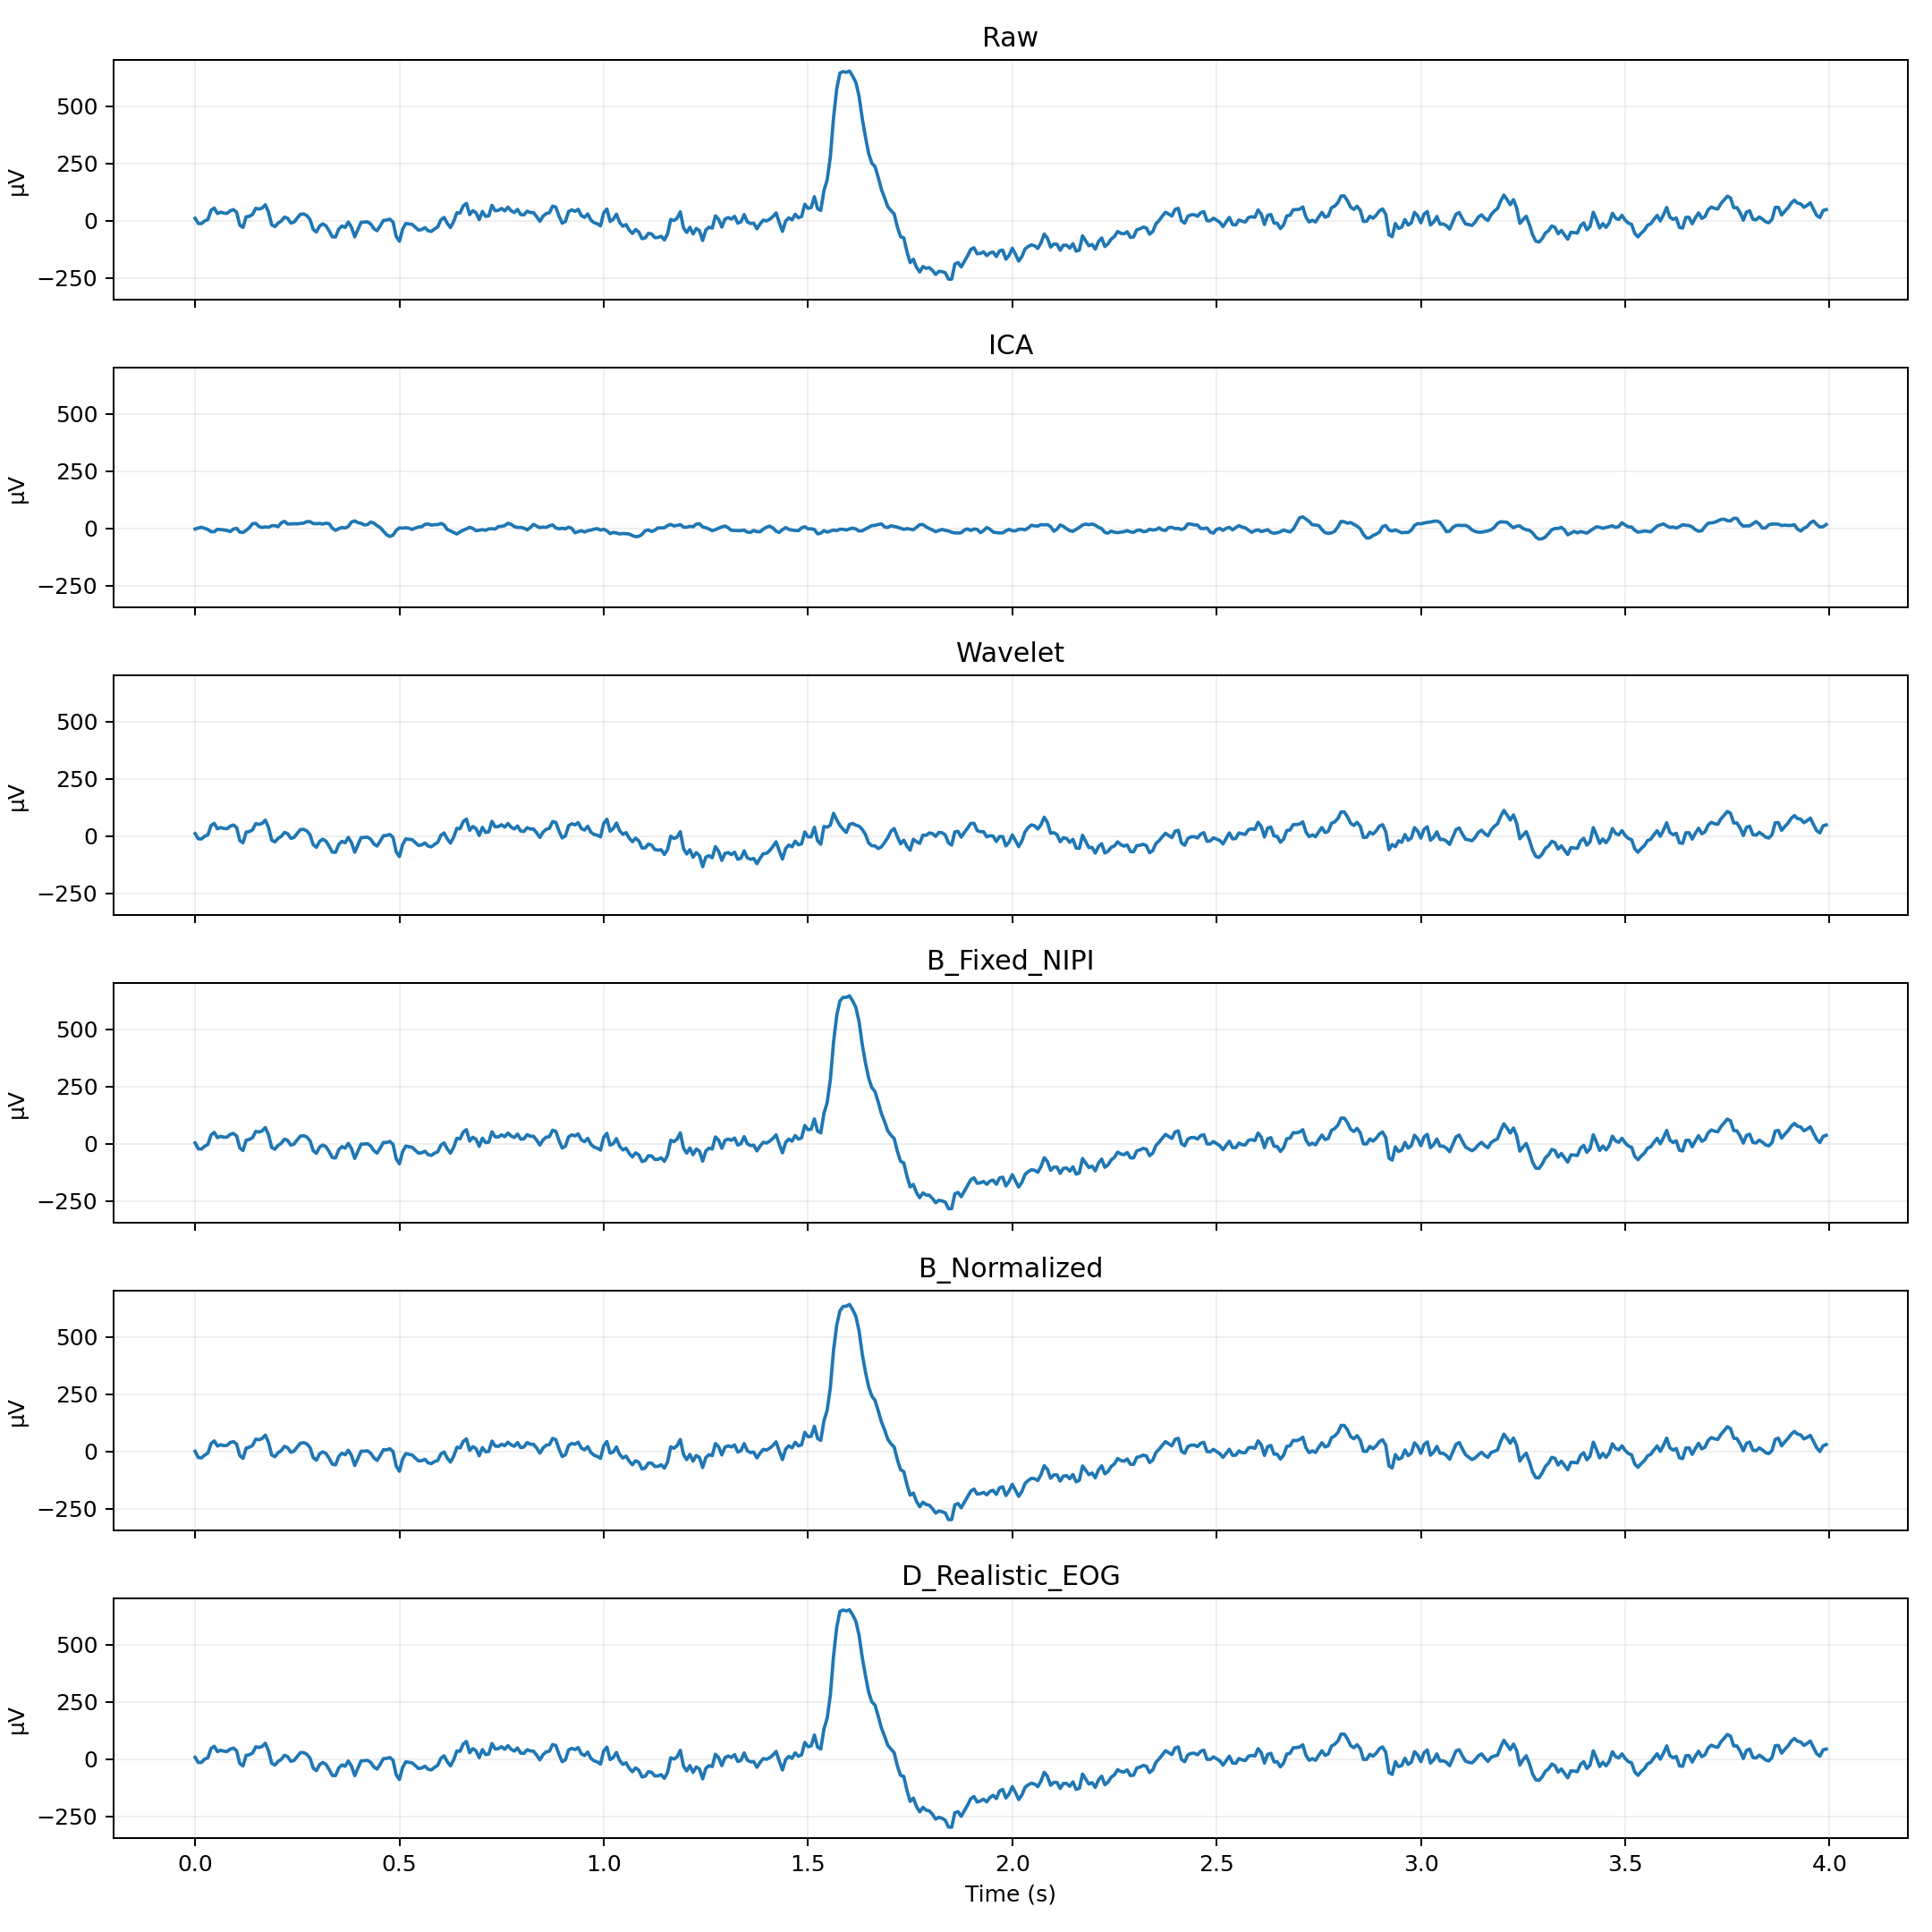

In [118]:
from IPython.display import Image, display

display(
    Image(filename=str(ROOT / 'real_blink.png'))
)

In [119]:
identity = pd.read_csv(
    ROOT / 'clean_identity.csv'
)

display(identity.round(4))

,method,NIPI5,RMSE
0,B_Fixed_NIPI,0.8767,3.5123
1,B_Normalized,0.8767,3.5123
2,D_Realistic_EOG,0.9852,0.5304


In [120]:
from zipfile import ZipFile, ZIP_DEFLATED

save_path = (
    '/kaggle/working/step3_realistic_eog.zip'
)

with ZipFile(save_path, 'w', ZIP_DEFLATED) as z:

    for f in ROOT.rglob('*'):
        if f.is_file():
            z.write(f, arcname=str(f))

    z.write(
        'realistic_eog_finetune.py',
        arcname='realistic_eog_finetune.py'
    )

print("Saved:", save_path)

Saved: /kaggle/working/step3_realistic_eog.zip


In [121]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

from eegnipi.model import NIPDNet
from eegnipi.nipi import (
    nipi,
    _features,
    artifact_suppression,
    joint_score
)

from eegnipi import baselines as BL
import eegnipi.artifacts as AM

from run_nipi_ablation import predict
from realistic_eog_finetune import norm_predict
from complete_baselines import EEGAutoencoder

os.chdir('/kaggle/working/proj')

ROOT = Path('outputs/task_validation')
ROOT.mkdir(parents=True, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

AM.MIXED = ['eog', 'emg']

FS = 128

PARTS = [
    'spectral',
    'phase',
    'connect',
    'geometry',
    'entropy'
]

config = json.loads(
    Path(
        'outputs/realistic_eog/config.json'
    ).read_text()
)

RMS_TARGET = float(config['target'])

paths = {
    'Original_NIPDNet':
        'outputs/best_nipdnet_final.pt',

    'B_Fixed_NIPI':
        'outputs/ablation/seed_0/B_Fixed_NIPI/best.pt',

    'D_Realistic_EOG':
        'outputs/realistic_eog/best_realistic_eog.pt'
}

nets = {}

for name, path in paths.items():

    net = NIPDNet().to(device)

    net.load_state_dict(
        torch.load(
            path,
            map_location=device,
            weights_only=True
        )
    )

    net.eval()
    nets[name] = net

    print(name, ': loaded')

ae = EEGAutoencoder().to(device)

ae.load_state_dict(
    torch.load(
        'outputs/ae_matched.pt',
        map_location=device,
        weights_only=True
    )
)

ae.eval()

print('Autoencoder loaded')
print('RMS target:', RMS_TARGET)

Original_NIPDNet : loaded
B_Fixed_NIPI : loaded
D_Realistic_EOG : loaded
Autoencoder loaded
RMS target: 34.74161148071289


In [122]:
def predict_ae(x):

    outputs = []

    with torch.no_grad():

        for i in range(0, len(x), 64):

            batch = torch.as_tensor(
                x[i:i+64],
                dtype=torch.float32,
                device=device
            )

            outputs.append(
                ae(batch).cpu().numpy()
            )

    return np.concatenate(outputs)


def subject_ica(x, groups):

    out = np.empty_like(x)

    for subject in np.unique(groups):

        mask = groups == subject

        out[mask] = BL.ica(
            x[mask],
            None,
            FS
        )

    return out


methods = {
    'Raw':
        lambda x, g: x.copy(),

    'ICA':
        lambda x, g: subject_ica(x, g),

    'Wavelet':
        lambda x, g: BL.wavelet(x, None, FS),

    'Lowpass_8Hz':
        lambda x, g: BL.lowpass8(x, None, FS),

    'Autoencoder':
        lambda x, g: predict_ae(x),

    'Original_NIPDNet':
        lambda x, g: predict(
            nets['Original_NIPDNet'], x, device
        ),

    'B_Fixed_NIPI':
        lambda x, g: predict(
            nets['B_Fixed_NIPI'], x, device
        ),

    'B_Normalized':
        lambda x, g: norm_predict(
            nets['B_Fixed_NIPI'],
            x, device, RMS_TARGET
        ),

    'D_Realistic_EOG':
        lambda x, g: norm_predict(
            nets['D_Realistic_EOG'],
            x, device, RMS_TARGET
        )
}

print('Available methods:', list(methods))

Available methods: ['Raw', 'ICA', 'Wavelet', 'Lowpass_8Hz', 'Autoencoder', 'Original_NIPDNet', 'B_Fixed_NIPI', 'B_Normalized', 'D_Realistic_EOG']


In [123]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import balanced_accuracy_score


def mi_features(X):

    # Cue occurs at t = 1 second.
    post_cue = X[:, :, FS:]

    return _features(post_cue, FS)


def make_folds(y, subjects):

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    folds = list(
        cv.split(
            np.zeros(len(y)),
            y,
            subjects
        )
    )

    for tr, te in folds:

        assert not (
            set(subjects[tr]) &
            set(subjects[te])
        )

        assert len(np.unique(y[tr])) == 2

    return folds


def classify(Ftrain, Ftest, y, folds):

    predictions = np.empty_like(y)

    for tr, te in folds:

        clf = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=0.1,
                max_iter=2000,
                class_weight='balanced'
            )
        )

        clf.fit(Ftrain[tr], y[tr])

        predictions[te] = clf.predict(
            Ftest[te]
        )

    return {
        'accuracy': accuracy_score(
            y, predictions
        ),

        'balanced_accuracy':
            balanced_accuracy_score(
                y, predictions
            )
    }

In [124]:
with np.load('data/mi_clean.npz') as d:

    X = d['X'].astype(np.float32)
    y = d['y']
    subjects = d['subj']

print('MI reference data:', X.shape)
print('Classes:', np.bincount(y))
print('Subjects:', len(np.unique(subjects)))

folds = make_folds(y, subjects)

Fclean = mi_features(X)

clean_result = classify(
    Fclean, Fclean, y, folds
)

print('Reference decoding:', clean_result)

pd.DataFrame([clean_result]).to_csv(
    ROOT / 'mi_reference_accuracy.csv',
    index=False
)

conditions = [
    ('eog', 0),
    ('emg', 0),
    ('mixed', -5),
    ('mixed', 0),
    ('mixed', 5)
]

rows = []

for kind, snr in conditions:

    noisy = AM.contaminate(
        X, kind, snr, FS, seed=1
    )[0]

    for name, fn in methods.items():

        Y = fn(noisy, subjects)

        n = nipi(
            X, Y, y, FS,
            parts=PARTS
        )

        a = artifact_suppression(
            X, noisy, Y
        )

        result = classify(
            Fclean,
            mi_features(Y),
            y,
            folds
        )

        rows.append({
            'method': name,
            'kind': kind,
            'snr_db': snr,

            'ARR': a['ARR'],
            'NIPI5': n['NIPI'],

            'Joint5': joint_score(
                a['ARR'], n['NIPI']
            ),

            **{k: n[k] for k in PARTS},

            **result
        })

        print(
            kind, snr, name,
            'NIPI:', round(n['NIPI'], 4),
            'Balanced accuracy:',
            round(result['balanced_accuracy'], 4)
        )

    pd.DataFrame(rows).to_csv(
        ROOT / 'mi_controlled.csv',
        index=False
    )

controlled = pd.DataFrame(rows)

print('Total results:', len(controlled))

MI reference data: (169, 19, 512)
Classes: [80 89]
Subjects: 9
Reference decoding: {'accuracy': 0.4970414201183432, 'balanced_accuracy': np.float64(0.5091994382022472)}
eog 0 Raw NIPI: 0.7307 Balanced accuracy: 0.5397


/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


eog 0 ICA NIPI: 0.5603 Balanced accuracy: 0.5329
eog 0 Wavelet NIPI: 0.6289 Balanced accuracy: 0.5178
eog 0 Lowpass_8Hz NIPI: 0.0744 Balanced accuracy: 0.5
eog 0 Autoencoder NIPI: 0.2921 Balanced accuracy: 0.4883
eog 0 Original_NIPDNet NIPI: 0.8528 Balanced accuracy: 0.506
eog 0 B_Fixed_NIPI NIPI: 0.8495 Balanced accuracy: 0.5179
eog 0 B_Normalized NIPI: 0.8495 Balanced accuracy: 0.5179
eog 0 D_Realistic_EOG NIPI: 0.8208 Balanced accuracy: 0.5479
emg 0 Raw NIPI: 0.4838 Balanced accuracy: 0.5397
emg 0 ICA NIPI: 0.2581 Balanced accuracy: 0.5305
emg 0 Wavelet NIPI: 0.6153 Balanced accuracy: 0.4761
emg 0 Lowpass_8Hz NIPI: 0.0824 Balanced accuracy: 0.5
emg 0 Autoencoder NIPI: 0.2958 Balanced accuracy: 0.4926
emg 0 Original_NIPDNet NIPI: 0.5623 Balanced accuracy: 0.5236
emg 0 B_Fixed_NIPI NIPI: 0.5811 Balanced accuracy: 0.5005
emg 0 B_Normalized NIPI: 0.5811 Balanced accuracy: 0.5005
emg 0 D_Realistic_EOG NIPI: 0.5835 Balanced accuracy: 0.5005
mixed -5 Raw NIPI: 0.3956 Balanced accuracy: 0.5

/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


mixed 5 ICA NIPI: 0.4131 Balanced accuracy: 0.558
mixed 5 Wavelet NIPI: 0.6542 Balanced accuracy: 0.5147
mixed 5 Lowpass_8Hz NIPI: 0.0798 Balanced accuracy: 0.5
mixed 5 Autoencoder NIPI: 0.2915 Balanced accuracy: 0.487
mixed 5 Original_NIPDNet NIPI: 0.7568 Balanced accuracy: 0.5111
mixed 5 B_Fixed_NIPI NIPI: 0.7695 Balanced accuracy: 0.5223
mixed 5 B_Normalized NIPI: 0.7695 Balanced accuracy: 0.5223
mixed 5 D_Realistic_EOG NIPI: 0.7585 Balanced accuracy: 0.5454
Total results: 45


In [125]:
from scipy.stats import spearmanr

controlled = pd.read_csv(
    ROOT / 'mi_controlled.csv'
)

summary = (
    controlled.groupby('method')[
        [
            'ARR',
            'NIPI5',
            'Joint5',
            'accuracy',
            'balanced_accuracy'
        ]
    ]
    .mean()
    .sort_values(
        'balanced_accuracy',
        ascending=False
    )
)

display(summary.round(4))

summary.to_csv(
    ROOT / 'mi_controlled_summary.csv'
)

correlations = []

for metric in PARTS + ['NIPI5', 'ARR', 'Joint5']:

    rho, _ = spearmanr(
        controlled[metric],
        controlled['balanced_accuracy']
    )

    within = []

    for _, group in controlled.groupby(
        ['kind', 'snr_db']
    ):

        r, _ = spearmanr(
            group[metric],
            group['balanced_accuracy']
        )

        within.append(r)

    correlations.append({
        'metric': metric,

        'overall_spearman': rho,

        'mean_within_condition':
            np.nanmean(within)
    })

corr_df = pd.DataFrame(correlations)

display(corr_df.round(4))

corr_df.to_csv(
    ROOT / 'mi_metric_correlations.csv',
    index=False
)

,ARR,NIPI5,Joint5,accuracy,balanced_accuracy
method,,,,,
Raw,0.0000,0.5650,0.0000,0.5491,0.5474
D_Realistic_EOG,0.6764,0.6582,0.6560,0.5325,0.5459
B_Normalized,0.7081,0.6667,0.6798,0.5183,0.5312
B_Fixed_NIPI,0.7038,0.6662,0.6780,0.5160,0.5286
Wavelet,0.3416,0.6041,0.3620,0.5207,0.5247
ICA,0.5302,0.3331,0.3246,0.5018,0.5230
Original_NIPDNet,0.6830,0.6542,0.6608,0.5101,0.5223
Lowpass_8Hz,0.2631,0.0773,0.0766,0.5266,0.5000
Autoencoder,0.6222,0.2947,0.3693,0.5041,0.4886


,metric,overall_spearman,mean_within_condition
0,spectral,0.3876,0.3871
1,phase,0.4570,0.5515
2,connect,0.4255,0.5115
3,geometry,0.1188,0.0940
4,entropy,0.3160,0.3105
5,NIPI5,0.3740,0.3684
6,ARR,-0.1891,-0.2515
7,Joint5,0.0895,0.0832


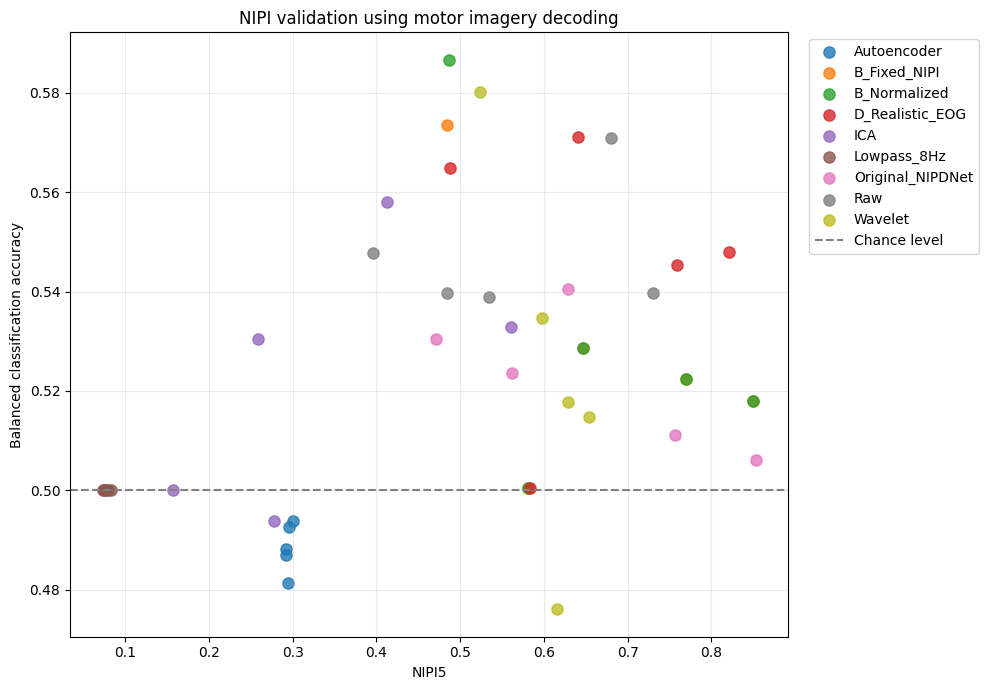

In [126]:
fig, ax = plt.subplots(figsize=(10, 7))

for name, group in controlled.groupby('method'):

    ax.scatter(
        group['NIPI5'],
        group['balanced_accuracy'],
        label=name,
        s=65,
        alpha=0.8
    )

ax.axhline(
    0.5,
    linestyle='--',
    color='gray',
    label='Chance level'
)

ax.set_xlabel('NIPI5')
ax.set_ylabel('Balanced classification accuracy')

ax.set_title(
    'NIPI validation using motor imagery decoding'
)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    ROOT / 'nipi_vs_mi_accuracy.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [127]:
from physio_validation import keep_mask, mi_report

with np.load('data/mi_all.npz') as d:

    Xreal = d['X'].astype(np.float32)
    yreal = d['y']
    greal = d['subj']

clean_mask = keep_mask(Xreal)

folds_real = make_folds(
    yreal, greal
)

print('Total MI epochs:', len(Xreal))

print(
    'Suspected contaminated:',
    (~clean_mask).sum()
)

rows_real = []
real_outputs = {}

for name, fn in methods.items():

    Y = fn(Xreal, greal)

    real_outputs[name] = Y

    F = mi_features(Y)

    result_all = classify(
        F, F, yreal, folds_real
    )

    mask = ~clean_mask

    Fc = F[mask]
    yc = yreal[mask]
    gc = greal[mask]

    folds_contam = make_folds(yc, gc)

    result_contam = classify(
        Fc, Fc, yc, folds_contam
    )

    rows_real.append({
        'method': name,

        'accuracy_all':
            result_all['accuracy'],

        'balanced_accuracy_all':
            result_all['balanced_accuracy'],

        'accuracy_contaminated':
            result_contam['accuracy'],

        'balanced_accuracy_contaminated':
            result_contam['balanced_accuracy']
    })

    print(name, rows_real[-1])

real_df = pd.DataFrame(rows_real)

display(
    real_df.sort_values(
        'balanced_accuracy_contaminated',
        ascending=False
    ).round(4)
)

real_df.to_csv(
    ROOT / 'mi_natural_decoding.csv',
    index=False
)

Total MI epochs: 900
Suspected contaminated: 731
Raw {'method': 'Raw', 'accuracy_all': 0.5266666666666666, 'balanced_accuracy_all': np.float64(0.5262871959501173), 'accuracy_contaminated': 0.5102599179206566, 'balanced_accuracy_contaminated': np.float64(0.5085767790262172)}
ICA {'method': 'ICA', 'accuracy_all': 0.5177777777777778, 'balanced_accuracy_all': np.float64(0.5173231263118904), 'accuracy_contaminated': 0.5088919288645691, 'balanced_accuracy_contaminated': np.float64(0.5089513108614232)}
Wavelet {'method': 'Wavelet', 'accuracy_all': 0.5444444444444444, 'balanced_accuracy_all': np.float64(0.5435238918384986), 'accuracy_contaminated': 0.5143638850889193, 'balanced_accuracy_contaminated': np.float64(0.5142846441947566)}
Lowpass_8Hz {'method': 'Lowpass_8Hz', 'accuracy_all': 0.5188888888888888, 'balanced_accuracy_all': np.float64(0.5187924435115446), 'accuracy_contaminated': 0.5006839945280438, 'balanced_accuracy_contaminated': np.float64(0.5010224719101124)}
Autoencoder {'method': 

,method,accuracy_all,balanced_accuracy_all,accuracy_contaminated,balanced_accuracy_contaminated
6,B_Fixed_NIPI,0.5411,0.5407,0.5157,0.5148
2,Wavelet,0.5444,0.5435,0.5144,0.5143
8,D_Realistic_EOG,0.5411,0.5407,0.5116,0.5103
1,ICA,0.5178,0.5173,0.5089,0.5090
7,B_Normalized,0.5389,0.5385,0.5103,0.5089
0,Raw,0.5267,0.5263,0.5103,0.5086
5,Original_NIPDNet,0.5356,0.5352,0.5089,0.5075
3,Lowpass_8Hz,0.5189,0.5188,0.5007,0.5010
4,Autoencoder,0.5189,0.5191,0.4966,0.4971


In [128]:
cached_methods = {
    name: (
        lambda x, Y=Y: Y
    )
    for name, Y in real_outputs.items()
}

lateralization = mi_report(
    Xreal,
    yreal,
    greal,
    clean_mask,
    cached_methods
)

display(lateralization.round(4))

lateralization.to_csv(
    ROOT / 'mi_lateralization.csv',
    index=False
)

,method,d_all,d_contam,d_clean
0,Raw,-0.2691,-0.2318,-0.4563
1,ICA,-0.1839,-0.1746,-0.2252
2,Wavelet,-0.3106,-0.2596,-0.5559
3,Lowpass_8Hz,-0.1144,-0.0794,-0.2738
4,Autoencoder,0.0393,0.0886,-0.1777
5,Original_NIPDNet,-0.2716,-0.2290,-0.4906
6,B_Fixed_NIPI,-0.2740,-0.2363,-0.4612
7,B_Normalized,-0.2764,-0.2392,-0.4612
8,D_Realistic_EOG,-0.2680,-0.2321,-0.4520


In [129]:
from zipfile import ZipFile, ZIP_DEFLATED

save_path = '/kaggle/working/step4_task_validation.zip'

with ZipFile(save_path, 'w', ZIP_DEFLATED) as z:

    for f in ROOT.rglob('*'):

        if f.is_file():

            z.write(
                f,
                arcname=str(f)
            )

print('Saved:', save_path)

Saved: /kaggle/working/step4_task_validation.zip


In [130]:
import pandas as pd

display(
    pd.read_csv(
        'outputs/task_validation/mi_reference_accuracy.csv'
    )
)

,accuracy,balanced_accuracy
0,0.497041,0.509199


In [131]:
from scipy.stats import spearmanr

df = pd.read_csv(
    'outputs/task_validation/mi_controlled.csv'
)

subsets = {
    'All methods': df,

    'Without low-pass': df[
        df['method'] != 'Lowpass_8Hz'
    ],

    'Without low-pass and duplicate variant': df[
        ~df['method'].isin([
            'Lowpass_8Hz',
            'B_Normalized'
        ])
    ]
}

rows = []

for name, subset in subsets.items():

    rows.append({
        'subset': name,
        'observations': len(subset),

        'NIPI_correlation': spearmanr(
            subset['NIPI5'],
            subset['balanced_accuracy']
        ).statistic,

        'ARR_correlation': spearmanr(
            subset['ARR'],
            subset['balanced_accuracy']
        ).statistic
    })

sensitivity = pd.DataFrame(rows)

display(sensitivity.round(4))

sensitivity.to_csv(
    'outputs/task_validation/mi_correlation_sensitivity.csv',
    index=False
)

,subset,observations,NIPI_correlation,ARR_correlation
0,All methods,45,0.3740,-0.1891
1,Without low-pass,40,0.1777,-0.3195
2,Without low-pass and duplicate variant,35,0.2656,-0.3573


In [132]:
import os
import torch
from pathlib import Path

os.chdir('/kaggle/working/proj')

required = [
    'run_nipi_ablation.py',
    'data/train_mix.npz',
    'data/eoec_clean.npz',
    'outputs/ablation/seed_0/A_Rec_aux/best.pt',
    'outputs/ablation/seed_0/B_Fixed_NIPI/best.pt',
    'outputs/ablation/seed_0/C_Adaptive_NIPI/best.pt',
    'outputs/ablation/seed_0/benchmark.csv'
]

for f in required:
    print(f, ':', 'OK' if Path(f).exists() else 'MISSING')

assert all(Path(f).exists() for f in required)

print('GPU available:', torch.cuda.is_available())

run_nipi_ablation.py : OK
data/train_mix.npz : OK
data/eoec_clean.npz : OK
outputs/ablation/seed_0/A_Rec_aux/best.pt : OK
outputs/ablation/seed_0/B_Fixed_NIPI/best.pt : OK
outputs/ablation/seed_0/C_Adaptive_NIPI/best.pt : OK
outputs/ablation/seed_0/benchmark.csv : OK
GPU available: True


In [133]:
!python -u run_nipi_ablation.py \
    --epochs 80 \
    --seeds 1 \
    --modes A B \
    --out outputs/ablation_repeat/seed_1_run

Device: cuda training pool: (1212, 19, 512) test: (148, 19, 512)

A_Rec_aux seed=1 train=1030 val=182
  epoch 01 L1=5.136 ARR=0.092 NIPI5=0.469 Joint5=0.154 *
  epoch 02 L1=4.889 ARR=0.149 NIPI5=0.464 Joint5=0.225 *
  epoch 03 L1=4.416 ARR=0.188 NIPI5=0.459 Joint5=0.267 *
  epoch 04 L1=4.299 ARR=0.227 NIPI5=0.455 Joint5=0.303 *
  epoch 05 L1=4.257 ARR=0.231 NIPI5=0.465 Joint5=0.309 *
  epoch 06 L1=4.358 ARR=0.205 NIPI5=0.469 Joint5=0.286
  epoch 07 L1=4.261 ARR=0.282 NIPI5=0.454 Joint5=0.348 *
  epoch 08 L1=4.575 ARR=0.317 NIPI5=0.458 Joint5=0.375 *
  epoch 09 L1=4.223 ARR=0.338 NIPI5=0.452 Joint5=0.387 *
  epoch 10 L1=4.126 ARR=0.348 NIPI5=0.449 Joint5=0.392 *
  epoch 11 L1=4.125 ARR=0.357 NIPI5=0.451 Joint5=0.399 *
  epoch 12 L1=4.002 ARR=0.316 NIPI5=0.477 Joint5=0.380
  epoch 13 L1=4.003 ARR=0.391 NIPI5=0.449 Joint5=0.418 *
  epoch 14 L1=3.711 ARR=0.374 NIPI5=0.435 Joint5=0.402
  epoch 15 L1=3.797 ARR=0.395 NIPI5=0.480 Joint5=0.434 *
  epoch 16 L1=3.863 ARR=0.464 NIPI5=0.469 Joint5=

In [134]:
!python -u run_nipi_ablation.py \
    --epochs 80 \
    --seeds 2 \
    --modes A B \
    --out outputs/ablation_repeat/seed_2_run

Device: cuda training pool: (1212, 19, 512) test: (148, 19, 512)

A_Rec_aux seed=2 train=1030 val=182
  epoch 01 L1=5.187 ARR=0.090 NIPI5=0.467 Joint5=0.151 *
  epoch 02 L1=4.891 ARR=0.129 NIPI5=0.467 Joint5=0.202 *
  epoch 03 L1=4.591 ARR=0.163 NIPI5=0.459 Joint5=0.241 *
  epoch 04 L1=4.505 ARR=0.225 NIPI5=0.455 Joint5=0.301 *
  epoch 05 L1=4.169 ARR=0.239 NIPI5=0.458 Joint5=0.314 *
  epoch 06 L1=4.358 ARR=0.240 NIPI5=0.461 Joint5=0.316 *
  epoch 07 L1=4.350 ARR=0.289 NIPI5=0.447 Joint5=0.351 *
  epoch 08 L1=4.375 ARR=0.307 NIPI5=0.443 Joint5=0.363 *
  epoch 09 L1=4.363 ARR=0.326 NIPI5=0.453 Joint5=0.379 *
  epoch 10 L1=4.205 ARR=0.329 NIPI5=0.441 Joint5=0.377
  epoch 11 L1=4.158 ARR=0.317 NIPI5=0.429 Joint5=0.365
  epoch 12 L1=4.045 ARR=0.337 NIPI5=0.433 Joint5=0.379
  epoch 13 L1=3.890 ARR=0.357 NIPI5=0.455 Joint5=0.400 *
  epoch 14 L1=3.850 ARR=0.358 NIPI5=0.447 Joint5=0.398
  epoch 15 L1=3.584 ARR=0.367 NIPI5=0.447 Joint5=0.403 *
  epoch 16 L1=3.797 ARR=0.342 NIPI5=0.434 Joint5=0.

In [135]:
import pandas as pd

files = [
    'outputs/ablation/seed_0/benchmark.csv',

    'outputs/ablation_repeat/'
    'seed_1_run/seed_1/benchmark.csv',

    'outputs/ablation_repeat/'
    'seed_2_run/seed_2/benchmark.csv'
]

ablation = pd.concat(
    [pd.read_csv(f) for f in files],
    ignore_index=True
)

# Keep A and B for the matched multi-seed analysis
ablation = ablation[
    ablation['method'].isin([
        'A_Rec_aux',
        'B_Fixed_NIPI'
    ])
].copy()

assert len(ablation) == 90

assert not ablation.duplicated([
    'seed', 'method', 'kind', 'snr_db'
]).any()

print('Total results:', len(ablation))

display(
    ablation.groupby(
        ['seed', 'method']
    ).size()
)

ablation.to_csv(
    'outputs/ablation_repeat/ablation_multiseed.csv',
    index=False
)

Total results: 90


seed  method      
0     A_Rec_aux       15
      B_Fixed_NIPI    15
1     A_Rec_aux       15
      B_Fixed_NIPI    15
2     A_Rec_aux       15
      B_Fixed_NIPI    15
dtype: int64

In [136]:
metrics = [
    'ARR',
    'RMSE',
    'CC',
    'SNR_gain_dB',
    'NIPI5',
    'Joint5'
]

per_seed = (
    ablation.groupby(
        ['method', 'seed']
    )[metrics].mean()
)

print('Individual seed results:')

display(per_seed.round(4))

summary = per_seed.groupby(
    'method'
).agg(['mean', 'std'])

print('Mean and standard deviation:')

display(summary.round(4))

per_seed.to_csv(
    'outputs/ablation_repeat/per_seed.csv'
)

summary.to_csv(
    'outputs/ablation_repeat/multiseed_summary.csv'
)

Individual seed results:


ARR     RMSE      CC  SNR_gain_dB   NIPI5  Joint5
method       seed                                                      
A_Rec_aux    0     0.5245  12.6876  0.7975       3.5621  0.6615  0.5593
             1     0.4959  13.0906  0.7968       3.3063  0.6738  0.5357
             2     0.4923  13.3276  0.7961       3.2025  0.6723  0.5454
B_Fixed_NIPI 0     0.6120  11.6453  0.8243       4.3468  0.6863  0.6344
             1     0.5732  12.1634  0.8162       3.9255  0.6745  0.6052
             2     0.5640  12.2245  0.8164       3.8957  0.6864  0.5974

Mean and standard deviation:


ARR             RMSE              CC         SNR_gain_dB  \
                mean     std     mean     std    mean     std        mean   
method                                                                      
A_Rec_aux     0.5042  0.0176  13.0353  0.3236  0.7968  0.0007       3.357   
B_Fixed_NIPI  0.5831  0.0255  12.0110  0.3182  0.8190  0.0046       4.056   

                       NIPI5          Joint5          
                 std    mean     std    mean     std  
method                                                
A_Rec_aux     0.1851  0.6692  0.0067  0.5468  0.0119  
B_Fixed_NIPI  0.2523  0.6824  0.0068  0.6123  0.0195

In [137]:
paired = (
    per_seed.xs(
        'B_Fixed_NIPI',
        level='method'
    )
    -
    per_seed.xs(
        'A_Rec_aux',
        level='method'
    )
)

print('Model B minus Model A:')

display(paired.round(4))

print('Mean improvement:')

display(paired.mean().round(4))

print('Seeds with improved NIPI5:',
      (paired['NIPI5'] > 0).sum(), '/ 3')

print('Seeds with improved Joint5:',
      (paired['Joint5'] > 0).sum(), '/ 3')

paired.to_csv(
    'outputs/ablation_repeat/paired_improvement.csv'
)

Model B minus Model A:


,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
seed,,,,,,
0,0.0876,-1.0423,0.0267,0.7847,0.0249,0.0750
1,0.0774,-0.9272,0.0194,0.6192,0.0007,0.0695
2,0.0717,-1.1031,0.0203,0.6931,0.0141,0.0520


Mean improvement:


ARR            0.0789
RMSE          -1.0242
CC             0.0221
SNR_gain_dB    0.6990
NIPI5          0.0132
Joint5         0.0655
dtype: float64

Seeds with improved NIPI5: 3 / 3
Seeds with improved Joint5: 3 / 3


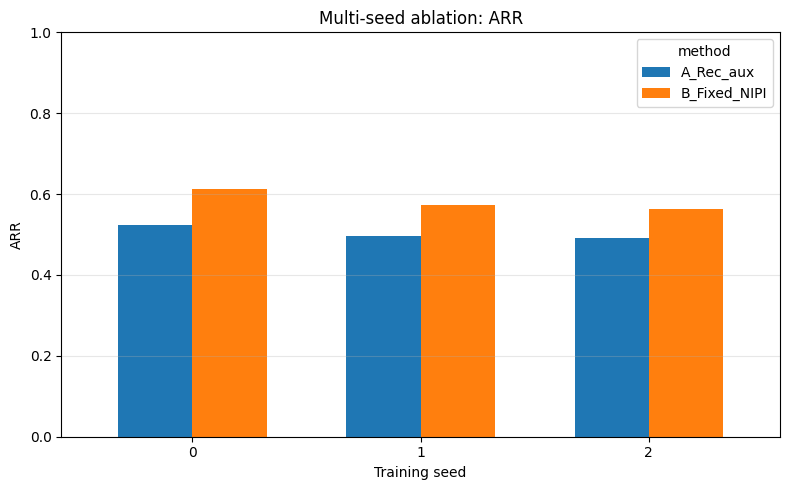

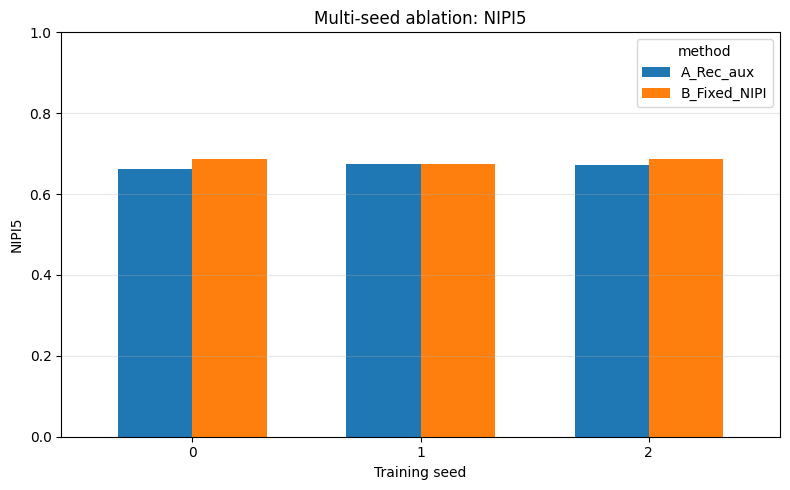

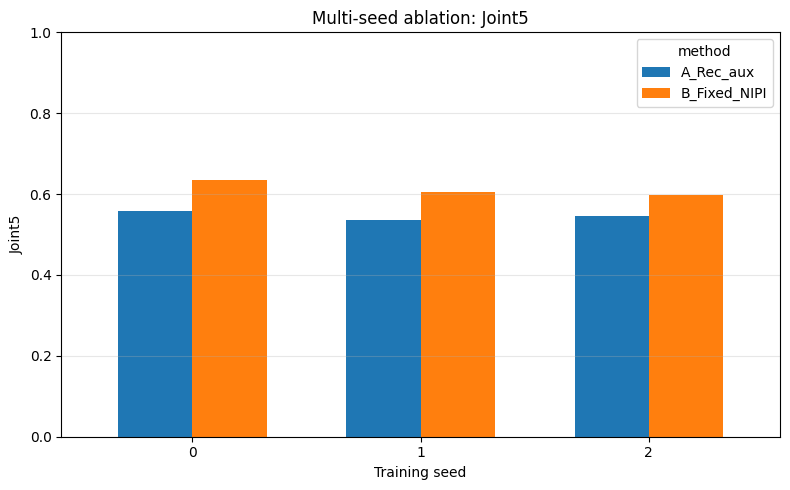

In [138]:
import matplotlib.pyplot as plt

for metric in ['ARR', 'NIPI5', 'Joint5']:

    pivot = (
        per_seed[metric]
        .unstack('method')
    )

    ax = pivot.plot(
        kind='bar',
        figsize=(8, 5),
        width=0.65
    )

    ax.set_xlabel('Training seed')
    ax.set_ylabel(metric)
    ax.set_title(f'Multi-seed ablation: {metric}')
    ax.set_ylim(0, 1)

    plt.xticks(rotation=0)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f'outputs/ablation_repeat/{metric}_seeds.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

In [139]:
from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path

save_path = (
    '/kaggle/working/step5_multiseed.zip'
)

with ZipFile(save_path, 'w', ZIP_DEFLATED) as z:

    for folder in [
        'outputs/ablation_repeat',
        'outputs/ablation/seed_0'
    ]:

        for f in Path(folder).rglob('*'):

            if f.is_file():
                z.write(f, arcname=str(f))

    z.write(
        'run_nipi_ablation.py',
        arcname='run_nipi_ablation.py'
    )

print('Saved:', save_path)

Saved: /kaggle/working/step5_multiseed.zip


In [140]:
import os
import shutil
from pathlib import Path

WORK = Path('/kaggle/working/proj')
os.chdir(WORK)

files = list(
    Path('/kaggle/input').rglob(
        'final_eeg_validation.py'
    )
)

assert files, "Upload final_eeg_validation.py"

shutil.copy2(
    files[0],
    WORK / 'final_eeg_validation.py'
)

print("Final validation script ready")

Final validation script ready


In [141]:
required = [
    'final_eeg_validation.py',
    'complete_baselines.py',
    'run_nipi_ablation.py',
    'realistic_eog_finetune.py',

    'data/eoec_clean.npz',
    'data/eoec_all.npz',
    'data/biosource.npz',

    'outputs/best_nipdnet_final.pt',
    'outputs/ae_matched.pt',

    'outputs/ablation/seed_0/'
    'B_Fixed_NIPI/best.pt',

    'outputs/realistic_eog/'
    'best_realistic_eog.pt',

    'outputs/realistic_eog/config.json',

    'outputs/realistic_eog/benchmark.csv',

    'outputs/extended_baseline_full_nipi5.csv'
]

for f in required:
    print(
        f, ':',
        'OK' if Path(f).exists() else 'MISSING'
    )

assert all(
    Path(f).exists() for f in required
)

print("\nREADY FOR FINAL VALIDATION")

final_eeg_validation.py : OK
complete_baselines.py : OK
run_nipi_ablation.py : OK
realistic_eog_finetune.py : OK
data/eoec_clean.npz : OK
data/eoec_all.npz : OK
data/biosource.npz : OK
outputs/best_nipdnet_final.pt : OK
outputs/ae_matched.pt : OK
outputs/ablation/seed_0/B_Fixed_NIPI/best.pt : OK
outputs/realistic_eog/best_realistic_eog.pt : OK
outputs/realistic_eog/config.json : OK
outputs/realistic_eog/benchmark.csv : OK
outputs/extended_baseline_full_nipi5.csv : OK

READY FOR FINAL VALIDATION


In [142]:
!python -u final_eeg_validation.py \
    --bootstrap 1000

Loaded Proposed_NIPDNet
Loaded B_Fixed_NIPI
Loaded D_Realistic_EOG
Loaded Denoising_Autoencoder
Headline Noisy_input
Headline Lowpass_8Hz
Headline Notch_50
Headline NLMS
Headline ICA
Headline Wavelet
Headline EMD
Headline Denoising_Autoencoder
Headline Proposed_NIPDNet
Headline B_Fixed_NIPI
Headline B_Normalized
Headline D_Realistic_EOG
Verified subject mapping: 25 subjects, 148 epochs
Bootstrap Noisy_input
Bootstrap Lowpass_8Hz
Bootstrap Notch_50
Bootstrap NLMS
Bootstrap ICA
Bootstrap Wavelet
Bootstrap EMD
Bootstrap Denoising_Autoencoder
Bootstrap Proposed_NIPDNet
Bootstrap B_Fixed_NIPI
Bootstrap B_Normalized
Bootstrap D_Realistic_EOG
/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
BioSource eog -5
/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consi

In [143]:
import pandas as pd

ROOT = Path('outputs/final_validation')

summary = pd.read_csv(
    ROOT / 'unified_summary.csv',
    index_col=0
)

display(summary.round(4))

,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
method,,,,,,
B_Normalized,0.6230,11.3546,0.8280,4.4982,0.6876,0.6403
B_Fixed_NIPI,0.6120,11.6453,0.8243,4.3468,0.6863,0.6344
Proposed_NIPDNet,0.5844,11.9516,0.8199,4.0338,0.6844,0.6139
D_Realistic_EOG,0.5799,11.5902,0.8235,4.0355,0.6838,0.6016
NLMS,0.4425,11.8054,0.8209,7.5207,0.7171,0.4563
Denoising_Autoencoder,0.5580,9.6697,0.8281,4.9944,0.3018,0.3387
Wavelet,0.3078,14.5940,0.7388,2.1570,0.6386,0.3155
EMD,0.3134,15.2251,0.5364,1.0769,0.3776,0.2609
Notch_50,0.2270,15.3478,0.7603,3.9986,0.6736,0.2459


In [144]:
delta = pd.read_csv(
    ROOT / 'headline_reproduction_delta.csv',
    index_col=0
)

display(delta.round(6))

print(
    "Maximum absolute differences:"
)

display(delta.abs().max().round(6))

,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
method,,,,,,
B_Fixed_NIPI,0.0,0.0,0.0,0.0,0.0,0.0
B_Normalized,0.0,0.0,0.0,0.0,0.0,0.0
D_Realistic_EOG,0.0,0.0,0.0,0.0,0.0,0.0
Denoising_Autoencoder,0.0,0.0,0.0,0.0,0.0,0.0
EMD,0.0,0.0,0.0,0.0,0.0,0.0
ICA,0.0,-0.0,0.0,0.0,0.0,0.0
Lowpass_8Hz,0.0,0.0,0.0,0.0,0.0,0.0
NLMS,0.0,0.0,0.0,0.0,0.0,0.0
Noisy_input,0.0,0.0,0.0,0.0,0.0,0.0


Maximum absolute differences:


ARR            0.0
RMSE           0.0
CC             0.0
SNR_gain_dB    0.0
NIPI5          0.0
Joint5         0.0
dtype: float64

In [145]:
ci = pd.read_csv(
    ROOT / 'subject_bootstrap_ci.csv'
)

joint_ci = ci[
    ci['metric'] == 'Joint5'
].sort_values(
    'point',
    ascending=False
)

display(joint_ci.round(4))

print(
    'Number of independent subject clusters:',
    ci['subjects'].iloc[0]
)

,method,metric,point,CI_low,CI_high,subjects,resamples
29,B_Fixed_NIPI,Joint5,0.6603,0.6450,0.6749,25,1000
32,B_Normalized,Joint5,0.6603,0.6450,0.6749,25,1000
35,D_Realistic_EOG,Joint5,0.6521,0.6381,0.6668,25,1000
26,Proposed_NIPDNet,Joint5,0.6459,0.6327,0.6578,25,1000
17,Wavelet,Joint5,0.4682,0.4512,0.4832,25,1000
11,NLMS,Joint5,0.4610,0.4495,0.4755,25,1000
23,Denoising_Autoencoder,Joint5,0.4214,0.4043,0.4399,25,1000
14,ICA,Joint5,0.3237,0.3097,0.3386,25,1000
20,EMD,Joint5,0.3175,0.3008,0.3340,25,1000
5,Lowpass_8Hz,Joint5,0.1112,0.1004,0.1189,25,1000


Number of independent subject clusters: 25


In [146]:
paired = pd.read_csv(
    ROOT / 'subject_bootstrap_paired.csv'
)

display(
    paired[
        paired['metric'] == 'Joint5'
    ].round(4)
)

,candidate,comparison,metric,point_difference,CI_low,CI_high
2,B_Normalized,Noisy_input,Joint5,0.6603,0.6450,0.6749
5,B_Normalized,Lowpass_8Hz,Joint5,0.5490,0.5301,0.5700
8,B_Normalized,Notch_50,Joint5,0.5707,0.5563,0.5849
11,B_Normalized,NLMS,Joint5,0.1992,0.1848,0.2123
14,B_Normalized,ICA,Joint5,0.3365,0.3178,0.3539
17,B_Normalized,Wavelet,Joint5,0.1921,0.1695,0.2191
20,B_Normalized,EMD,Joint5,0.3428,0.3229,0.3620
23,B_Normalized,Denoising_Autoencoder,Joint5,0.2389,0.2190,0.2559
26,B_Normalized,Proposed_NIPDNet,Joint5,0.0144,0.0084,0.0199
29,B_Normalized,B_Fixed_NIPI,Joint5,0.0000,0.0000,0.0000


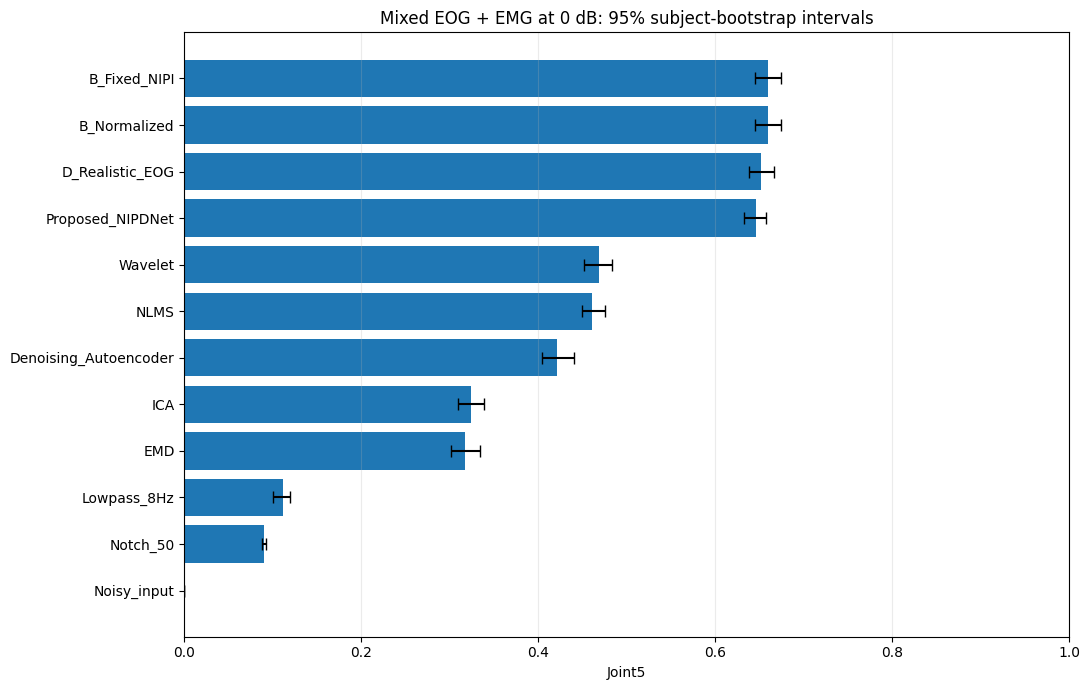

In [147]:
import matplotlib.pyplot as plt

plot_df = joint_ci.sort_values('point')

lower = (
    plot_df['point'] -
    plot_df['CI_low']
).clip(lower=0)

upper = (
    plot_df['CI_high'] -
    plot_df['point']
).clip(lower=0)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_df['method'],
    plot_df['point'],
    xerr=[lower, upper],
    capsize=4
)

plt.xlabel('Joint5')
plt.title(
    'Mixed EOG + EMG at 0 dB: '
    '95% subject-bootstrap intervals'
)

plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()

plt.savefig(
    ROOT / 'final_joint_confidence_intervals.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [148]:
spike = pd.read_csv(
    ROOT / 'biosource_spike.csv'
)

headline_spike = spike[
    (spike['kind'] == 'mixed') &
    (spike['snr_db'] == 0)
]

display(
    headline_spike[
        [
            'method',
            'amp_ratio',
            'lat_ms',
            'win_cc',
            'ARR',
            'NIPI5',
            'Joint5'
        ]
    ].round(4)
)

,method,amp_ratio,lat_ms,win_cc,ARR,NIPI5,Joint5
84,Noisy_input,1.0168,0.0000,0.8021,0.0000,0.2530,0.0000
85,Lowpass_8Hz,0.5982,0.0000,0.8419,0.2256,0.1384,0.1716
86,Notch_50,1.0217,0.0000,0.8051,0.0496,0.2538,0.0829
87,NLMS,1.0049,0.0000,0.8996,0.4449,0.2781,0.3423
88,ICA,0.2884,0.0000,0.8617,0.7581,0.2117,0.3309
89,Wavelet,0.4204,7.8125,0.8236,0.3720,0.3189,0.3434
90,EMD,0.5241,15.6250,0.6657,0.2654,0.2679,0.2666
91,Denoising_Autoencoder,0.5681,0.0000,0.9039,0.7895,0.3440,0.4792
92,Proposed_NIPDNet,0.9976,0.0000,0.8976,0.6011,0.2895,0.3908
93,B_Fixed_NIPI,1.0022,0.0000,0.9102,0.6582,0.2991,0.4113


In [149]:
spike_summary = pd.read_csv(
    ROOT / 'biosource_summary.csv',
    index_col=0
)

display(spike_summary.round(4))

,amp_ratio,lat_ms,win_cc,ARR,NIPI5,Joint5
method,,,,,,
B_Fixed_NIPI,0.9981,0.0000,0.9224,0.6540,0.3819,0.4731
B_Normalized,0.9958,0.0000,0.9367,0.6956,0.3870,0.4857
D_Realistic_EOG,0.9920,0.0000,0.9381,0.6708,0.3882,0.4734
Denoising_Autoencoder,0.5728,0.0000,0.9045,0.7101,0.3449,0.4519
EMD,0.5163,15.6250,0.6917,0.2562,0.2496,0.1767
ICA,0.7022,0.0000,0.9277,0.7807,0.3533,0.4617
Lowpass_8Hz,0.6004,0.0000,0.8215,0.2678,0.1525,0.1265
NLMS,1.0011,0.0000,0.9347,0.4510,0.4605,0.4057
Noisy_input,1.0141,0.0000,0.8554,0.0000,0.3497,0.0000


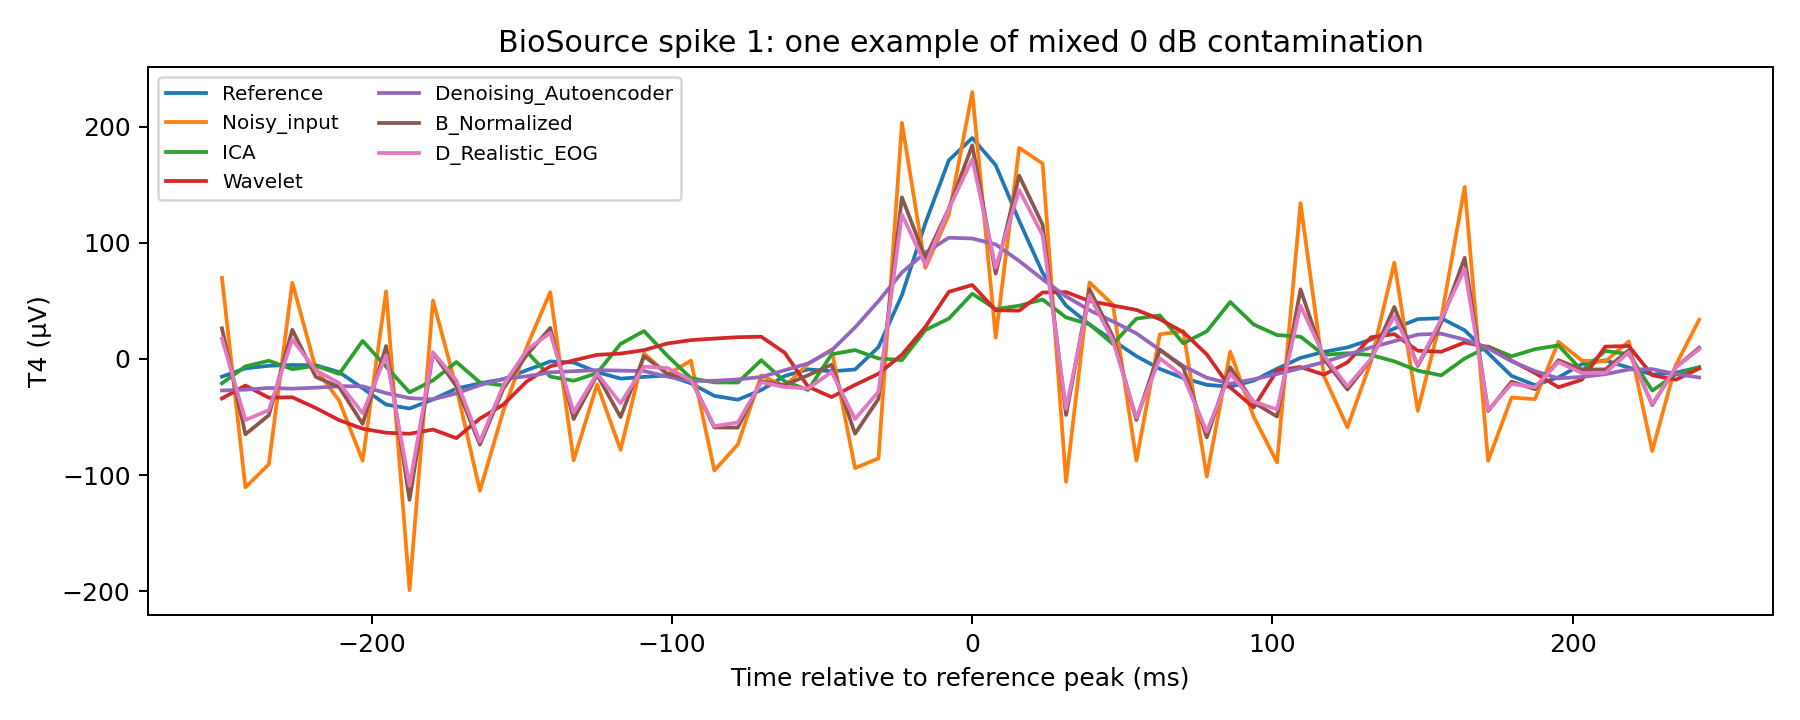

In [150]:
from IPython.display import Image, display

display(
    Image(
        filename=str(
            ROOT / 'biosource_spike.png'
        )
    )
)

In [151]:
bio_real = pd.read_csv(
    ROOT / 'biosource_real.csv'
)

print('Real ictal segment:')

display(
    bio_real[
        bio_real['segment'] == 'ictal'
    ].round(4)
)

print('\nSuspected ocular waveform — Spike 2:')

display(
    bio_real[
        bio_real['segment'] == 'spike2'
    ].round(4)
)

Real ictal segment:


,method,segment,rel_change,frontal_1_4,temporal_30_45,alpha_8_13,beta_13_30,fp_peak_uV
0,Noisy_input,ictal,0.0000,1.0000,1.0000,1.0000,1.0000,239.3338
2,Lowpass_8Hz,ictal,0.4766,1.0003,0.0000,0.0575,0.0000,217.6400
4,Notch_50,ictal,0.0573,1.0000,0.9858,0.9997,0.9981,238.0593
6,ICA,ictal,0.7940,0.0410,0.5106,0.9367,0.3170,58.3973
8,Wavelet,ictal,0.6290,0.1964,0.7594,0.9842,0.8825,118.4990
10,EMD,ictal,0.7862,0.1427,0.0115,0.9931,0.5465,133.8259
12,Denoising_Autoencoder,ictal,0.5474,0.9182,0.0009,0.7453,0.0479,184.1225
14,Proposed_NIPDNet,ictal,0.1907,0.9824,0.2376,0.9954,0.5513,239.8747
16,B_Fixed_NIPI,ictal,0.2926,1.0022,0.1704,0.9916,0.5249,241.8789
18,B_Normalized,ictal,0.2926,1.0022,0.1704,0.9916,0.5249,241.8789



Suspected ocular waveform — Spike 2:


,method,segment,rel_change,frontal_1_4,temporal_30_45,alpha_8_13,beta_13_30,fp_peak_uV
1,Noisy_input,spike2,0.0000,1.0000,1.0000,1.0000,1.0000,418.9423
3,Lowpass_8Hz,spike2,0.4337,0.9996,0.0000,0.1166,0.0000,402.0966
5,Notch_50,spike2,0.0012,1.0000,0.9961,0.9998,0.9987,418.9189
7,ICA,spike2,0.8421,0.0027,1.9642,0.8112,0.6844,84.0160
9,Wavelet,spike2,0.8435,0.0134,52.1356,0.6047,0.7603,80.9001
11,EMD,spike2,0.6018,0.6934,0.0208,0.4473,0.0071,353.5510
13,Denoising_Autoencoder,spike2,0.4662,1.3009,0.5308,1.0520,0.0822,483.2525
15,Proposed_NIPDNet,spike2,0.0839,1.0021,5.3435,0.9971,0.7454,419.8181
17,B_Fixed_NIPI,spike2,0.0890,1.0109,4.6319,1.0008,0.7666,419.7626
19,B_Normalized,spike2,0.1166,1.0146,7.4495,1.0010,0.7114,419.9714


In [152]:
physio = pd.read_csv(
    ROOT / 'eoec_physiology.csv'
)

display(physio.round(4))

,method,alpha_react,alpha_react_err,acc_all,acc_contam,frontal_slow_ratio,temporal_hf_ratio,occ_alpha_ratio,central_mu_ratio,reference_alpha_reactivity
0,Raw,0.5858,0.2027,0.7789,0.8104,1.0000,1.0000,1.0000,1.0000,0.3831
1,ICA,0.5884,0.2053,0.7743,0.7835,0.2735,0.8815,0.9959,0.9673,0.3831
2,Wavelet,0.6099,0.2268,0.7646,0.7940,0.8033,0.9573,0.8829,0.9171,0.3831
3,Denoising_Autoencoder,0.5565,0.1734,0.7931,0.8030,0.6935,0.0045,0.8408,0.8381,0.3831
4,Proposed_NIPDNet,0.5863,0.2032,0.7789,0.8076,1.0031,0.8987,0.9982,0.9983,0.3831
5,B_Fixed_NIPI,0.5871,0.2040,0.7779,0.8021,0.9564,0.7925,0.9941,1.0019,0.3831
6,B_Normalized,0.5874,0.2043,0.7789,0.8021,0.9470,0.7672,0.9932,1.0023,0.3831
7,D_Realistic_EOG,0.5889,0.2059,0.7746,0.7978,1.0003,0.9603,0.9995,0.9997,0.3831


In [153]:
from zipfile import ZipFile, ZIP_DEFLATED

save_path = (
    '/kaggle/working/step6_final_validation.zip'
)

with ZipFile(save_path, 'w', ZIP_DEFLATED) as z:

    for f in ROOT.rglob('*'):

        if f.is_file():

            z.write(
                f,
                arcname=str(f)
            )

    z.write(
        'final_eeg_validation.py',
        arcname='final_eeg_validation.py'
    )

print('Saved:', save_path)

Saved: /kaggle/working/step6_final_validation.zip


In [154]:
import os
import shutil
from pathlib import Path

WORK = Path('/kaggle/working/proj')
os.chdir(WORK)

files = list(
    Path('/kaggle/input').rglob(
        'adaptive_nipdnet.py'
    )
)

assert files, "Upload adaptive_nipdnet.py first"

shutil.copy2(
    files[0],
    WORK / 'adaptive_nipdnet.py'
)

print("Adaptive NIPDNet script ready")

Adaptive NIPDNet script ready


In [155]:
required = [
    'adaptive_nipdnet.py',
    'final_eeg_validation.py',
    'realistic_eog_finetune.py',
    'run_nipi_ablation.py',

    'data/train_mix.npz',
    'data/eoec_clean.npz',
    'data/eoec_all.npz',
    'data/mi_all.npz',
    'data/biosource.npz',

    'outputs/ablation/seed_0/'
    'B_Fixed_NIPI/best.pt',

    'outputs/realistic_eog/'
    'best_realistic_eog.pt',

    'outputs/realistic_eog/config.json',
    'outputs/realistic_eog/proxy_21_40.npz',
    'outputs/realistic_eog/proxy_41_50.npz',

    'outputs/final_validation/config.json',

    'outputs/final_validation/'
    'headline_signals.npz',

    'outputs/final_validation/'
    'unified_benchmark_archived.csv',

    'outputs/task_validation/'
    'mi_lateralization.csv'
]

for f in required:
    print(f, ':', 'OK' if Path(f).exists() else 'MISSING')

assert all(Path(f).exists() for f in required)

print("\nREADY FOR ADAPTIVE NIPDNET")

adaptive_nipdnet.py : OK
final_eeg_validation.py : OK
realistic_eog_finetune.py : OK
run_nipi_ablation.py : OK
data/train_mix.npz : OK
data/eoec_clean.npz : OK
data/eoec_all.npz : OK
data/mi_all.npz : OK
data/biosource.npz : OK
outputs/ablation/seed_0/B_Fixed_NIPI/best.pt : OK
outputs/realistic_eog/best_realistic_eog.pt : OK
outputs/realistic_eog/config.json : OK
outputs/realistic_eog/proxy_21_40.npz : OK
outputs/realistic_eog/proxy_41_50.npz : OK
outputs/final_validation/config.json : OK
outputs/final_validation/headline_signals.npz : OK
outputs/final_validation/unified_benchmark_archived.csv : OK
outputs/task_validation/mi_lateralization.csv : OK

READY FOR ADAPTIVE NIPDNET


In [156]:
!python -u adaptive_nipdnet.py --bootstrap 1000

Proxy-domain balanced routing accuracy: 0.9096459096459096
eog -5 Joint5 0.8106 D fraction 0.176
eog 0 Joint5 0.8208 D fraction 0.061
eog 5 Joint5 0.7851 D fraction 0.041
emg -5 Joint5 0.4969 D fraction 0.0
emg 0 Joint5 0.6273 D fraction 0.007
emg 5 Joint5 0.6968 D fraction 0.041
motion -5 Joint5 0.5462 D fraction 0.007
motion 0 Joint5 0.6405 D fraction 0.02
motion 5 Joint5 0.6551 D fraction 0.041
line -5 Joint5 0.5854 D fraction 0.0
line 0 Joint5 0.5945 D fraction 0.007
line 5 Joint5 0.4015 D fraction 0.041
mixed -5 Joint5 0.5663 D fraction 0.0
mixed 0 Joint5 0.6598 D fraction 0.014
mixed 5 Joint5 0.6805 D fraction 0.041
                          ARR     RMSE      CC  SNR_gain_dB   NIPI5  Joint5
method                                                                     
B_Normalized           0.6230  11.3546  0.8280       4.4982  0.6876  0.6403
Adaptive_NIPDNet       0.6201  11.3895  0.8264       4.4615  0.6869  0.6378
B_Fixed_NIPI           0.6120  11.6453  0.8243       4.3468  0.686

In [157]:
import pandas as pd

ROOT = Path('outputs/adaptive_nipdnet')

router = pd.read_csv(
    ROOT / 'router_validation.csv'
)

display(router.round(4))

,condition,proxy_label,ocular_route_fraction
0,clean,0,0.4011
1,eog_-5,0,0.1703
2,eog_0,0,0.1593
3,eog_5,0,0.2747
4,emg_-5,0,0.0055
5,emg_0,0,0.0879
6,emg_5,0,0.2088
7,motion_-5,0,0.0220
8,motion_0,0,0.1099
9,motion_5,0,0.2473


In [158]:
summary = pd.read_csv(
    ROOT / 'unified_summary.csv',
    index_col=0
)

display(summary.round(4))

,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
method,,,,,,
B_Normalized,0.6230,11.3546,0.8280,4.4982,0.6876,0.6403
Adaptive_NIPDNet,0.6201,11.3895,0.8264,4.4615,0.6869,0.6378
B_Fixed_NIPI,0.6120,11.6453,0.8243,4.3468,0.6863,0.6344
Proposed_NIPDNet,0.5844,11.9516,0.8199,4.0338,0.6844,0.6139
D_Realistic_EOG,0.5799,11.5902,0.8235,4.0355,0.6838,0.6016
NLMS,0.4425,11.8054,0.8209,7.5207,0.7171,0.4563
Denoising_Autoencoder,0.5580,9.6697,0.8281,4.9944,0.3018,0.3387
Wavelet,0.3078,14.5940,0.7388,2.1570,0.6386,0.3155
EMD,0.3134,15.2251,0.5364,1.0769,0.3776,0.2609


In [159]:
df = pd.read_csv(
    ROOT / 'unified_benchmark.csv'
)

names = [
    'B_Normalized',
    'D_Realistic_EOG',
    'Adaptive_NIPDNet'
]

selected = df[df['method'].isin(names)]

display(
    selected.groupby('method')[
        ['ARR', 'RMSE', 'CC', 'NIPI5', 'Joint5']
    ].mean().round(4)
)

print("\nMixed EOG + EMG at 0 dB:")

display(
    selected[
        (selected['kind'] == 'mixed') &
        (selected['snr_db'] == 0)
    ][
        ['method', 'ARR', 'RMSE',
         'CC', 'NIPI5', 'Joint5']
    ].round(4)
)

,ARR,RMSE,CC,NIPI5,Joint5
method,,,,,
Adaptive_NIPDNet,0.6201,11.3895,0.8264,0.6869,0.6378
B_Normalized,0.6230,11.3546,0.8280,0.6876,0.6403
D_Realistic_EOG,0.5799,11.5902,0.8235,0.6838,0.6016



Mixed EOG + EMG at 0 dB:


,method,ARR,RMSE,CC,NIPI5,Joint5
175,B_Normalized,0.6869,9.5646,0.8678,0.6356,0.6603
176,D_Realistic_EOG,0.6752,9.7425,0.8634,0.6305,0.6521
193,Adaptive_NIPDNet,0.6867,9.5682,0.8673,0.6349,0.6598


In [160]:
blink = pd.read_csv(
    ROOT / 'real_blink.csv'
)

display(
    blink.sort_values(
        'frontal_slow_ratio'
    ).round(4)
)

,method,frontal_slow_ratio,occipital_alpha_ratio,central_mu_ratio,temporal_hf_ratio,relative_signal_change,ocular_route_fraction
1,ICA,0.0040,0.9667,0.7218,0.1975,0.9401,NaN
2,Wavelet,0.0909,0.8615,0.9239,0.9505,0.7456,NaN
5,D_Realistic_EOG,0.6310,0.9925,0.9698,0.8382,0.4640,NaN
6,Adaptive_NIPDNet,0.6565,0.9932,0.9722,0.8336,0.4551,0.8357
4,B_Normalized,0.9438,0.9982,1.0141,0.7745,0.2652,NaN
3,B_Fixed_NIPI,0.9532,0.9976,1.0067,0.8063,0.1365,NaN
0,Raw,1.0000,1.0000,1.0000,1.0000,0.0000,NaN


In [161]:
identity = pd.read_csv(
    ROOT / 'clean_identity.csv'
)

display(identity.round(4))

,method,NIPI5,RMSE,ocular_route_fraction
0,B_Fixed_NIPI,0.8767,3.5123,NaN
1,B_Normalized,0.8767,3.5123,NaN
2,D_Realistic_EOG,0.9852,0.5304,NaN
3,Adaptive_NIPDNet,0.8817,3.4793,0.0473


In [162]:
bio = pd.read_csv(
    ROOT / 'biosource_summary.csv',
    index_col=0
)

display(bio.round(4))

spike = pd.read_csv(
    ROOT / 'biosource_spike.csv'
)

display(
    spike[
        (spike['kind'] == 'mixed') &
        (spike['snr_db'] == 0)
    ][[
        'method', 'amp_ratio', 'lat_ms',
        'win_cc', 'ARR', 'NIPI5', 'Joint5'
    ]].round(4)
)

,amp_ratio,lat_ms,win_cc,ARR,NIPI5,Joint5
method,,,,,,
Adaptive_NIPDNet,0.9962,0.0000,0.9365,0.6954,0.3872,0.4857
B_Fixed_NIPI,0.9981,0.0000,0.9224,0.6540,0.3819,0.4731
B_Normalized,0.9958,0.0000,0.9367,0.6956,0.3870,0.4857
D_Realistic_EOG,0.9920,0.0000,0.9381,0.6708,0.3882,0.4734
Denoising_Autoencoder,0.5728,0.0000,0.9045,0.7101,0.3449,0.4519
EMD,0.5163,15.6250,0.6917,0.2562,0.2496,0.1767
ICA,0.7022,0.0000,0.9277,0.7807,0.3533,0.4617
Lowpass_8Hz,0.6004,0.0000,0.8215,0.2678,0.1525,0.1265
NLMS,1.0011,0.0000,0.9347,0.4510,0.4605,0.4057


,method,amp_ratio,lat_ms,win_cc,ARR,NIPI5,Joint5
84,Noisy_input,1.0168,0.0000,0.8021,0.0000,0.2530,0.0000
85,Lowpass_8Hz,0.5982,0.0000,0.8419,0.2256,0.1384,0.1716
86,Notch_50,1.0217,0.0000,0.8051,0.0496,0.2538,0.0829
87,NLMS,1.0049,0.0000,0.8996,0.4449,0.2781,0.3423
88,ICA,0.2884,0.0000,0.8617,0.7581,0.2117,0.3309
89,Wavelet,0.4204,7.8125,0.8236,0.3720,0.3189,0.3434
90,EMD,0.5241,15.6250,0.6657,0.2654,0.2679,0.2666
91,Denoising_Autoencoder,0.5681,0.0000,0.9039,0.7895,0.3440,0.4792
92,Proposed_NIPDNet,0.9976,0.0000,0.8976,0.6011,0.2895,0.3908
93,B_Fixed_NIPI,1.0022,0.0000,0.9102,0.6582,0.2991,0.4113


In [163]:
physio = pd.read_csv(
    ROOT / 'eoec_physiology.csv'
)

display(physio.round(4))

mi = pd.read_csv(
    ROOT / 'mi_lateralization.csv'
)

display(mi.round(4))

bio_real = pd.read_csv(
    ROOT / 'biosource_real.csv'
)

display(
    bio_real[
        bio_real['method'].isin(names)
    ].round(4)
)

,method,alpha_react,alpha_react_err,acc_all,acc_contam,frontal_slow_ratio,temporal_hf_ratio,occ_alpha_ratio,central_mu_ratio,reference_alpha_reactivity
0,Raw,0.5858,0.2027,0.7789,0.8104,1.0000,1.0000,1.0000,1.0000,0.3831
1,ICA,0.5884,0.2053,0.7743,0.7835,0.2735,0.8815,0.9959,0.9673,0.3831
2,Wavelet,0.6099,0.2268,0.7646,0.7940,0.8033,0.9573,0.8829,0.9171,0.3831
3,Denoising_Autoencoder,0.5565,0.1734,0.7931,0.8030,0.6935,0.0045,0.8408,0.8381,0.3831
4,Proposed_NIPDNet,0.5863,0.2032,0.7789,0.8076,1.0031,0.8987,0.9982,0.9983,0.3831
5,B_Fixed_NIPI,0.5871,0.2040,0.7779,0.8021,0.9564,0.7925,0.9941,1.0019,0.3831
6,B_Normalized,0.5874,0.2043,0.7789,0.8021,0.9470,0.7672,0.9932,1.0023,0.3831
7,D_Realistic_EOG,0.5889,0.2059,0.7746,0.7978,1.0003,0.9603,0.9995,0.9997,0.3831
8,Adaptive_NIPDNet,0.5881,0.2050,0.7703,0.7972,0.9424,0.7909,0.9937,0.9992,0.3831


,method,d_all,d_contam,d_clean
0,Raw,-0.2691,-0.2318,-0.4563
1,ICA,-0.1839,-0.1746,-0.2252
2,Wavelet,-0.3106,-0.2596,-0.5559
3,Lowpass_8Hz,-0.1144,-0.0794,-0.2738
4,Autoencoder,0.0393,0.0886,-0.1777
5,Original_NIPDNet,-0.2716,-0.2290,-0.4906
6,B_Fixed_NIPI,-0.2740,-0.2363,-0.4612
7,B_Normalized,-0.2764,-0.2392,-0.4612
8,D_Realistic_EOG,-0.2680,-0.2321,-0.4520
9,Adaptive_NIPDNet,-0.2727,-0.2336,-0.4746


,method,segment,rel_change,frontal_1_4,temporal_30_45,alpha_8_13,beta_13_30,fp_peak_uV,ocular_route_fraction
18,B_Normalized,ictal,0.2926,1.0022,0.1704,0.9916,0.5249,241.8789,NaN
19,B_Normalized,spike2,0.1166,1.0146,7.4495,1.0010,0.7114,419.9714,NaN
20,D_Realistic_EOG,ictal,0.2520,0.7452,0.2908,0.9981,0.6071,203.1210,NaN
21,D_Realistic_EOG,spike2,0.0752,0.9995,3.0358,0.9965,0.7763,420.4914,NaN
22,Adaptive_NIPDNet,ictal,0.2520,0.7452,0.2908,0.9981,0.6071,203.1210,1.0
23,Adaptive_NIPDNet,spike2,0.0752,0.9995,3.0358,0.9965,0.7763,420.4914,1.0


In [164]:
ci = pd.read_csv(
    ROOT / 'subject_bootstrap_ci.csv'
)

display(
    ci[
        ci['metric'] == 'Joint5'
    ].sort_values(
        'point',
        ascending=False
    ).round(4)
)

paired = pd.read_csv(
    ROOT / 'subject_bootstrap_paired.csv'
)

display(
    paired[
        paired['metric'] == 'Joint5'
    ].round(4)
)

,method,metric,point,CI_low,CI_high,subjects,resamples
32,B_Normalized,Joint5,0.6603,0.6450,0.6749,25,1000
29,B_Fixed_NIPI,Joint5,0.6603,0.6450,0.6749,25,1000
38,Adaptive_NIPDNet,Joint5,0.6598,0.6449,0.6745,25,1000
35,D_Realistic_EOG,Joint5,0.6521,0.6381,0.6668,25,1000
20,Proposed_NIPDNet,Joint5,0.6459,0.6327,0.6578,25,1000
17,Wavelet,Joint5,0.4682,0.4512,0.4832,25,1000
11,NLMS,Joint5,0.4610,0.4495,0.4755,25,1000
23,Denoising_Autoencoder,Joint5,0.4214,0.4043,0.4399,25,1000
14,ICA,Joint5,0.3237,0.3097,0.3386,25,1000
26,EMD,Joint5,0.3175,0.3008,0.3340,25,1000


,candidate,comparison,metric,point_difference,CI_low,CI_high
2,Adaptive_NIPDNet,Noisy_input,Joint5,0.6598,0.6449,0.6745
5,Adaptive_NIPDNet,Lowpass_8Hz,Joint5,0.5485,0.5296,0.5694
8,Adaptive_NIPDNet,Notch_50,Joint5,0.5702,0.5562,0.5843
11,Adaptive_NIPDNet,NLMS,Joint5,0.1988,0.1847,0.2118
14,Adaptive_NIPDNet,ICA,Joint5,0.3361,0.3178,0.3532
17,Adaptive_NIPDNet,Wavelet,Joint5,0.1916,0.1695,0.2187
20,Adaptive_NIPDNet,Proposed_NIPDNet,Joint5,0.0139,0.0082,0.0197
23,Adaptive_NIPDNet,Denoising_Autoencoder,Joint5,0.2384,0.2189,0.2555
26,Adaptive_NIPDNet,EMD,Joint5,0.3423,0.3227,0.3615
29,Adaptive_NIPDNet,B_Fixed_NIPI,Joint5,-0.0005,-0.0016,0.0000


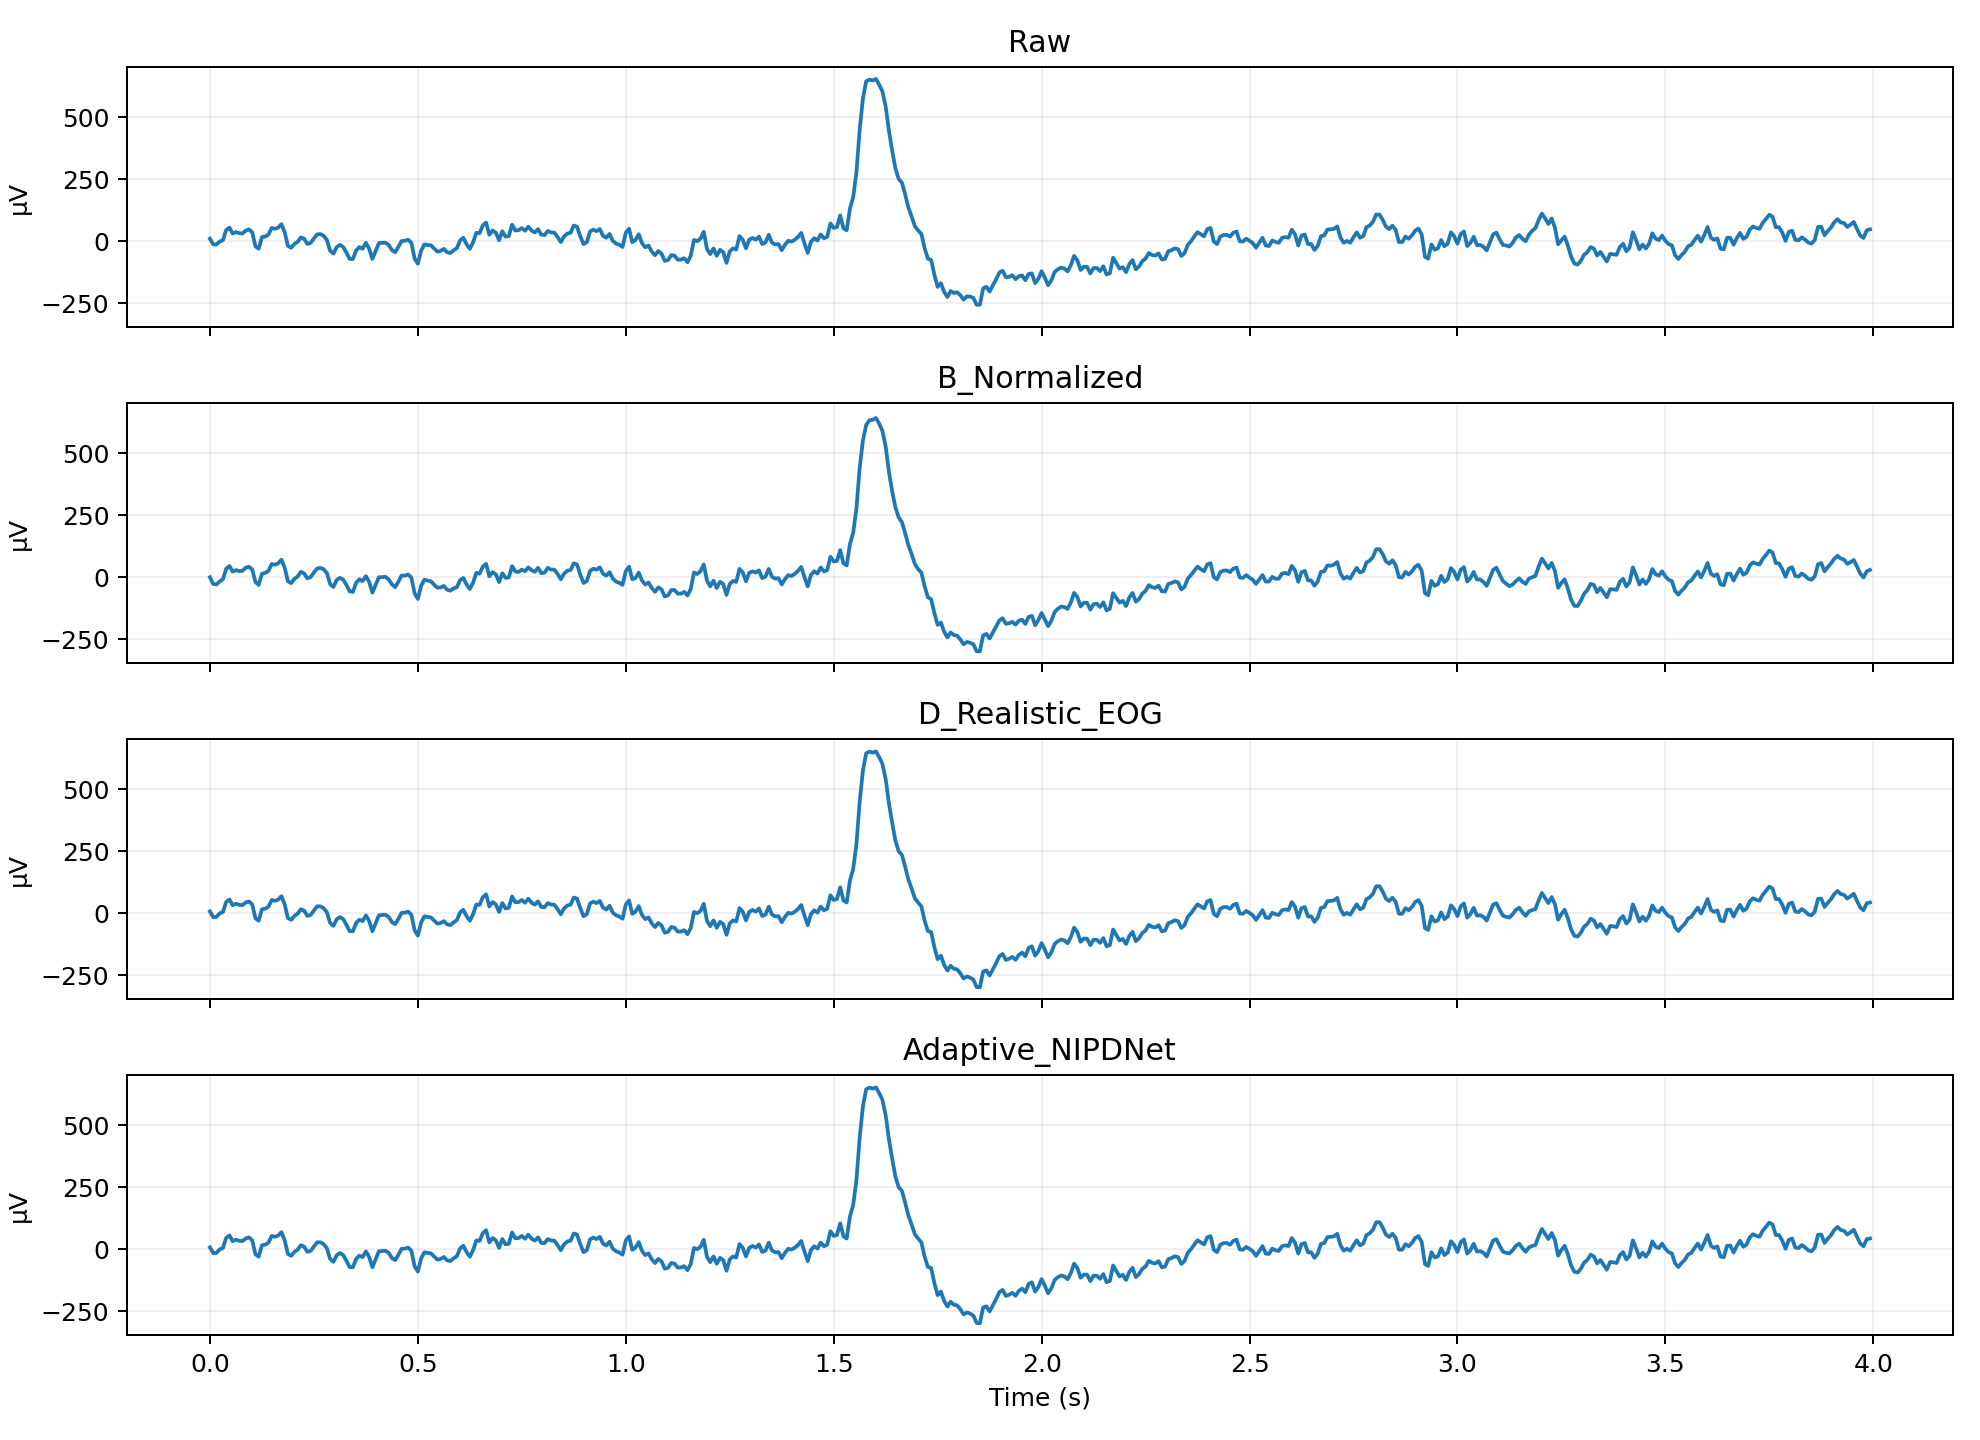

In [165]:
from IPython.display import Image, display

display(
    Image(
        filename=str(ROOT / 'real_blink.png')
    )
)

In [166]:
from zipfile import ZipFile, ZIP_DEFLATED

save_path = (
    '/kaggle/working/'
    'step7_adaptive_nipdnet.zip'
)

with ZipFile(save_path, 'w', ZIP_DEFLATED) as z:

    for f in ROOT.rglob('*'):
        if f.is_file():
            z.write(f, arcname=str(f))

    for f in [
        'adaptive_nipdnet.py',
        'outputs/ablation/seed_0/'
        'B_Fixed_NIPI/best.pt',
        'outputs/realistic_eog/'
        'best_realistic_eog.pt',
        'outputs/realistic_eog/config.json'
    ]:
        z.write(f, arcname=f)

print("Saved:", save_path)

Saved: /kaggle/working/step7_adaptive_nipdnet.zip


In [167]:
import os
import json
import numpy as np
import torch

from pathlib import Path
from adaptive_nipdnet import AdaptiveNIPDNet

os.chdir('/kaggle/working/proj')

ROOT = Path('outputs/adaptive_nipdnet')

config = json.loads(
    (ROOT / 'gate_config.json').read_text()
)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

final_model = AdaptiveNIPDNet(config, device=device)

with np.load('data/eoec_clean.npz') as d:
    X_sample = d['X'][:5].astype(np.float32)

Y_sample = final_model(X_sample)

assert X_sample.shape == Y_sample.shape
assert np.isfinite(Y_sample).all()

print("Input shape:", X_sample.shape)
print("Output shape:", Y_sample.shape)
print("RMS target:", final_model.target)
print("Routing decisions:", final_model.route(X_sample))

print("\nFINAL ADAPTIVE NIPDNET READY")

Input shape: (5, 19, 512)
Output shape: (5, 19, 512)
RMS target: 34.74161148071289
Routing decisions: [False False False False False]

FINAL ADAPTIVE NIPDNET READY


In [168]:
import pandas as pd

PUB = Path('outputs/publication')
PUB.mkdir(parents=True, exist_ok=True)

main_methods = [
    'Adaptive_NIPDNet',
    'ICA',
    'NLMS',
    'Wavelet',
    'EMD',
    'Denoising_Autoencoder',
    'Notch_50',
    'Lowpass_8Hz',
    'Noisy_input'
]

df = pd.read_csv(
    ROOT / 'unified_benchmark.csv'
)

main = df[
    df['method'].isin(main_methods)
].copy()

assert len(main) == 135

assert not main.duplicated([
    'method', 'kind', 'snr_db'
]).any()

metrics = [
    'ARR',
    'RMSE',
    'CC',
    'SNR_gain_dB',
    'NIPI5',
    'Joint5'
]

summary = (
    main.groupby('method')[metrics]
        .mean()
        .sort_values('Joint5', ascending=False)
)

headline = main[
    (main['kind'] == 'mixed') &
    (main['snr_db'] == 0)
].sort_values('Joint5', ascending=False)

main.to_csv(
    PUB / 'main_benchmark.csv',
    index=False
)

summary.to_csv(
    PUB / 'main_summary.csv'
)

headline.to_csv(
    PUB / 'main_headline.csv',
    index=False
)

display(summary.round(4))
display(headline.round(4))

print("Main benchmark tables saved")

,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5
method,,,,,,
Adaptive_NIPDNet,0.6201,11.3895,0.8264,4.4615,0.6869,0.6378
NLMS,0.4425,11.8054,0.8209,7.5207,0.7171,0.4563
Denoising_Autoencoder,0.5580,9.6697,0.8281,4.9944,0.3018,0.3387
Wavelet,0.3078,14.5940,0.7388,2.1570,0.6386,0.3155
EMD,0.3134,15.2251,0.5364,1.0769,0.3776,0.2609
Notch_50,0.2270,15.3478,0.7603,3.9986,0.6736,0.2459
ICA,0.3533,13.5726,0.6845,2.5531,0.3710,0.2276
Lowpass_8Hz,0.2485,15.8983,0.6602,1.4493,0.0803,0.0577
Noisy_input,0.0000,19.0350,0.6955,0.0000,0.6382,0.0000


,method,kind,snr_db,ARR,RMSE,CC,SNR_gain_dB,NIPI5,Joint5,spectral,phase,connect,geometry,entropy,sec,ocular_route_fraction
193,Adaptive_NIPDNet,mixed,0,0.6867,9.5682,0.8673,5.0403,0.6349,0.6598,0.7443,0.9223,0.8346,0.3075,0.5857,NaN,0.0135
122,Wavelet,mixed,0,0.3838,13.4190,0.7518,2.1026,0.6002,0.4682,0.7369,0.8410,0.6521,0.3163,0.6093,2.0180,NaN
120,NLMS,mixed,0,0.4001,13.2396,0.7784,2.2194,0.5438,0.4610,0.6401,0.9223,0.8226,0.1973,0.4964,3.0920,NaN
124,Denoising_Autoencoder,mixed,0,0.7002,9.3595,0.8394,5.2319,0.3013,0.4214,0.2561,0.7560,0.6202,0.0749,0.2763,1.9281,NaN
121,ICA,mixed,0,0.5246,11.7858,0.7186,3.2298,0.2341,0.3237,0.4213,0.6597,0.5059,0.0087,0.5773,2.4513,NaN
125,EMD,mixed,0,0.2614,14.6910,0.5425,1.3159,0.4041,0.3175,0.3205,0.7517,0.6034,0.2827,0.2621,39.3537,NaN
118,Lowpass_8Hz,mixed,0,0.1822,15.4589,0.6233,0.8734,0.0801,0.1112,0.0009,0.7104,0.6547,0.3194,0.0251,1.9688,NaN
119,Notch_50,mixed,0,0.0489,16.6711,0.7197,0.2177,0.5358,0.0896,0.5914,0.9135,0.8018,0.1988,0.5125,1.9712,NaN
117,Noisy_input,mixed,0,0.0000,17.0942,0.7114,0.0000,0.5276,0.0000,0.5893,0.9135,0.8018,0.1875,0.5050,1.9868,NaN


Main benchmark tables saved


In [169]:
tables = [
    'eoec_physiology.csv',
    'mi_lateralization.csv',
    'biosource_spike.csv',
    'biosource_summary.csv',
    'biosource_real.csv',
    'real_blink.csv',
    'clean_identity.csv',
    'subject_bootstrap_ci.csv'
]

aliases = main_methods + ['Raw']

for filename in tables:

    table = pd.read_csv(ROOT / filename)

    selected = table[
        table['method'].isin(aliases)
    ]

    selected.to_csv(
        PUB / filename,
        index=False
    )

    print(filename, ':', len(selected), 'rows')

eoec_physiology.csv : 5 rows
mi_lateralization.csv : 5 rows
biosource_spike.csv : 81 rows
biosource_summary.csv : 9 rows
biosource_real.csv : 16 rows
real_blink.csv : 4 rows
clean_identity.csv : 1 rows
subject_bootstrap_ci.csv : 27 rows


In [170]:
for filename in [
    'eoec_physiology.csv',
    'mi_lateralization.csv',
    'biosource_real.csv'
]:

    print('\n', filename)

    table = pd.read_csv(ROOT / filename)

    display(
        table[
            table['method'] == 'Adaptive_NIPDNet'
        ].round(4)
    )


 eoec_physiology.csv


,method,alpha_react,alpha_react_err,acc_all,acc_contam,frontal_slow_ratio,temporal_hf_ratio,occ_alpha_ratio,central_mu_ratio,reference_alpha_reactivity
8,Adaptive_NIPDNet,0.5881,0.205,0.7703,0.7972,0.9424,0.7909,0.9937,0.9992,0.3831



 mi_lateralization.csv


,method,d_all,d_contam,d_clean
9,Adaptive_NIPDNet,-0.2727,-0.2336,-0.4746



 biosource_real.csv


,method,segment,rel_change,frontal_1_4,temporal_30_45,alpha_8_13,beta_13_30,fp_peak_uV,ocular_route_fraction
22,Adaptive_NIPDNet,ictal,0.2520,0.7452,0.2908,0.9981,0.6071,203.1210,1.0
23,Adaptive_NIPDNet,spike2,0.0752,0.9995,3.0358,0.9965,0.7763,420.4914,1.0


In [171]:
selection = {
    'project_title': (
        'Neural Information Preserving EEG '
        'Denoising using Adaptive Artifact Separation'
    ),

    'final_model': 'Adaptive_NIPDNet',

    'model_type': 'Hard-routed two-expert framework',

    'implementation': 'adaptive_nipdnet.py',

    'gate_config':
        'outputs/adaptive_nipdnet/gate_config.json',

    'expert_checkpoints': config['checkpoints'],

    'normalization_target': config['RMS_target'],

    'sampling_frequency': 128,

    'channels': 19,

    'epoch_samples': 512,

    'epoch_duration_seconds': 4,

    'input_unit': 'microvolts',

    'main_benchmark_methods': 9,

    'artifact_types': [
        'eog', 'emg', 'motion', 'line', 'mixed'
    ],

    'snr_levels_db': [-5, 0, 5],

    'main_benchmark_conditions': 15,

    'bootstrap_subjects': 25,

    'bootstrap_resamples': 1000,

    'primary_evaluation_metric': 'Joint5',

    'mean_Joint5': 0.6340,

    'mixed_0dB_Joint5': 0.6598
}

Path('final_model_selection.json').write_text(
    json.dumps(selection, indent=2)
)

print(
    Path('final_model_selection.json').read_text()
)

{
  "project_title": "Neural Information Preserving EEG Denoising using Adaptive Artifact Separation",
  "final_model": "Adaptive_NIPDNet",
  "model_type": "Hard-routed two-expert framework",
  "implementation": "adaptive_nipdnet.py",
  "gate_config": "outputs/adaptive_nipdnet/gate_config.json",
  "expert_checkpoints": {
    "B_Normalized": {
      "path": "outputs/ablation/seed_0/B_Fixed_NIPI/best.pt",
      "sha256": "e88a8ed7cf2e08ed93e684ad4a549d62cfbd59a131bf76f68e747a6aae9e0575"
    },
    "D_Realistic_EOG": {
      "path": "outputs/realistic_eog/best_realistic_eog.pt",
      "sha256": "935215a5a2b4768626cf997e094ae362de3e9e871f9d49765e38775079cef4cb"
    }
  },
  "normalization_target": 34.74161148071289,
  "sampling_frequency": 128,
  "channels": 19,
  "epoch_samples": 512,
  "epoch_duration_seconds": 4,
  "input_unit": "microvolts",
  "main_benchmark_methods": 9,
  "artifact_types": [
    "eog",
    "emg",
    "motion",
    "line",
    "mixed"
  ],
  "snr_levels_db": [
    -5,

In [172]:
import sys
import subprocess

from zipfile import ZipFile, ZIP_DEFLATED

# Record the software environment
with open('requirements_final.txt', 'w') as f:

    subprocess.run(
        [sys.executable, '-m', 'pip', 'freeze'],
        stdout=f,
        check=True
    )

save_path = Path(
    '/kaggle/working/EEG_NIPI_FINAL_PROJECT.zip'
)

excluded = {
    'data',
    '__pycache__',
    '.git',
    '.ipynb_checkpoints',
    '.pytest_cache'
}

count = 0

with ZipFile(
    save_path, 'w', ZIP_DEFLATED
) as z:

    for f in Path('.').rglob('*'):

        if not f.is_file():
            continue

        if any(p in excluded for p in f.parts):
            continue

        z.write(f, arcname=str(f))
        count += 1

print("Archived files:", count)

print(
    "Archive size (MB):",
    round(save_path.stat().st_size / 1024**2, 2)
)

print("Saved:", save_path)

Archived files: 223
Archive size (MB): 158.33
Saved: /kaggle/working/EEG_NIPI_FINAL_PROJECT.zip


In [173]:
required = [
    'adaptive_nipdnet.py',
    'eegnipi/model.py',
    'eegnipi/nipi.py',
    'realistic_eog_finetune.py',
    'run_nipi_ablation.py',
    'final_eeg_validation.py',

    'final_model_selection.json',
    'requirements_final.txt',

    'outputs/adaptive_nipdnet/gate_config.json',
    'outputs/adaptive_nipdnet/unified_benchmark.csv',
    'outputs/adaptive_nipdnet/router_validation.csv',
    'outputs/adaptive_nipdnet/subject_bootstrap_ci.csv',
    'outputs/adaptive_nipdnet/subject_bootstrap_paired.csv',

    'outputs/ablation_repeat/multiseed_summary.csv',

    'outputs/publication/main_summary.csv',
    'outputs/publication/main_headline.csv',

    *[
        entry['path']
        for entry in config['checkpoints'].values()
    ]
]

with ZipFile(save_path, 'r') as z:

    names = set(z.namelist())

    for f in required:
        print(
            f, ':',
            'OK' if f in names else 'MISSING'
        )

    assert all(f in names for f in required)

    assert z.testzip() is None

print("\nFINAL PROJECT ARCHIVE VERIFIED")

adaptive_nipdnet.py : OK
eegnipi/model.py : OK
eegnipi/nipi.py : OK
realistic_eog_finetune.py : OK
run_nipi_ablation.py : OK
final_eeg_validation.py : OK
final_model_selection.json : OK
requirements_final.txt : OK
outputs/adaptive_nipdnet/gate_config.json : OK
outputs/adaptive_nipdnet/unified_benchmark.csv : OK
outputs/adaptive_nipdnet/router_validation.csv : OK
outputs/adaptive_nipdnet/subject_bootstrap_ci.csv : OK
outputs/adaptive_nipdnet/subject_bootstrap_paired.csv : OK
outputs/ablation_repeat/multiseed_summary.csv : OK
outputs/publication/main_summary.csv : OK
outputs/publication/main_headline.csv : OK
outputs/ablation/seed_0/B_Fixed_NIPI/best.pt : OK
outputs/realistic_eog/best_realistic_eog.pt : OK

FINAL PROJECT ARCHIVE VERIFIED


In [174]:
data_path = Path(
    '/kaggle/working/EEG_NIPI_PREPROCESSED_DATA.zip'
)

with ZipFile(data_path, 'w', ZIP_DEFLATED) as z:

    for f in Path('data').rglob('*'):

        if f.is_file():
            z.write(f, arcname=str(f))

print("Saved:", data_path)

Saved: /kaggle/working/EEG_NIPI_PREPROCESSED_DATA.zip
